# Machine Learning and Data Science, From Data to Deployed Model

Most people meet machine learning through the algorithms: random forests, neural networks, gradient descent. But once
you build a few real projects, you notice where the time actually goes. It goes into understanding a problem well enough
to frame it, getting data into a usable shape, choosing a way to measure success, and evaluating models honestly enough
that the numbers mean something.

This post is my attempt to put the whole workflow in one place. It starts with what machine learning is and a framework
for approaching any project, moves through the core Python tools (pandas, NumPy, Matplotlib, scikit-learn), and then
puts them to work on two complete projects: predicting heart disease and predicting bulldozer auction prices. It ends with
deep learning and transfer learning, where we build an image classifier with TensorFlow and Keras.

Everything runs on current library versions, and the outputs come from actually running the code. Many older tutorials
break on today's APIs, so I've flagged those spots as I go. There's a companion Jupyter notebook with exactly the same
content if you'd rather run things as you read.

Data cleaning and feature preparation get a much deeper treatment in my
[Data Preparation for Machine Learning reference](https://github.com/rokon-uddin/data-preparation-reference), so this post
links there instead of repeating it.

## Contents

| Section | What you'll learn |
|---|---|
| [Setup](#setup) | Install, datasets, shared code |
| [1. How Machine Learning Works](#1-how-machine-learning-works) | ML vs. normal programming, AI/ML/deep learning, problem types |
| [2. A Framework for Any Machine Learning Project](#2-a-framework-for-any-machine-learning-project) | Six steps, train/validation/test, over- and underfitting |
| [3. Setting Up a Workspace](#3-setting-up-a-workspace) | conda environments and Jupyter |
| [4. Exploring Data with pandas](#4-exploring-data-with-pandas) | Load, describe, filter, clean and reshape tables |
| [5. Arrays and Maths with NumPy](#5-arrays-and-maths-with-numpy) | Arrays, broadcasting, aggregation, dot products, images as arrays |
| [6. Visualizing Data with Matplotlib](#6-visualizing-data-with-matplotlib) | Figures and axes, core plot types, plotting from pandas |
| [7. Building Models with scikit-learn](#7-building-models-with-scikit-learn) | Prepare data, fit, evaluate, tune, save; pipelines |
| [8. Worked Example: Predicting Heart Disease](#8-worked-example-predicting-heart-disease) | End-to-end classification project |
| [9. Worked Example: Predicting Bulldozer Prices](#9-worked-example-predicting-bulldozer-prices) | End-to-end time-series regression project |
| [10. Deep Learning and Transfer Learning](#10-deep-learning-and-transfer-learning) | Image classifier with TensorFlow, Keras and a pretrained network |
| [Reference](#reference) | Master cheatsheet, glossary, further reading |

<a id="setup"></a>

## Setup

```bash
pip install "scikit-learn>=1.6" pandas numpy matplotlib seaborn pillow tensorflow jupyterlab
```

The small datasets are in the `data/` folder next to this file. The bulldozer data (72 MB) and the Stanford Dogs images
(~750 MB) are downloaded by the code that needs them.

| Dataset | Where | Used for |
|---|---|---|
| Car sales (10 and 1,000 rows) | `data/car-sales*.csv` | pandas, Matplotlib, scikit-learn |
| Heart disease (303 patients, UCI Cleveland data) | `data/heart-disease.csv` | Matplotlib, scikit-learn, classification project |
| Dog photos | `data/dog-photos/` | NumPy, image classifier |
| California housing | `fetch_california_housing()` | scikit-learn regression |
| Blue Book for Bulldozers (Kaggle) | downloaded to `data/bluebook-for-bulldozers/` | regression project |
| Stanford Dogs (120 breeds) | downloaded to `data/stanford-dogs/` | image classifier |

Versions used here: Python 3.13, pandas 3.0, NumPy 2.5, scikit-learn 1.9, Matplotlib 3.11, TensorFlow 2.21 with Keras 3.

Every example below uses this setup block. In the notebook, run it first.

In [1]:
# Shared setup: imports and paths used throughout. Run this cell first.
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
DATA = Path("data")
IMAGES = Path("images")                 # animations are written here
IMAGES.mkdir(exist_ok=True)
np.random.seed(42)                      # reproducible results for the classic np.random API

print("pandas", pd.__version__, "| NumPy", np.__version__)

pandas 3.0.5 | NumPy 2.5.3


<a id="1-how-machine-learning-works"></a>

## 1. How Machine Learning Works

Before any code, it helps to be precise about what machine learning is, how it relates to the other terms that get thrown
around, and which kinds of problems it solves.

<a id="rules-written-by-data"></a>

### Rules Written by Data

In normal programming you write the rules. You give the computer an input and a set of instructions, and it produces an
output. A recipe is a good analogy: ingredients plus steps give you a dish.

Machine learning flips that around. You give the computer inputs *and* the outputs you want, and it works out the
instructions for itself. That's useful wherever writing the rules by hand is impractical: recognizing faces, recommending
the next video, estimating a fair price for a used machine.

```mermaid
flowchart LR
    subgraph Traditional programming
        A[Input] --> P[Rules you write] --> O[Output]
    end
    subgraph Machine learning
        I[Inputs] --> M[Algorithm]
        Y[Known outputs] --> M
        M --> R[Learned rules = model]
    end
```

A trained model is a function learned from data, `f(features) → prediction`. The rest of this post is about making that
function generalize to data it has never seen.

Here is what "learning" looks like in its simplest form. A straight line `y = w·x + b` starts with random parameters, and
gradient descent nudges `w` and `b` a little at a time in whichever direction reduces the error, until the line fits the data.

In [2]:
# Animate gradient descent fitting a line, and save it as a GIF.
from matplotlib.animation import FuncAnimation, PillowWriter

rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 60)
y = 3 * x + 4 + rng.normal(0, 3, 60)                 # true relationship: y = 3x + 4, plus noise

w, b, lr, history = 0.0, 0.0, 0.01, []
for _ in range(60):
    error = (w * x + b) - y
    history.append((w, b, np.mean(error ** 2)))
    w -= lr * 2 * np.mean(error * x)                 # gradient of mean squared error w.r.t. w
    b -= lr * 2 * np.mean(error)                     # ... and w.r.t. b

fig, (ax_fit, ax_loss) = plt.subplots(1, 2, figsize=(9, 3.5))
ax_fit.scatter(x, y, s=12, alpha=0.6)
line, = ax_fit.plot([], [], color="crimson", lw=2)
ax_fit.set(xlim=(0, 10), ylim=(y.min() - 5, y.max() + 5), title="Fitting y = w·x + b", xlabel="x", ylabel="y")
ax_loss.set(xlim=(0, 60), ylim=(0, history[0][2] * 1.05), title="Mean squared error", xlabel="step")
loss_line, = ax_loss.plot([], [], color="crimson")
fig.tight_layout()

def update(frame):
    w_, b_, _ = history[frame]
    line.set_data([0, 10], [b_, w_ * 10 + b_])
    loss_line.set_data(range(frame + 1), [h[2] for h in history[: frame + 1]])
    ax_fit.set_title(f"step {frame}: w={w_:.2f}, b={b_:.2f}")
    return line, loss_line

FuncAnimation(fig, update, frames=len(history), interval=80).save(IMAGES / "gradient-descent.gif",
                                                                  writer=PillowWriter(fps=12))
plt.close(fig)
print(f"final: w={history[-1][0]:.2f}, b={history[-1][1]:.2f}  (true values: 3, 4)")

final: w=3.40, b=1.51  (true values: 3, 4)


![Gradient descent fitting a line](images/gradient-descent.gif)

The intercept is still far from 4 after 60 steps because `b` learns slowly at this learning rate. That's a small preview of
why tuning matters.

<a id="ai-machine-learning-deep-learning-and-data-science"></a>

### AI, Machine Learning, Deep Learning and Data Science

These terms overlap, and people often use them loosely:

```mermaid
flowchart TB
    AI["Artificial intelligence: machines acting intelligently"] --> ML["Machine learning: learning patterns from data"]
    ML --> DL["Deep learning: neural networks, especially for images, text, audio"]
    DS["Data science: analysing data to make decisions"] -.overlaps.- ML
```

- **Artificial intelligence** is the broad goal. Everything that exists today is *narrow* AI, meaning very good at one task
  (playing chess, spotting tumours) rather than general human-level intelligence.
- **Machine learning** is one way of achieving it: systems that improve from data instead of being explicitly programmed.
- **Deep learning** is the part of machine learning that uses multi-layer neural networks. It dominates on unstructured
  data.
- **Data science** is the practice of analysing data to answer questions. Sometimes that involves a model, and sometimes a
  well-chosen chart is enough.

The reason this all took off recently is mostly about data and compute. Businesses went from paper to spreadsheets to
databases to "big data", and cheap storage and GPUs made it practical to let algorithms find the patterns.

<a id="types-of-machine-learning"></a>

### Types of Machine Learning

| Type | You have | The model learns to | Examples |
|---|---|---|---|
| **Supervised** | data **with labels** | map inputs to known outputs | classification (disease yes/no, dog breed), regression (house price) |
| **Unsupervised** | data **without labels** | find structure on its own | clustering customers, "people who bought X also bought Y" |
| **Transfer learning** | a model trained on a related problem | reuse what it learned | adapting an ImageNet model to recognise dog breeds |
| **Reinforcement** | an environment with rewards | choose actions that maximize reward | game-playing agents, robotics |

Within supervised learning, **classification** predicts a category. It can be *binary* (two classes) or *multi-class*
(many classes), and in *multi-label* problems one example can have several labels. **Regression** predicts a number. Most
business problems are one of these two.

Not every problem needs machine learning. If a handful of hand-written rules solves it reliably, write the rules. They are
easier to test and to explain.

<a id="2-a-framework-for-any-machine-learning-project"></a>

## 2. A Framework for Any Machine Learning Project

A repeatable framework turns a vague request ("can we use AI for this?") into concrete steps. The six steps below aren't
a strict sequence. You'll loop back constantly, but they give you a checklist.

<a id="six-steps-from-question-to-model"></a>

### Six Steps from Question to Model

```mermaid
flowchart LR
    P[1. Problem definition] --> D[2. Data] --> E[3. Evaluation] --> F[4. Features] --> M[5. Modelling] --> X[6. Experimentation]
    X -.revisit.-> P
    X -.revisit.-> D
    X -.revisit.-> F
```

1. **Problem definition.** What exactly are we predicting? Is it supervised or unsupervised, classification or regression?
2. **Data.** What do we have? Is it structured (tables) or unstructured (images, text)? Static files or a live stream?
3. **Evaluation.** What does success look like? Pick a metric and a threshold that would make the project worthwhile, for
   example "95% accuracy at detecting heart disease".
4. **Features.** What do we know about the inputs? Which columns could plausibly predict the target?
5. **Modelling.** Which model suits the problem? How will we train, tune and compare it?
6. **Experimentation.** What could we try next? Change one thing, re-evaluate, repeat.

<a id="data-metrics-and-features"></a>

### Data, Metrics and Features

**Data** comes in two broad shapes. *Structured* data has rows and columns of numbers and categories, like a table of
patient records. *Unstructured* data has no fixed schema: images, audio, free text. It can also be *static* (a CSV export)
or *streaming* (prices that update every second). Most projects start static and only move to streaming once a model has
proven itself.

**Metrics** should reflect the real cost of mistakes. Typical choices:

| Problem | Common metrics |
|---|---|
| Classification | accuracy, precision, recall, F1, ROC AUC |
| Regression | mean absolute error (MAE), (root) mean squared error, R² |
| Recommendation | precision at K |

In medical screening, a missed case (a false negative) is far worse than a false alarm, so recall matters more than raw
accuracy. Decide this up front, and settle what "good enough" means, so you know when to stop tinkering.

**Features** are the input columns used to predict the **target**. They can be numerical (weight), categorical (sex,
smoker yes/no) or *derived*, meaning engineered from other columns (for example "visits in the last year"). A feature only
helps if most samples actually have it. A column filled in for 10 patients out of 100 gives the model very little to learn
from. That proportion is called *feature coverage*.

<a id="train-validation-and-test-sets"></a>

### Train, Validation and Test Sets

If there's one concept to internalize, it's this one. A model is only useful if it **generalizes** to data it hasn't seen,
and the only way to measure that is to hold data back.

Think of studying for an exam: you learn from the textbook (the **training set**), check yourself on a practice exam (the
**validation set**), and prove yourself on the final exam (the **test set**). If you've seen the final exam in advance, a
perfect score proves nothing.

```mermaid
flowchart LR
    ALL[All labelled data] --> TR["Training set (70-80%): fit the model"]
    ALL --> VA["Validation set (10-15%): tune hyperparameters, compare models"]
    ALL --> TE["Test set (10-15%): final, one-time evaluation"]
```

```python
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
```

On small datasets, **cross-validation** replaces a fixed validation set. With time-ordered data, split by time and never
randomly. Both come up later.

<a id="choosing-and-tuning-a-model"></a>

### Choosing and Tuning a Model

A reliable rule of thumb: for **structured** data, ensembles of decision trees (random forests, gradient boosting such
as XGBoost, LightGBM, CatBoost) are hard to beat. For **unstructured** data, use deep learning, usually through transfer
learning.

Every model has **parameters** it learns (the weights) and **hyperparameters** you choose (number of trees, tree depth,
learning rate). Tune hyperparameters on the training and validation data, and only touch the test set once, at the very end.

Start small. Train on a subset first so each experiment takes seconds rather than minutes, and scale up once the pipeline
works. The faster your experiment loop, the more ideas you can test.

<a id="underfitting-overfitting-and-the-goldilocks-zone"></a>

### Underfitting, Overfitting and the Goldilocks Zone

Comparing training and test performance tells you which problem you have:

| Symptom | Training score | Test score | What to try |
|---|---|---|---|
| **Underfitting** | low | low | a more complex model, better features, train longer |
| **Good fit** | high | close to training | ship it |
| **Overfitting** | very high | much lower | more data, a simpler model, regularization, early stopping |

The animation below fits polynomials of increasing degree to 20 noisy points from a sine curve. Degree 1 underfits, since
a line can't follow the curve. Around degree 3–5 the fit is right. At high degrees the curve threads every training point,
and the validation error explodes.

The other two classic traps are **data leakage**, where information from the test set seeps into training (for example
by fitting a scaler on all the data before splitting), and **data mismatch**, where the training data doesn't look like
the data the model will face in production. Both make results look better than they are. Leakage gets a full treatment in
the [Data Preparation reference](https://github.com/rokon-uddin/data-preparation-reference).

In [3]:
# Animate underfitting -> good fit -> overfitting with polynomials of increasing degree.
from matplotlib.animation import FuncAnimation, PillowWriter

rng = np.random.default_rng(1)
x_train = np.sort(rng.uniform(0, 1, 20)); y_train = np.sin(2 * np.pi * x_train) + rng.normal(0, 0.2, 20)
x_valid = np.sort(rng.uniform(0, 1, 50)); y_valid = np.sin(2 * np.pi * x_valid) + rng.normal(0, 0.2, 50)
grid = np.linspace(0, 1, 300)
degrees = list(range(1, 16))

def fit(deg):
    coefs = np.polynomial.polynomial.polyfit(x_train, y_train, deg)
    pred = lambda v: np.polynomial.polynomial.polyval(v, coefs)
    return pred, np.mean((pred(x_train) - y_train) ** 2), np.mean((pred(x_valid) - y_valid) ** 2)

results = [fit(d) for d in degrees]
fig, (ax, ax_err) = plt.subplots(1, 2, figsize=(10, 3.8))
ax.scatter(x_train, y_train, label="training points", zorder=3)
ax.plot(grid, np.sin(2 * np.pi * grid), "--", color="grey", label="true function")
curve, = ax.plot([], [], color="crimson", lw=2, label="model")
ax.set(ylim=(-1.8, 1.8)); ax.legend(loc="lower left", fontsize=8)
ax_err.set(yscale="log", xlim=(0.5, 15.5), ylim=(1e-3, 1e2), xlabel="polynomial degree", title="Error")
train_line, = ax_err.plot([], [], "o-", label="training error")
valid_line, = ax_err.plot([], [], "o-", label="validation error")
ax_err.legend(fontsize=8); fig.tight_layout()

def update(i):
    pred, _, _ = results[i]
    curve.set_data(grid, pred(grid))
    label = "underfitting" if degrees[i] < 3 else "good fit" if degrees[i] <= 6 else "overfitting"
    ax.set_title(f"degree {degrees[i]}: {label}")
    train_line.set_data(degrees[: i + 1], [r[1] for r in results[: i + 1]])
    valid_line.set_data(degrees[: i + 1], [r[2] for r in results[: i + 1]])
    return curve, train_line, valid_line

FuncAnimation(fig, update, frames=len(degrees), interval=600).save(IMAGES / "under-overfitting.gif",
                                                                   writer=PillowWriter(fps=1.5))
plt.close(fig)
for d, (_, tr, va) in zip(degrees, results):
    if d in (1, 4, 15):
        print(f"degree {d:>2}: train MSE {tr:.3f} | validation MSE {va:.3f}")

degree  1: train MSE 0.180 | validation MSE 0.237
degree  4: train MSE 0.043 | validation MSE 0.046
degree 15: train MSE 0.010 | validation MSE 32864.446


![Underfitting to overfitting as polynomial degree grows](images/under-overfitting.gif)

<a id="cheatsheet-the-framework"></a>

### Cheatsheet: The Framework

| Step | Key question | Output |
|---|---|---|
| 1. Problem | Classification, regression, clustering, recommendation? | one-sentence problem statement |
| 2. Data | Structured or unstructured, static or streaming, where from? | data dictionary |
| 3. Evaluation | Which metric, and what value makes it worthwhile? | e.g. "≥ 95% accuracy", "MAE < $5k" |
| 4. Features | Which inputs could predict the target, and what's their coverage? | exploratory analysis |
| 5. Modelling | Which model, tuned how, compared how? | train/valid/test split, baseline, tuned model |
| 6. Experimentation | What else could improve results? | experiment log |

<a id="3-setting-up-a-workspace"></a>

## 3. Setting Up a Workspace

A reproducible environment means your project still runs next month, and on someone else's machine. Conda is a common
choice for data science because it manages Python and compiled libraries together.

<a id="conda-environments"></a>

### Conda Environments

- **Anaconda** is a big distribution with hundreds of data-science packages preinstalled (several GB).
- **Miniconda** contains just Python and conda, so you install only what you need. **Miniforge** is the same idea with the
  community `conda-forge` channel as the default, which also avoids Anaconda's commercial licence terms for larger
  organizations.
- **conda** itself is the package and environment manager. An **environment** is an isolated folder with its own Python
  and package versions, so upgrading pandas in one project can't break another.

Keeping the environment inside the project folder (`--prefix ./env`) makes it obvious which environment belongs to which
project. For pure-Python projects, `uv` or `python -m venv` with pip are lighter alternatives.

```bash
mkdir my-project && cd my-project
conda create --prefix ./env python=3.12 pandas numpy matplotlib scikit-learn jupyter
conda activate ./env
jupyter lab                                   # or: jupyter notebook

conda install seaborn                         # add packages later
conda env export --prefix ./env > environment.yml
conda env create --file environment.yml --prefix ./env   # recreate it elsewhere
```

<a id="working-in-jupyter"></a>

### Working in Jupyter

A notebook mixes **code cells** and **Markdown cells**, so code, results and explanation live side by side. A few habits
make notebooks much nicer to work in:

- **Shift + Enter** runs a cell. In command mode (**Esc**), **A**/**B** insert a cell above/below, **D D** deletes, and
  **M**/**Y** switch a cell to Markdown/code.
- **Shift + Tab** inside a function call shows its signature and docstring, and `func?` on its own line opens the full
  help.
- The **kernel** is the Python process behind the notebook. Cells can run in any order, so before sharing a notebook use
  *Restart Kernel and Run All* to check it works top to bottom.
- Magic commands such as `%timeit` measure how long code takes:

In [4]:
%timeit sum(range(10_000))           # pure Python loop
%timeit np.arange(10_000).sum()      # vectorized NumPy - typically far faster

139 μs ± 8.05 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


5.85 μs ± 150 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


<a id="4-exploring-data-with-pandas"></a>

## 4. Exploring Data with pandas

pandas is usually the first thing I import on a new dataset. It turns CSV files and database tables into DataFrames you can
explore, filter, clean and summarize in a few lines.

<a id="series-dataframes-and-csv-files"></a>

### Series, DataFrames and CSV Files

A **Series** is a one-dimensional labelled array (one column). A **DataFrame** is a table of Series that share an index.
You'll mostly create them by reading files with `pd.read_csv()` and write them back with `to_csv()`. Pass `index=False`
when exporting, or pandas writes the row labels as an extra unnamed column.

In [5]:
cars = pd.Series(["BMW", "Toyota", "Honda"])
colours = pd.Series(["Red", "Blue", "White"])
print(pd.DataFrame({"Car make": cars, "Colour": colours}), "\n")

car_sales = pd.read_csv(DATA / "car-sales.csv")
print(car_sales.head())

car_sales.to_csv("exported-car-sales.csv", index=False)   # index=False: don't write the row labels
print("\nRe-imported shape:", pd.read_csv("exported-car-sales.csv").shape)

  Car make Colour
0      BMW    Red
1   Toyota   Blue
2    Honda  White 

     Make Colour  Odometer (KM)  Doors       Price
0  Toyota  White         150043      4   $4,000.00
1   Honda    Red          87899      4   $5,000.00
2  Toyota   Blue          32549      3   $7,000.00
3     BMW  Black          11179      5  $22,000.00
4  Nissan  White         213095      4   $3,500.00

Re-imported shape: (10, 5)


<a id="describing-a-dataset"></a>

### Describing a Dataset

Start every analysis by looking at the shape and types of the data. **Attributes** describe the frame (`dtypes`,
`columns`, `index`, `shape`), while **methods** compute something (`describe()`, `info()`, `mean()`, `sum()`).

In the car-sales data, `Price` is text (`"$4,000.00"`), so it's missing from numeric summaries until it's converted.
Spotting that kind of problem early is the point of this step.

In [6]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
print(car_sales.dtypes, "\n")
print(car_sales.describe())
car_sales.info()
print("\nMean of numeric columns:\n", car_sales.mean(numeric_only=True))   # numeric_only required in pandas 2+

Make               str
Colour             str
Odometer (KM)    int64
Doors            int64
Price              str
dtype: object 

       Odometer (KM)      Doors
count      10.000000  10.000000
mean    78601.400000   4.000000
std     61983.471735   0.471405
min     11179.000000   3.000000
25%     35836.250000   4.000000
50%     57369.000000   4.000000
75%     96384.500000   4.000000
max    213095.000000   5.000000
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Make           10 non-null     str  
 1   Colour         10 non-null     str  
 2   Odometer (KM)  10 non-null     int64
 3   Doors          10 non-null     int64
 4   Price          10 non-null     str  
dtypes: int64(2), str(3)
memory usage: 532.0 bytes

Mean of numeric columns:
 Odometer (KM)    78601.4
Doors                4.0
dtype: float64


<a id="selecting-filtering-and-summarizing"></a>

### Selecting, Filtering and Summarizing

- `head(n)` and `tail(n)` show the first and last rows.
- `.loc[label]` selects by **index label**, while `.iloc[position]` selects by **integer position**. They look the same until
  the index stops being 0…n-1, for example after shuffling or filtering.
- Select a column with `df["Make"]`, and filter rows with a boolean condition: `df[df["Odometer (KM)"] > 100_000]`.
- Summarize with `pd.crosstab()` (frequency table of two columns), `groupby(...).mean()` and `value_counts()`.

loc[3] (label):
 3      dog
3    snake
dtype: str 
iloc[3] (position): panda 

     Make  Odometer (KM)
0  Toyota         150043
4  Nissan         213095 

Doors   3  4  5
Make           
BMW     0  0  1
Honda   0  3  0
Nissan  0  2  0
Toyota  1  3  0 

Make
BMW        11179.000000
Honda      62778.333333
Nissan    122347.500000
Toyota     85451.250000
Name: Odometer (KM), dtype: float64


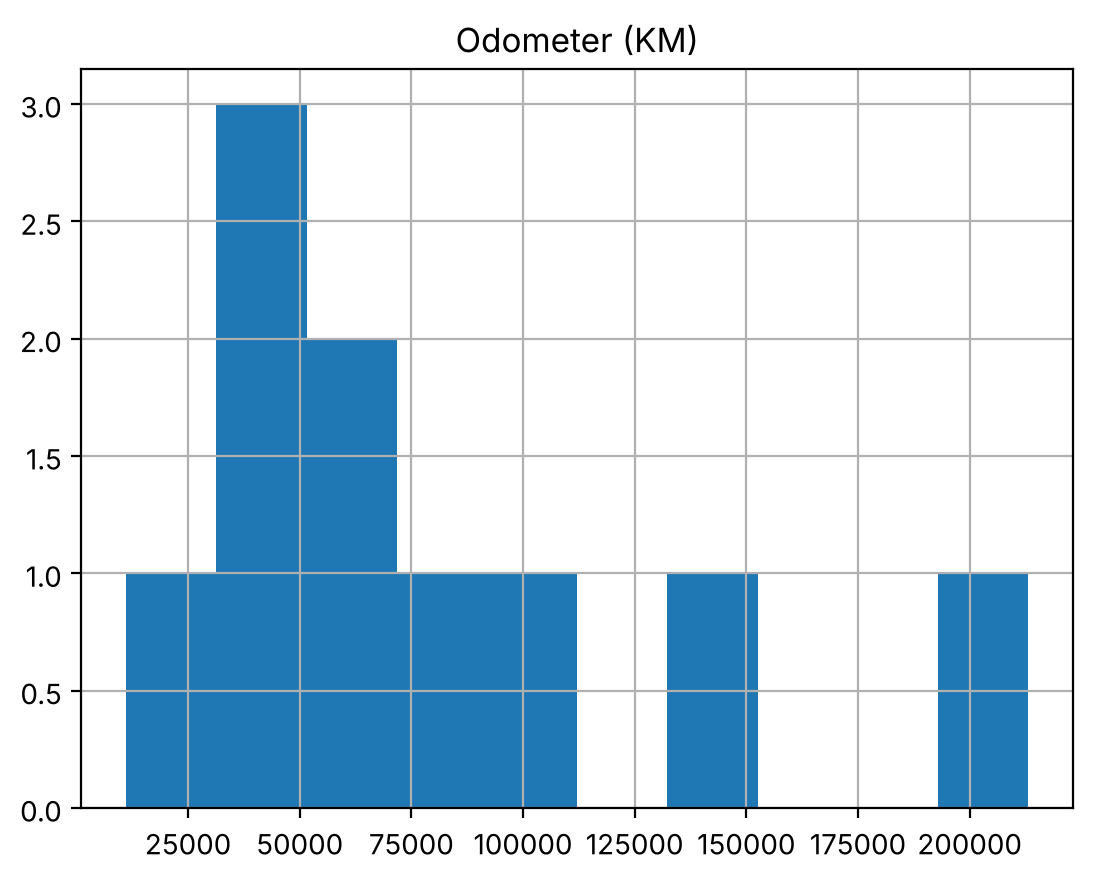

In [7]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
animals = pd.Series(["cat", "dog", "bird", "panda", "snake"], index=[0, 3, 9, 8, 3])
print("loc[3] (label):\n", animals.loc[3], "\niloc[3] (position):", animals.iloc[3], "\n")

print(car_sales[car_sales["Odometer (KM)"] > 100_000][["Make", "Odometer (KM)"]], "\n")
print(pd.crosstab(car_sales["Make"], car_sales["Doors"]), "\n")
print(car_sales.groupby("Make")["Odometer (KM)"].mean())

car_sales["Odometer (KM)"].hist(); plt.title("Odometer (KM)"); plt.show()

<a id="cleaning-text-columns"></a>

### Cleaning Text Columns

Prices stored as `"$4,000.00"` need the symbols stripped before they become numbers. String methods live under `.str`.

**Watch out:** a common snippet uses `.str.replace("[\$\,\.]", "")`. That also removes the decimal point, which multiplies
every price by 100. Keep the dot, pass `regex=True`, and convert with `pd.to_numeric`.

     Make    Price
0  Toyota   4000.0
1   Honda   5000.0
2  Toyota   7000.0
3     BMW  22000.0
4  Nissan   3500.0
Total sales: 76450.0


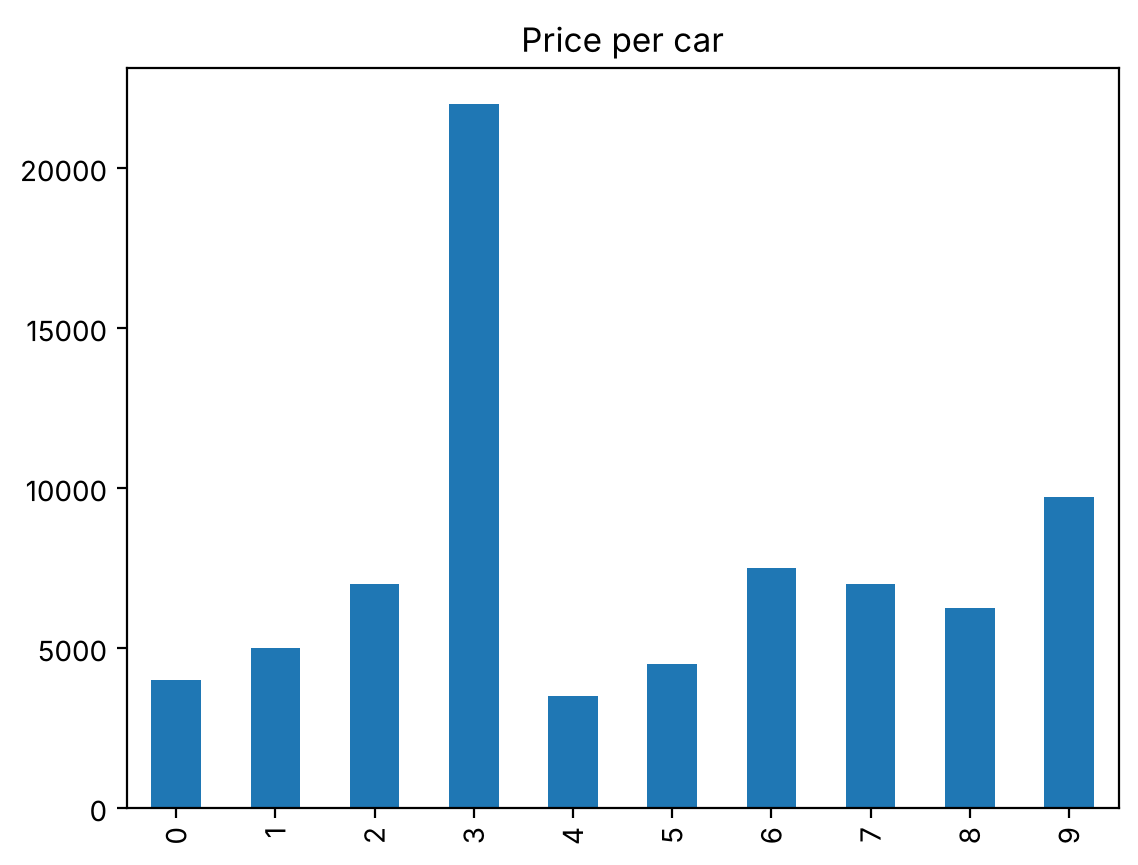

In [8]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Price"] = pd.to_numeric(car_sales["Price"].str.replace(r"[$,]", "", regex=True))
print(car_sales[["Make", "Price"]].head())
print("Total sales:", car_sales["Price"].sum())
car_sales["Price"].plot(kind="bar", title="Price per car"); plt.show()

<a id="adding-changing-and-filling-columns"></a>

### Adding, Changing and Filling Columns

Most pandas operations return a **new** object, so reassign the result to keep it.

- Missing values: `fillna(value)` fills them, `dropna()` removes rows that contain them, `isna().sum()` counts them.
- New columns can come from a Series, a list (its length must match the number of rows), a single value (broadcast to every
  row), or a calculation on other columns. Remove columns with `drop(columns=...)`.
- `apply()` runs a function on every value, and `sample(frac=1)` shuffles all rows (follow it with `reset_index(drop=True)`).

**Watch out:** prefer `df = df.dropna()` over `inplace=True`. The pandas maintainers discourage `inplace`, and under
copy-on-write (the default in pandas 3) `df["col"].fillna(..., inplace=True)` can silently do nothing. Assign instead:
`df["col"] = df["col"].fillna(...)`.

In [9]:
missing = pd.read_csv(DATA / "car-sales-missing-data.csv")
print("Missing per column:\n", missing.isna().sum(), "\n")
missing["Odometer"] = missing["Odometer"].fillna(missing["Odometer"].mean())
print("Rows before/after dropna:", len(missing), "->", len(missing.dropna()))

car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Make"] = car_sales["Make"].str.lower()
car_sales["Seats"] = pd.Series([5, 5, 5, 5, 5])                      # shorter Series -> NaN for the rest
car_sales["Seats"] = car_sales["Seats"].fillna(5)
car_sales["Fuel per 100KM"] = [7.5, 9.2, 5.0, 9.6, 8.7, 4.7, 7.6, 8.7, 3.0, 4.5]   # list must match row count
car_sales["Total fuel used (L)"] = car_sales["Odometer (KM)"] / 100 * car_sales["Fuel per 100KM"]
car_sales["Number of wheels"] = 4                                    # single value broadcasts to every row
car_sales["Odometer (Miles)"] = car_sales["Odometer (KM)"].apply(lambda km: km / 1.6)

shuffled = car_sales.sample(frac=1, random_state=42).reset_index(drop=True)
print(shuffled.drop(columns=["Total fuel used (L)", "Number of wheels"]).head())

Missing per column:
 Make        1
Colour      1
Odometer    4
Doors       1
Price       2
dtype: int64 

Rows before/after dropna: 10 -> 6
     Make Colour  Odometer (KM)  Doors      Price  Seats  Fuel per 100KM  \
0  toyota  White          60000      4  $6,250.00    5.0             3.0   
1   honda    Red          87899      4  $5,000.00    5.0             9.2   
2  toyota  Green          99213      4  $4,500.00    5.0             4.7   
3  toyota  White         150043      4  $4,000.00    5.0             7.5   
4   honda   Blue          54738      4  $7,000.00    5.0             8.7   

   Odometer (Miles)  
0         37500.000  
1         54936.875  
2         62008.125  
3         93776.875  
4         34211.250  


#### Exercise 1

Using `car-sales.csv`, convert `Price` to numbers. Then report the average price per `Make`, the most common `Colour`, and
the cars with fewer than 4 doors **or** more than 150,000 km, sorted by price.

#### Solution 1

*Try it yourself before running this cell.*

In [10]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Price"] = pd.to_numeric(car_sales["Price"].str.replace(r"[$,]", "", regex=True))

print(car_sales.groupby("Make")["Price"].mean().round(2), "\n")
print("Most common colour:", car_sales["Colour"].value_counts().idxmax(), "\n")
mask = (car_sales["Doors"] < 4) | (car_sales["Odometer (KM)"] > 150_000)
print(car_sales[mask].sort_values("Price", ascending=False))

Make
BMW       22000.0
Honda      6500.0
Nissan     6600.0
Toyota     5437.5
Name: Price, dtype: float64 

Most common colour: White 



     Make Colour  Odometer (KM)  Doors   Price
2  Toyota   Blue          32549      3  7000.0
0  Toyota  White         150043      4  4000.0
4  Nissan  White         213095      4  3500.0


<a id="cheatsheet-pandas"></a>

### Cheatsheet: pandas

```python
df = pd.read_csv(path); df.to_csv(path, index=False)
df.head(); df.shape; df.dtypes; df.info(); df.describe(); df.columns
df["col"]; df[["a", "b"]]; df.loc[label]; df.iloc[pos]; df[df["col"] > 5]
pd.crosstab(df["a"], df["b"]); df.groupby("a")["b"].mean(); df["col"].value_counts()
df["col"] = df["col"].fillna(df["col"].mean()); df = df.dropna(); df.isna().sum()
df["new"] = df["a"] / df["b"]; df = df.drop(columns=["new"])
pd.to_numeric(df["col"].str.replace(r"[$,]", "", regex=True)); df["col"].apply(lambda x: x / 1.6)
df.sample(frac=1).reset_index(drop=True)
```

| `.loc` | `.iloc` |
|---|---|
| by index **label** | by integer **position** |
| slice end is included | slice end is excluded |

<a id="5-arrays-and-maths-with-numpy"></a>

## 5. Arrays and Maths with NumPy

NumPy is the numerical engine underneath pandas, scikit-learn and TensorFlow. Every dataset, whether a table, an image or
an audio clip, eventually becomes an array of numbers. NumPy operations run in optimized C rather than Python loops
(*vectorization*), which is why they're fast.

<a id="the-ndarray-and-its-attributes"></a>

### The ndarray and Its Attributes

The core type is the **`ndarray`** (n-dimensional array). One dimension is a vector, two a matrix, and three or more a
tensor. The attributes you'll check constantly are `shape` (size of each dimension), `ndim`, `dtype` (element type) and
`size` (total number of elements). Arrays convert straight into DataFrames.

In [11]:
a1 = np.array([1, 2, 3])
a2 = np.array([[1, 2.0, 3.3], [4, 5, 6.5]])
a3 = np.arange(18).reshape(2, 3, 3)
for name, arr in [("a1", a1), ("a2", a2), ("a3", a3)]:
    print(f"{name}: shape={arr.shape} ndim={arr.ndim} dtype={arr.dtype} size={arr.size}")
print(pd.DataFrame(a2, columns=["x", "y", "z"]))

a1: shape=(3,) ndim=1 dtype=int64 size=3
a2: shape=(2, 3) ndim=2 dtype=float64 size=6
a3: shape=(2, 3, 3) ndim=3 dtype=int64 size=18
     x    y    z
0  1.0  2.0  3.3
1  4.0  5.0  6.5


<a id="creating-arrays-and-reproducible-randomness"></a>

### Creating Arrays and Reproducible Randomness

`np.ones`, `np.zeros`, `np.arange` and the random functions build arrays without typing values. NumPy's random numbers
are *pseudo-random*: fix a **seed** and you get the same numbers every run, which makes experiments reproducible.

The classic API (`np.random.seed`, `np.random.randint`) still works everywhere. The modern API is a `Generator` object,
`rng = np.random.default_rng(seed)`, which doesn't touch global state, so a library can't silently reseed your code.

In [12]:
print(np.ones((2, 3)), np.zeros((2, 3)), np.arange(0, 10, 2), sep="\n")

np.random.seed(0); print(np.random.randint(10, size=(2, 3)))
np.random.seed(0); print(np.random.randint(10, size=(2, 3)))       # identical: same seed, same numbers

rng = np.random.default_rng(0)                                      # modern, preferred API
print(rng.integers(0, 10, size=(2, 3)), rng.random(3).round(3), sep="\n")

[[1. 1. 1.]
 [1. 1. 1.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[0 2 4 6 8]
[[5 0 3]
 [3 7 9]]
[[5 0 3]
 [3 7 9]]
[[8 6 5]
 [2 3 0]]
[0.017 0.813 0.913]


<a id="indexing-and-slicing"></a>

### Indexing and Slicing

Index and slice like Python lists, with one position per dimension: `a3[0]`, `a3[1, 2]`, `a3[:, :2, :2]`. `np.unique`
returns the distinct values.

In [13]:
a3 = np.arange(18).reshape(2, 3, 3)
print(a3[0], "\n")              # first "page"
print(a3[1, 2], "\n")           # second page, third row
print(a3[:, :2, :2], "\n")      # every page, first 2 rows and columns
print(np.unique(np.random.randint(0, 5, size=10)))

[[0 1 2]
 [3 4 5]
 [6 7 8]] 

[15 16 17] 

[[[ 0  1]
  [ 3  4]]

 [[ 9 10]
  [12 13]]] 

[0 1 2 3 4]


<a id="arithmetic-broadcasting-and-aggregation"></a>

### Arithmetic, Broadcasting and Aggregation

Arithmetic is **element-wise**: `a + b`, `a * b`, `a ** 2`, `np.exp(a)`.

**Broadcasting** lets arrays of different but compatible shapes combine. NumPy compares shapes from the right. Each pair
of dimensions must be equal, or one of them must be 1. If neither holds, you get *operands could not be broadcast together*.

**Aggregation** reduces an array: `sum`, `mean`, `max`, `min`, `std`, `var`, optionally along an `axis`. On arrays, use
NumPy's versions. The timing below shows why.

In [14]:
a1 = np.array([1, 2, 3]); a2 = np.array([[1, 2.0, 3.3], [4, 5, 6.5]])
print(a1 + np.ones(3), a1 * a2, sep="\n")            # (3,) broadcasts against (2, 3)
try:
    a2 + np.ones((2, 2))
except ValueError as err:
    print("Broadcast error:", err)
print("sum:", a2.sum(), "| column means:", a2.mean(axis=0), "| row max:", a2.max(axis=1))

big = np.random.random(100_000)
%timeit sum(big)        # Python built-in: loops in Python
%timeit np.sum(big)     # NumPy: vectorized C loop

[2. 3. 4.]
[[ 1.   4.   9.9]
 [ 4.  10.  19.5]]
Broadcast error: operands could not be broadcast together with shapes (2,3) (2,2) 
sum: 21.8 | column means: [2.5 3.5 4.9] | row max: [3.3 6.5]


6.03 ms ± 357 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


26.5 μs ± 3.49 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


<a id="variance-and-standard-deviation"></a>

### Variance and Standard Deviation

**Variance** measures how spread out values are around the mean (the average squared difference). **Standard deviation** is
its square root, so it's in the same units as the data. Two arrays can share a mean and look nothing alike.

high: mean=1600.2 var=4296133.5 std=2072.7
low: mean=6.0 var=8.0 std=2.8


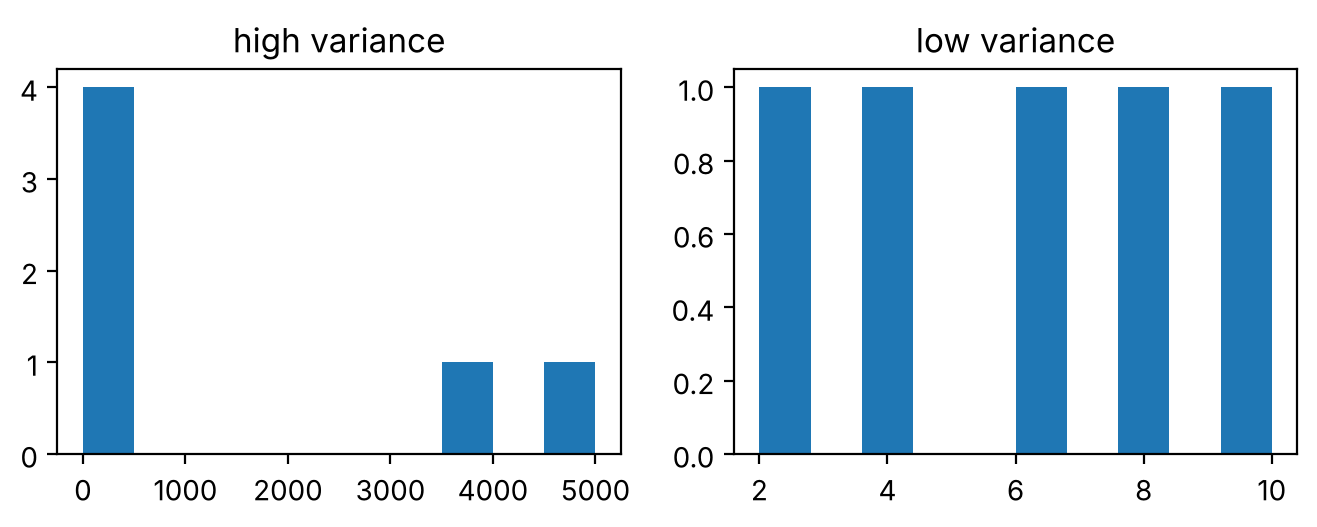

In [15]:
high_var = np.array([1, 100, 200, 300, 4000, 5000])
low_var = np.array([2, 4, 6, 8, 10])
for name, arr in [("high", high_var), ("low", low_var)]:
    print(f"{name}: mean={arr.mean():.1f} var={arr.var():.1f} std={arr.std():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 2.5))
axes[0].hist(high_var); axes[0].set_title("high variance")
axes[1].hist(low_var); axes[1].set_title("low variance")
plt.show()

<a id="reshape-transpose-and-the-dot-product"></a>

### Reshape, Transpose and the Dot Product

`reshape` changes an array's shape without changing its data (`-1` means "infer this dimension"), and `.T` swaps the axes.
Both come up constantly when shapes don't line up.

Element-wise multiplication (`a * b`) needs matching or broadcastable shapes. The **dot product** (`a @ b`, matrix
multiplication) needs the **inner** dimensions to match: `(m, n) @ (n, p)` gives `(m, p)`.

A concrete use: five days of sales for three products, multiplied by the price of each product, gives daily revenue.

In [16]:
a2 = np.array([[1, 2.0, 3.3], [4, 5, 6.5]])
print((a2.reshape(2, 3, 1) * np.arange(18).reshape(2, 3, 3)).shape, a2.T.shape)

np.random.seed(0)
mat1, mat2 = np.random.randint(10, size=(5, 3)), np.random.randint(10, size=(5, 3))
try:
    mat1 @ mat2
except ValueError:
    print("(5, 3) @ (5, 3) fails; with a transpose:", (mat1 @ mat2.T).shape)

np.random.seed(0)
sales = np.random.randint(20, size=(5, 3))
prices = np.array([10, 8, 12])
weekly = pd.DataFrame(sales, index=["Mon", "Tues", "Wed", "Thurs", "Fri"],
                      columns=["Almond butter", "Peanut butter", "Cashew butter"])
weekly["Total ($)"] = sales @ prices                 # (5, 3) @ (3,) -> (5,)
print(weekly)

(2, 3, 3) (3, 2)
(5, 3) @ (5, 3) fails; with a transpose: (5, 5)
       Almond butter  Peanut butter  Cashew butter  Total ($)
Mon               12             15              0        240
Tues               3              3              7        138
Wed                9             19             18        458
Thurs              4              6             12        232
Fri                1              6              7        142


<a id="comparisons-sorting-and-argmax"></a>

### Comparisons, Sorting and argmax

Comparisons (`>`, `==`) are element-wise and return boolean masks. `np.sort` sorts values, `np.argsort` returns the
indices that would sort them, and `np.argmax` returns the index of the largest value. That last one is exactly how
prediction probabilities become class labels later.

In [17]:
np.random.seed(0)
random_array = np.random.randint(10, size=(3, 5))
print(random_array)
print("mask > 5:\n", random_array > 5)
print("sorted rows:\n", np.sort(random_array))
print("argmax per row:", np.argmax(random_array, axis=1))

[[5 0 3 3 7]
 [9 3 5 2 4]
 [7 6 8 8 1]]
mask > 5:
 [[False False False False  True]
 [ True False False False False]
 [ True  True  True  True False]]
sorted rows:
 [[0 3 3 5 7]
 [2 3 4 5 9]
 [1 6 7 8 8]]
argmax per row: [4 0 2]


<a id="images-are-just-arrays"></a>

### Images Are Just Arrays

An image is a grid of numbers with shape height × width × channels. `matplotlib.image.imread()` loads one into an array,
which is the first step of any computer-vision pipeline.

**Watch out:** the value range depends on the file format. JPEG files load as integers 0–255 (`uint8`) with 3 channels
(red, green, blue). PNG files load as floats 0–1, often with a 4th **alpha** (transparency) channel. Check `shape` and
`dtype` before feeding images to a model.

<class 'numpy.ndarray'> (500, 500, 3) uint8 min/max: 0 255
top-left pixel (R, G, B): [254 255 253]


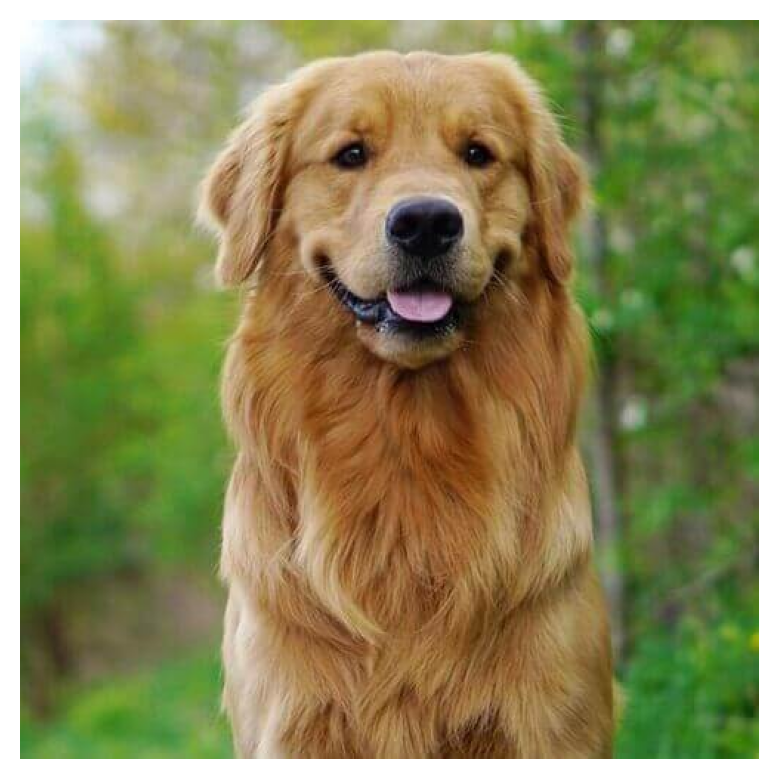

In [18]:
from matplotlib.image import imread

dog = imread(DATA / "dog-photos" / "golden-retriever.jpeg")
print(type(dog), dog.shape, dog.dtype, "min/max:", dog.min(), dog.max())
print("top-left pixel (R, G, B):", dog[0, 0])
plt.imshow(dog); plt.axis("off"); plt.show()

#### Exercise 2

Create a 3 × 4 array of random integers between 0 and 100 with `default_rng(7)`. Print the column means, the index of the
largest value in each row, and the array scaled to 0–1 per column using broadcasting: `(x - min) / (max - min)`.

#### Solution 2

*Try it yourself before running this cell.*

In [19]:
rng = np.random.default_rng(7)
arr = rng.integers(0, 100, size=(3, 4))
print(arr)
print("column means:", arr.mean(axis=0))
print("argmax per row:", arr.argmax(axis=1))
col_min, col_max = arr.min(axis=0), arr.max(axis=0)        # shapes (4,) broadcast against (3, 4)
print(((arr - col_min) / (col_max - col_min)).round(2))

[[94 62 68 89]
 [57 77 83 22]
 [ 5 30 28 87]]
column means: [52.         56.33333333 59.66666667 66.        ]
argmax per row: [0 2 3]
[[1.   0.68 0.73 1.  ]
 [0.58 1.   1.   0.  ]
 [0.   0.   0.   0.97]]


<a id="cheatsheet-numpy"></a>

### Cheatsheet: NumPy

```python
np.array(list); np.zeros(shape); np.ones(shape); np.arange(start, stop, step)
rng = np.random.default_rng(42); rng.integers(0, 10, size=(3, 3)); rng.random((2, 2))
a.shape; a.ndim; a.dtype; a.size; a[0, 1:3]; a[:, ::2]; a[a > 5]
a + b; a * b; a @ b; a.T; a.reshape(2, -1)
a.sum(axis=0); a.mean(); a.std(); a.var(); np.unique(a); np.sort(a); np.argsort(a); a.argmax(axis=1)
```

| Operation | Shape rule |
|---|---|
| element-wise `a * b` | equal, or broadcastable (compare from the right: equal or 1) |
| dot product `a @ b` | inner dimensions equal: `(m, n) @ (n, p) -> (m, p)` |

<a id="6-visualizing-data-with-matplotlib"></a>

## 6. Visualizing Data with Matplotlib

Plots are how you understand data, and how you explain it to everyone else. Matplotlib is the foundation, and pandas and
seaborn both build on it.

<a id="figures-axes-and-the-two-plotting-styles"></a>

### Figures, Axes and the Two Plotting Styles

Matplotlib has two interfaces:

- **pyplot** (`plt.plot(x, y)`) is quick and implicit, which makes it handy for a fast look.
- The **object-oriented API** (`fig, ax = plt.subplots()`, then `ax.plot(...)`) is explicit about which figure and axes
  you're drawing on. Use it for anything you'll customize or share.

A **Figure** is the whole canvas, and it holds one or more **Axes**. Each Axes is an individual plot with its own x-axis,
y-axis, title, labels, ticks and legend:

![Anatomy of a Matplotlib figure](https://matplotlib.org/stable/_images/anatomy.png)

*Anatomy of a figure. Image: [Matplotlib documentation](https://matplotlib.org/stable/users/explain/quick_start.html).*

The workflow is always the same: prepare the data, create the figure and axes, plot, customize, then save or show.

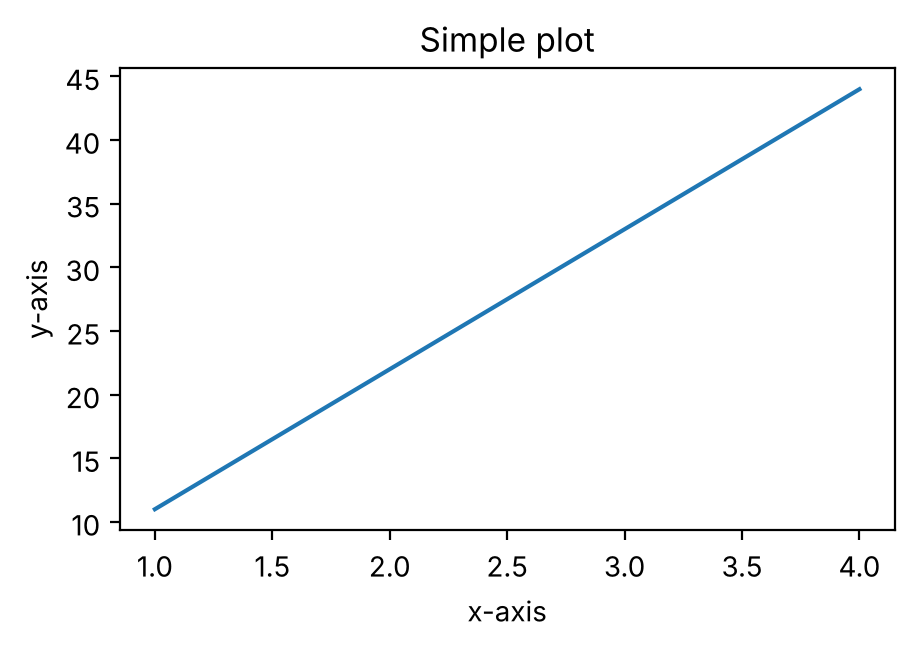

In [20]:
fig, ax = plt.subplots(figsize=(5, 3))                          # 1. figure + axes
ax.plot([1, 2, 3, 4], [11, 22, 33, 44])                         # 2. plot
ax.set(title="Simple plot", xlabel="x-axis", ylabel="y-axis")   # 3. customize
fig.savefig("sample-plot.png")                                  # 4. save
plt.show()

<a id="line-scatter-bar-and-histogram"></a>

### Line, Scatter, Bar and Histogram

Pick the plot for the question you're asking: a **line** for a trend over an ordered axis, a **scatter** for the
relationship between two numbers, a **bar** chart to compare categories (`barh` for horizontal), and a **histogram** for
the distribution of one variable.

Subplots come in two equivalent forms. You can unpack them directly with `fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2)`,
or keep the array and index it with `axes[0, 1]`.

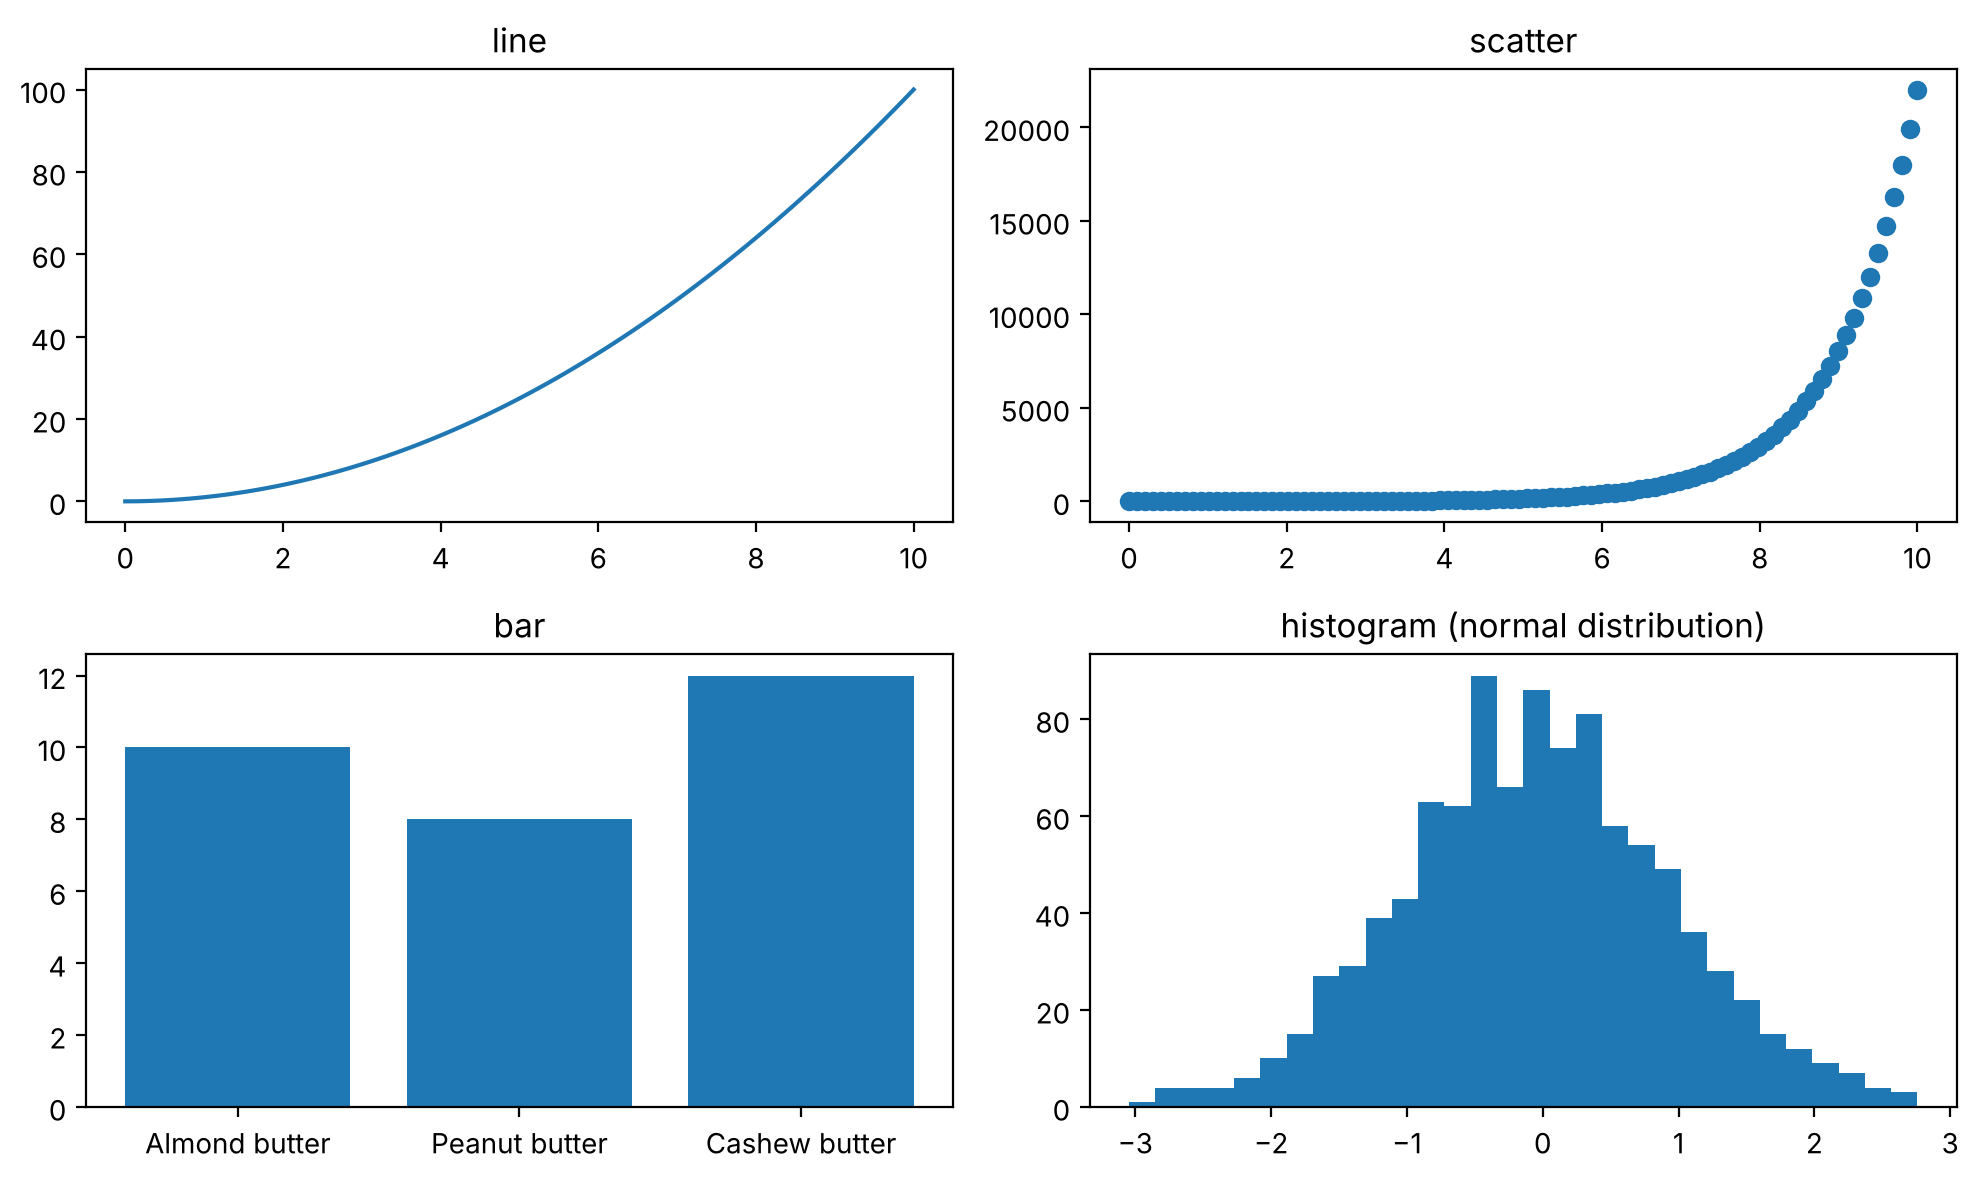

In [21]:
x = np.linspace(0, 10, 100)
prices = {"Almond butter": 10, "Peanut butter": 8, "Cashew butter": 12}

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(x, x ** 2); axes[0, 0].set_title("line")
axes[0, 1].scatter(x, np.exp(x)); axes[0, 1].set_title("scatter")
axes[1, 0].bar(list(prices), list(prices.values())); axes[1, 0].set_title("bar")
axes[1, 1].hist(np.random.randn(1000), bins=30); axes[1, 1].set_title("histogram (normal distribution)")
plt.tight_layout(); plt.show()

<a id="plotting-straight-from-pandas"></a>

### Plotting Straight from pandas

DataFrames and Series have a `.plot()` method (`kind="line" | "scatter" | "bar" | "hist"`) built on Matplotlib. You can
mix the two styles by passing `ax=` to a pandas plot, so pandas draws on an Axes you control.

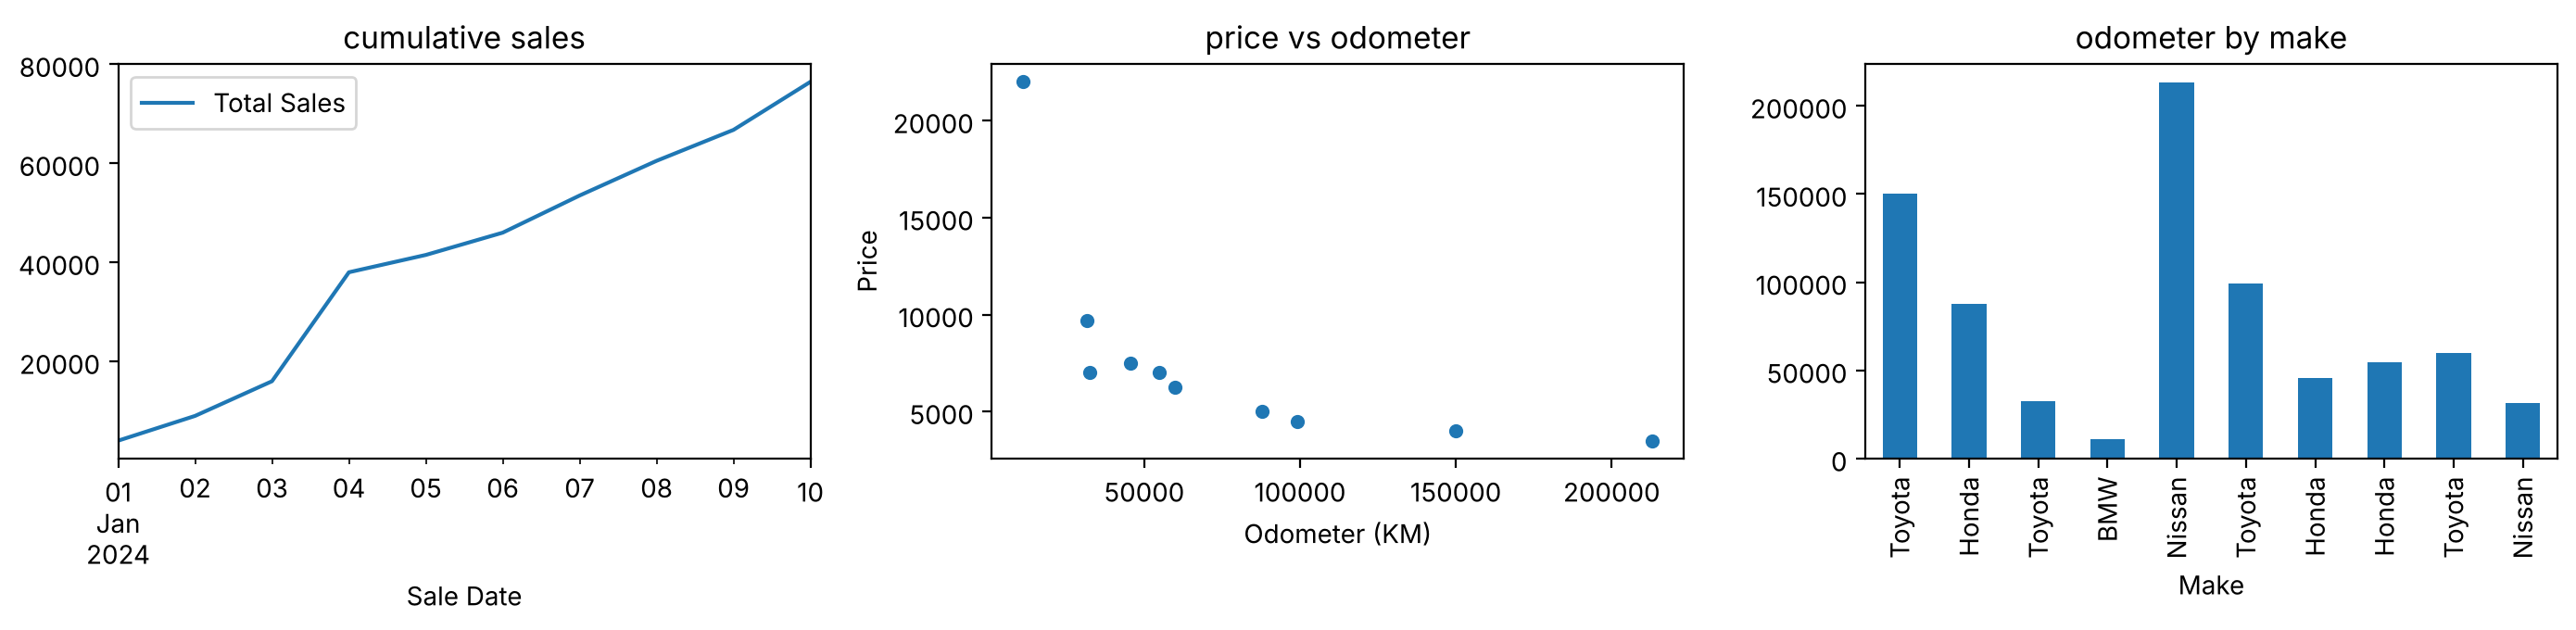

In [22]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Price"] = pd.to_numeric(car_sales["Price"].str.replace(r"[$,]", "", regex=True))
car_sales["Sale Date"] = pd.date_range("2024-01-01", periods=len(car_sales))
car_sales["Total Sales"] = car_sales["Price"].cumsum()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
car_sales.plot(x="Sale Date", y="Total Sales", ax=axes[0], title="cumulative sales")
car_sales.plot(kind="scatter", x="Odometer (KM)", y="Price", ax=axes[1], title="price vs odometer")
car_sales.plot(kind="bar", x="Make", y="Odometer (KM)", ax=axes[2], title="odometer by make", legend=False)
plt.tight_layout(); plt.show()

A more realistic example uses the heart-disease data. It plots patients over 50, age against cholesterol and against
maximum heart rate, coloured by diagnosis, with a dashed line at the mean:

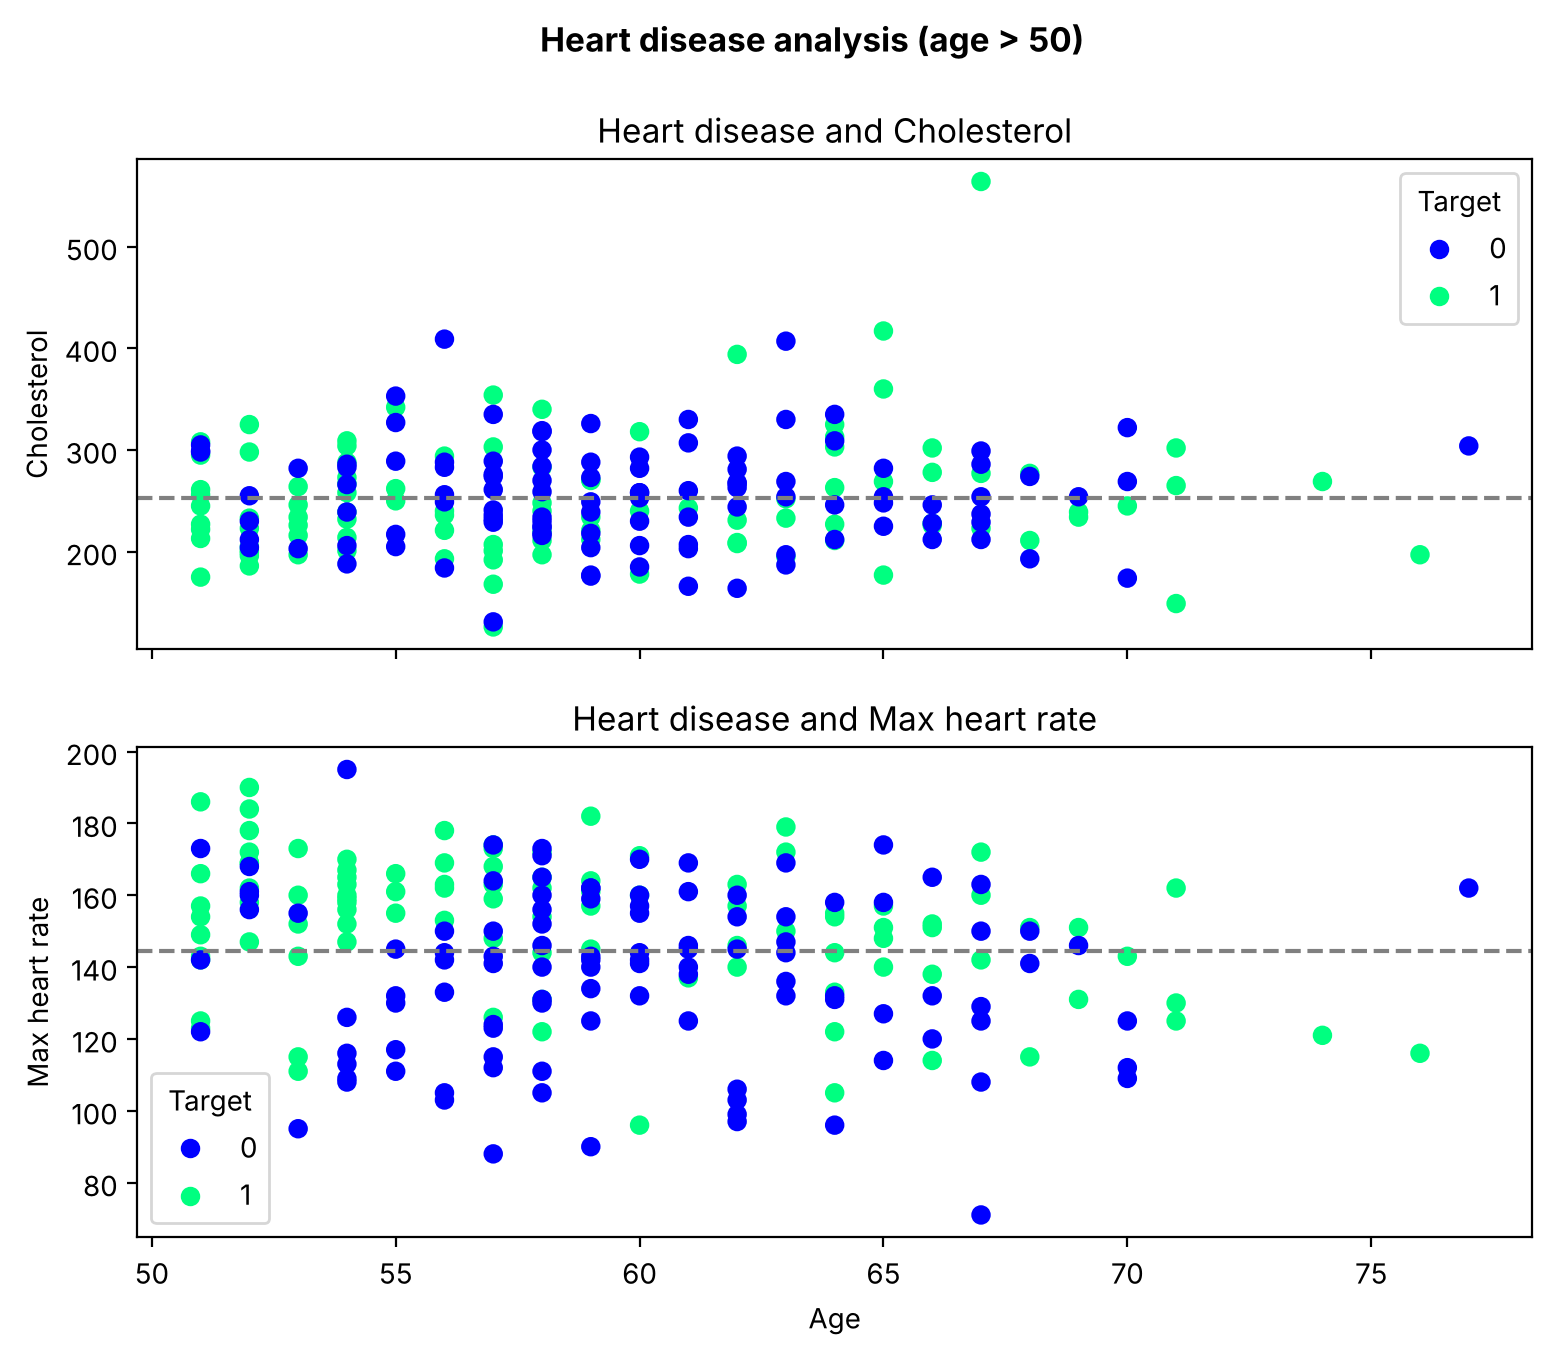

In [23]:
heart_disease = pd.read_csv(DATA / "heart-disease.csv")
over_50 = heart_disease[heart_disease["age"] > 50]

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for ax, col, title in [(ax0, "chol", "Cholesterol"), (ax1, "thalach", "Max heart rate")]:
    sc = ax.scatter(over_50["age"], over_50[col], c=over_50["target"], cmap="winter")
    ax.axhline(over_50[col].mean(), linestyle="--", color="grey")     # mean line
    ax.set(title=f"Heart disease and {title}", ylabel=title)
    ax.legend(*sc.legend_elements(), title="Target")
ax1.set_xlabel("Age")
fig.suptitle("Heart disease analysis (age > 50)", fontweight="bold")
plt.show()

<a id="styling-and-saving"></a>

### Styling and Saving

Styles change the whole look at once (`plt.style.available` lists them). Use `plt.style.context(...)` to apply one only
inside a `with` block. Axis limits come from `ax.set(xlim=..., ylim=...)` or `sharex=True`, colours from `cmap=`, and
reference lines from `ax.axhline()`. Save with `fig.savefig("name.png", dpi=..., bbox_inches="tight")`: use PNG for slides
and SVG or PDF for documents.

**Watch out:** the style called `"seaborn"` was renamed `"seaborn-v0_8"` in Matplotlib 3.6, so older code using the old
name fails.

['seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark'] ...


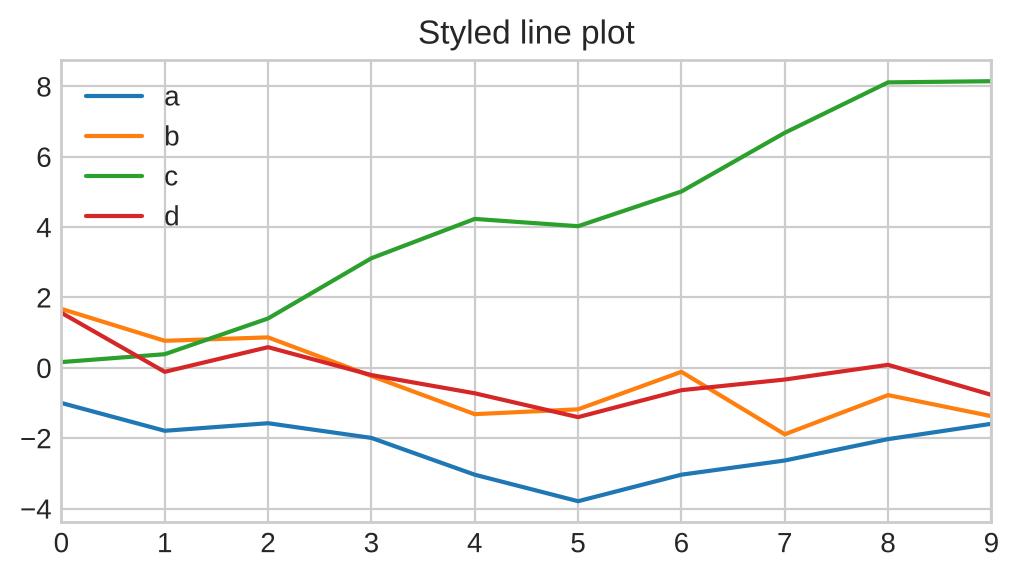

In [24]:
print([s for s in plt.style.available if s.startswith("seaborn")][:4], "...")
with plt.style.context("seaborn-v0_8-whitegrid"):
    fig, ax = plt.subplots(figsize=(6, 3))
    data = np.random.randn(10, 4).cumsum(axis=0)
    for i, label in enumerate("abcd"):
        ax.plot(data[:, i], label=label)
    ax.set(title="Styled line plot", xlim=(0, 9)); ax.legend(loc="upper left")
    plt.show()

#### Exercise 3

From `heart-disease.csv`, make a 1 × 2 figure: a histogram of `age`, and a bar chart of the count of each `cp` (chest-pain
type) split by `target`, using `pd.crosstab(...).plot(kind="bar", ax=...)`. Give both titles and save the figure.

#### Solution 3

*Try it yourself before running this cell.*

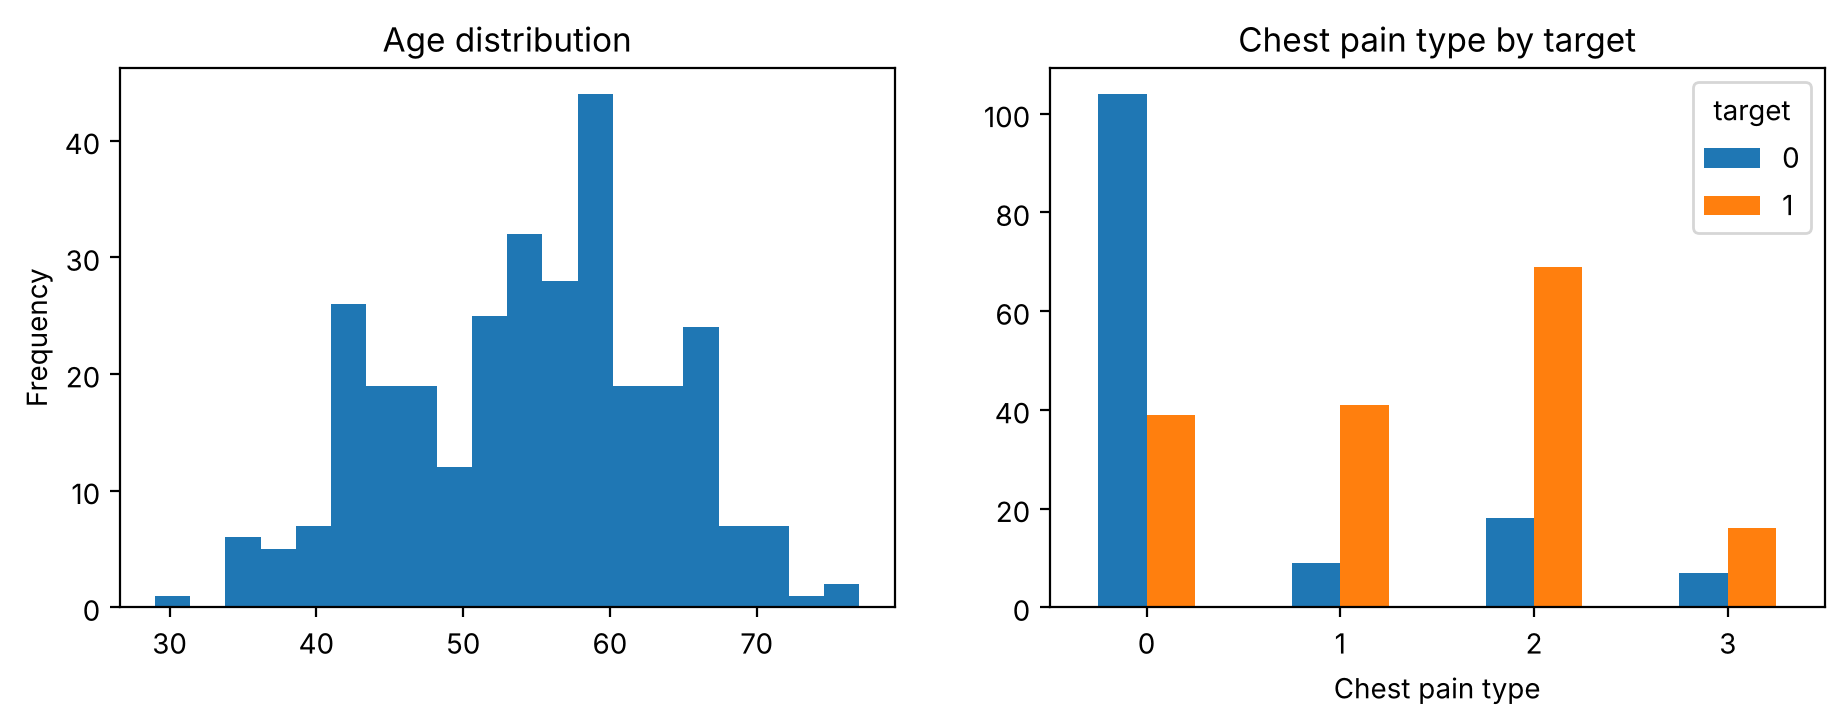

In [25]:
heart_disease = pd.read_csv(DATA / "heart-disease.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
heart_disease["age"].plot.hist(bins=20, ax=axes[0], title="Age distribution")
pd.crosstab(heart_disease["cp"], heart_disease["target"]).plot(kind="bar", ax=axes[1],
                                                                title="Chest pain type by target")
axes[1].set_xlabel("Chest pain type"); axes[1].tick_params(axis="x", rotation=0)
fig.savefig("heart-disease-overview.png", bbox_inches="tight")
plt.show()

<a id="cheatsheet-matplotlib"></a>

### Cheatsheet: Matplotlib

```python
fig, ax = plt.subplots(figsize=(10, 6)); fig, axes = plt.subplots(2, 2)      # axes[0, 1]
ax.plot(x, y); ax.scatter(x, y, c=labels, cmap="winter"); ax.bar(names, values); ax.hist(data, bins=30)
ax.set(title="...", xlabel="...", ylabel="...", xlim=(0, 10)); ax.legend(); ax.axhline(y.mean(), linestyle="--")
df.plot(kind="scatter", x="a", y="b", ax=ax); df["col"].plot.hist()
plt.style.use("seaborn-v0_8"); fig.savefig("plot.png", bbox_inches="tight")
```

| Question | Plot |
|---|---|
| trend over time | line |
| relationship between two numbers | scatter |
| compare categories | bar / barh |
| distribution of one variable | histogram |

<a id="7-building-models-with-scikit-learn"></a>

## 7. Building Models with scikit-learn

scikit-learn gives every model the same interface (`fit`, `predict`, `score`), plus tools for preparing data, evaluating
models, tuning hyperparameters and saving the result. Learn the pattern once and it transfers to dozens of algorithms. In
scikit-learn terms, a model is called an **estimator**.

<a id="the-workflow-in-one-cell"></a>

### The Workflow in One Cell

```mermaid
flowchart LR
    A[Get data ready: X, y, split] --> B[Choose an estimator] --> C["fit(X_train, y_train)"]
    C --> D["predict(X_test)"] --> E[Evaluate] --> F[Improve: tune hyperparameters] --> G[Save the model]
    F -.re-fit.-> C
```

Everything in this section expands on one of those boxes. Here is the whole loop end to end on the heart-disease data: split
features `X` from labels `y`, fit a random forest, score it, try a few values of one hyperparameter, then save and reload
the model.

In [26]:
# The whole scikit-learn workflow in one cell (heart disease classification).
import pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X = heart_disease.drop(columns="target")      # features
y = heart_disease["target"]                   # labels (1 = heart disease)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
print("Test accuracy:", round(clf.score(X_test, y_test), 3))

# Improve: try a few values of one hyperparameter.
for n in [10, 50, 100, 200]:
    model = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    print(f"n_estimators={n:>3}: {model.score(X_test, y_test):.3f}")

# Save and load.
with open("random-forest-model-1.pkl", "wb") as f:
    pickle.dump(clf, f)
with open("random-forest-model-1.pkl", "rb") as f:
    loaded = pickle.load(f)
print("Loaded model accuracy:", round(loaded.score(X_test, y_test), 3))

Test accuracy: 0.836
n_estimators= 10: 0.852
n_estimators= 50: 0.869
n_estimators=100: 0.836


n_estimators=200: 0.836
Loaded model accuracy: 0.836


<a id="getting-data-ready"></a>

### Getting Data Ready

Three jobs come before any modelling: **split** the data into features and labels (and train/test), **convert** non-numeric
values to numbers, and **handle missing values**. In short: clean, transform, reduce.

Text columns break models immediately with *could not convert string to float*. **One-hot encoding** turns each category
into its own 0/1 column. In scikit-learn, you do this with `OneHotEncoder` inside a `ColumnTransformer`, using
`remainder="passthrough"` to keep the other columns. Note that `Doors` is stored as a number but is really a category.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

car_sales = pd.read_csv(DATA / "car-sales-extended.csv")
X, y = car_sales.drop(columns="Price"), car_sales["Price"]

try:
    RandomForestRegressor().fit(X, y)
except ValueError as err:
    print("Fails on text:", str(err).splitlines()[0])

categorical = ["Make", "Colour", "Doors"]          # Doors is numeric but categorical in meaning
transformer = ColumnTransformer([("one_hot", OneHotEncoder(handle_unknown="ignore"), categorical)],
                                remainder="passthrough")
X_encoded = transformer.fit_transform(X)
print("Encoded shape:", X_encoded.shape)
print(pd.get_dummies(X[["Make", "Colour"]]).head(3))

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(random_state=42).fit(X_train, y_train)
print("R^2:", round(model.score(X_test, y_test), 3))

Fails on text: could not convert string to float: 'Honda'
Encoded shape: (1000, 13)
   Make_BMW  Make_Honda  Make_Nissan  Make_Toyota  Colour_Black  Colour_Blue  \
0     False        True        False        False         False        False   
1      True       False        False        False         False         True   
2     False        True        False        False         False        False   

   Colour_Green  Colour_Red  Colour_White  
0         False       False          True  
1         False       False         False  
2         False       False          True  


R^2: 0.294


**Watch out:** fitting the encoder on all of `X` before splitting lets the test set influence preprocessing. For one-hot
encoding the effect is tiny, but the same habit with imputers and scalers is real leakage. The
[pipeline version](#pipelines-preprocessing-and-model-as-one-object) below fits preprocessing on training data only.

For **missing values** you can either fill them (*imputation*) or drop rows. Filling is never perfect, because you are
inventing data, so pick strategies that make sense per column: a placeholder like `"missing"` for categories, the most
common value or a sensible default for discrete columns, the mean or median for numbers. Always drop rows where the
**target** is missing, since an example without a label teaches nothing.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

car_sales_missing = pd.read_csv(DATA / "car-sales-extended-missing-data.csv")
print("Missing:\n", car_sales_missing.isna().sum(), "\n")

car_sales_missing = car_sales_missing.dropna(subset=["Price"])      # no label, no learning
X, y = car_sales_missing.drop(columns="Price"), car_sales_missing["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

imputer = ColumnTransformer([
    ("cat", SimpleImputer(strategy="constant", fill_value="missing"), ["Make", "Colour"]),
    ("door", SimpleImputer(strategy="constant", fill_value=4), ["Doors"]),
    ("num", SimpleImputer(strategy="mean"), ["Odometer (KM)"]),
])
X_train_filled = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)   # fit on train...
X_test_filled = pd.DataFrame(imputer.transform(X_test), columns=X.columns)         # ...reuse on test
print("Missing after imputation:", int(X_train_filled.isna().sum().sum()), int(X_test_filled.isna().sum().sum()))

Missing:
 Make             49
Colour           50
Odometer (KM)    50
Doors            50
Price            50
dtype: int64 

Missing after imputation: 0 0


Cleaning, encoding, scaling and feature reduction go much deeper in the
[Data Preparation reference](https://github.com/rokon-uddin/data-preparation-reference).

<a id="choosing-an-estimator"></a>

### Choosing an Estimator

scikit-learn publishes a [flowchart for choosing an estimator](https://scikit-learn.org/stable/machine_learning_map.html)
based on the problem type and dataset size. In practice I start with a simple linear model as a baseline and then try a
tree ensemble.

For regression on California housing (20,640 districts, target = median house value in $100,000s), `Ridge` is the linear
baseline and `RandomForestRegressor` is an **ensemble** that averages many decision trees. The forest wins comfortably.

**Watch out:** many tutorials use `load_boston()`. It was removed in scikit-learn 1.2 because one of its features was
derived from the proportion of Black residents. Use `fetch_california_housing()` instead.

In [29]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True)
housing_df = housing.frame                                   # features + "MedHouseVal" target
print(housing_df.shape)

X, y = housing_df.drop(columns="MedHouseVal"), housing_df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for model in [Ridge(), RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)]:
    model.fit(X_train, y_train)
    print(f"{type(model).__name__:24s} R^2 = {model.score(X_test, y_test):.3f}")

(20640, 9)
Ridge                    R^2 = 0.576


RandomForestRegressor    R^2 = 0.805


For classification on heart disease, the flowchart suggests `LinearSVC` first. On this small dataset the linear model
actually edges out the random forest on a single split, which is a good reminder to test rather than assume.

In [30]:
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for model in [LinearSVC(max_iter=10_000, random_state=42), RandomForestClassifier(random_state=42)]:
    model.fit(X_train, y_train)
    print(f"{type(model).__name__:24s} accuracy = {model.score(X_test, y_test):.3f}")

LinearSVC                accuracy = 0.869
RandomForestClassifier   accuracy = 0.836


<a id="predictions-and-probabilities"></a>

### Predictions and Probabilities

`fit(X, y)` is where the model learns. `predict(X)` returns labels (or numbers, for regression), and new data must have
**the same features in the same format** as the training data. `predict_proba(X)` returns a probability per class, and
`predict` picks the most probable one, which means a 0.5 threshold for binary problems. Probabilities are what you need
for ROC curves and for adjusting the threshold to the cost of mistakes.

In [31]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

print("predict:      ", clf.predict(X_test[:5]))
print("predict_proba:\n", clf.predict_proba(X_test[:5]).round(2))
print("same as accuracy_score:", clf.score(X_test, y_test) == accuracy_score(y_test, clf.predict(X_test)))

housing = fetch_california_housing(as_frame=True)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(housing.data, housing.target, test_size=0.2, random_state=42)
reg = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42).fit(Xh_train, yh_train)
print("regression predictions:", reg.predict(Xh_test[:5]).round(2), "| truth:", yh_test[:5].values)
print("MAE:", round(mean_absolute_error(yh_test, reg.predict(Xh_test)), 3))

predict:       [0 1 1 0 1]
predict_proba:
 [[0.95 0.05]
 [0.38 0.62]
 [0.45 0.55]
 [0.86 0.14]
 [0.21 0.79]]
same as accuracy_score: True


regression predictions: [0.51 0.75 4.96 2.5  2.25] | truth: [0.477   0.458   5.00001 2.186   2.78   ]
MAE: 0.328


<a id="evaluating-a-model-and-cross-validation"></a>

### Evaluating a Model and Cross-Validation

There are three ways to evaluate in scikit-learn:

1. The estimator's built-in `score()`, which is mean accuracy for classifiers and R² for regressors.
2. The `scoring` parameter of tools like `cross_val_score` and `GridSearchCV`.
3. Metric functions in `sklearn.metrics`, called on true and predicted values.

A single train/test split can be lucky or unlucky. **Cross-validation** trains and evaluates on *k* different splits
(5 by default) and averages the scores, giving a far more trustworthy estimate.

```mermaid
flowchart LR
    subgraph "5-fold cross-validation"
        F1["Fold 1: test | train train train train"]
        F2["Fold 2: train | test | train train train"]
        F3["..."]
        F5["Fold 5: train train train train | test"]
    end
    F1 & F2 & F3 & F5 --> AVG[Average the 5 scores]
```

In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

print("Single split score:", round(clf.score(X_test, y_test), 3))
cv_scores = cross_val_score(RandomForestClassifier(random_state=42), X, y, cv=5)
print("5-fold CV scores:  ", cv_scores.round(3), "-> mean", round(cv_scores.mean(), 3))

Single split score: 0.836


5-fold CV scores:   [0.82  0.885 0.836 0.85  0.8  ] -> mean 0.838


<a id="classification-metrics-accuracy-roc-and-auc"></a>

### Classification Metrics: Accuracy, ROC and AUC

**Accuracy** is correct predictions divided by all predictions. It's fine when the classes are balanced, but misleading
when they aren't.

The **ROC curve** plots the true-positive rate against the false-positive rate at every probability threshold. A perfect
model hugs the top-left corner, and random guessing follows the diagonal. **AUC**, the area under that curve, summarizes it
in one number: 1.0 is perfect, 0.5 is a coin flip.

**Watch out:** `plot_roc_curve` was removed in scikit-learn 1.2. Use `RocCurveDisplay.from_estimator(...)` or
`RocCurveDisplay.from_predictions(...)`.

Cross-validated accuracy: 83.82%
AUC: 0.92


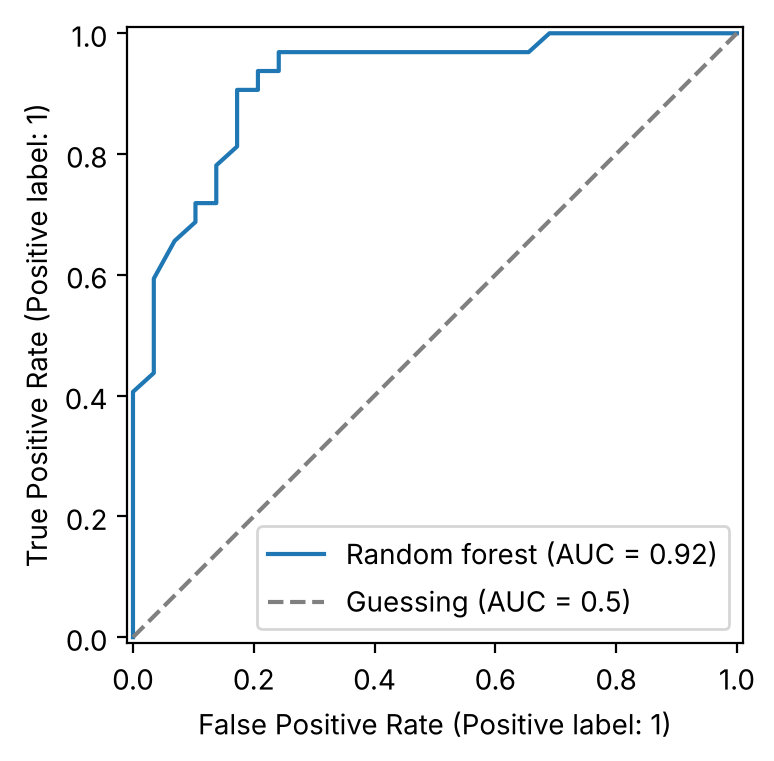

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import train_test_split, cross_val_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

cv_acc = cross_val_score(clf, X, y, cv=5, scoring="accuracy")
print(f"Cross-validated accuracy: {cv_acc.mean() * 100:.2f}%")

y_probs = clf.predict_proba(X_test)[:, 1]                  # probability of the positive class
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
print("AUC:", round(roc_auc_score(y_test, y_probs), 3))

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, y_probs, ax=ax, name="Random forest")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Guessing (AUC = 0.5)")
ax.legend(); plt.show()

<a id="classification-metrics-the-confusion-matrix"></a>

### Classification Metrics: The Confusion Matrix

A **confusion matrix** shows exactly where the model gets confused. In scikit-learn, rows are the **true** labels and
columns the **predicted** labels, so a binary matrix reads `[[TN, FP], [FN, TP]]`. A seaborn heatmap or
`ConfusionMatrixDisplay` makes it readable at a glance (`plot_confusion_matrix` was removed in 1.2).

[[24  5]
 [ 5 27]]
Predicted   0   1
Actual           
0          24   5
1           5  27


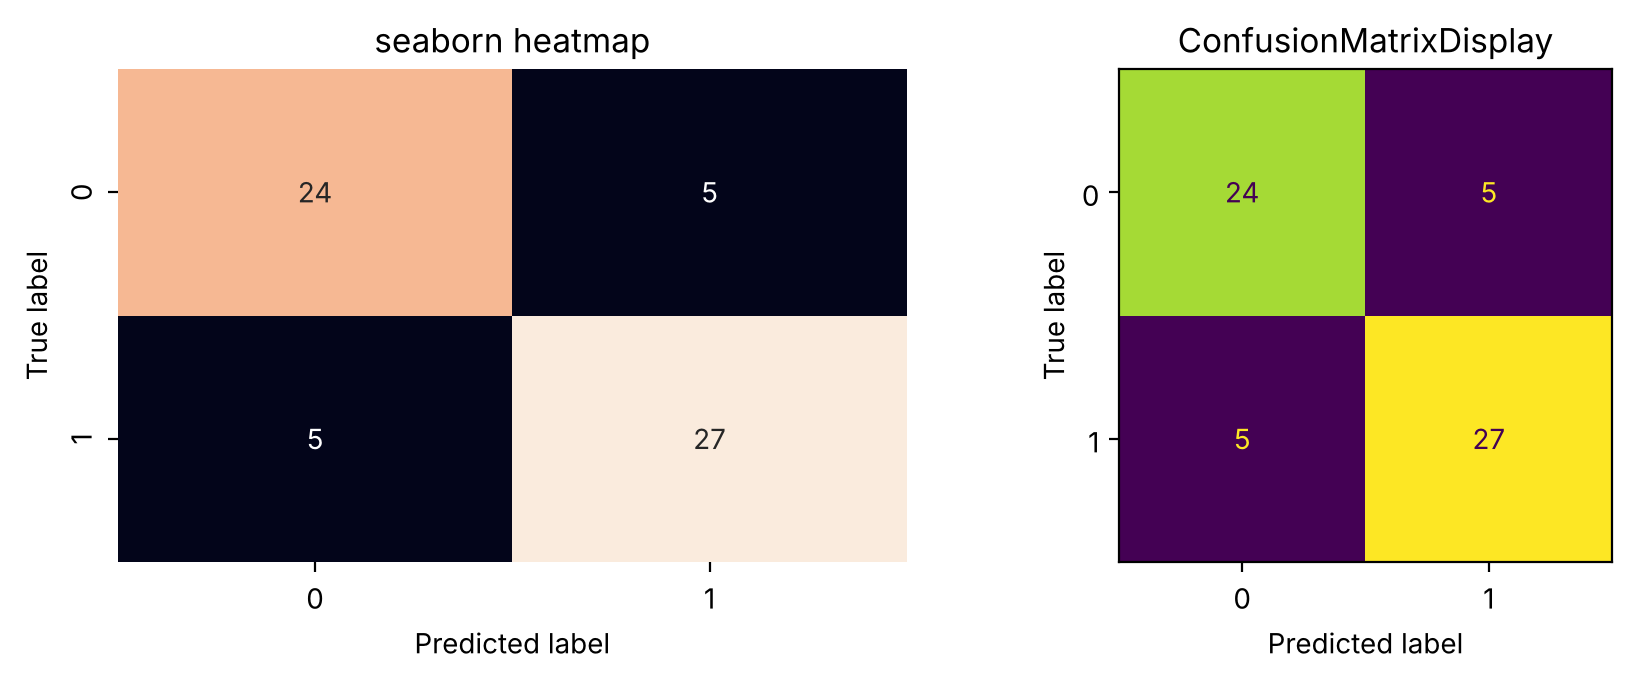

In [34]:
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_preds = RandomForestClassifier(random_state=42).fit(X_train, y_train).predict(X_test)

print(confusion_matrix(y_test, y_preds))
print(pd.crosstab(y_test, y_preds, rownames=["Actual"], colnames=["Predicted"]))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
sns.heatmap(confusion_matrix(y_test, y_preds), annot=True, cbar=False, ax=axes[0])
axes[0].set(xlabel="Predicted label", ylabel="True label", title="seaborn heatmap")
ConfusionMatrixDisplay.from_predictions(y_test, y_preds, ax=axes[1], colorbar=False)
axes[1].set_title("ConfusionMatrixDisplay")
plt.tight_layout(); plt.show()

<a id="classification-metrics-precision-recall-and-f1"></a>

### Classification Metrics: Precision, Recall and F1

`classification_report` shows each class's **precision** (of the positives you predicted, how many were right), **recall**
(of the actual positives, how many you found), **F1** (their harmonic mean) and **support** (number of samples). The
*macro* average treats classes equally, and the *weighted* average weights them by support.

| Metric | Formula | Use when |
|---|---|---|
| Accuracy | (TP + TN) / all | classes are balanced |
| Precision | TP / (TP + FP) | false positives are costly (spam filters) |
| Recall | TP / (TP + FN) | false negatives are costly (disease screening) |
| F1 | 2·P·R / (P + R) | you need one balanced number |

The second half of the cell shows why accuracy alone is dangerous. With 1 positive in 10,000, a model that always says
"negative" scores 99.99% accuracy and finds nothing.

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_preds = RandomForestClassifier(random_state=42).fit(X_train, y_train).predict(X_test)
print(classification_report(y_test, y_preds))

# The imbalanced-data trap: 1 positive in 10,000, model always predicts 0.
disease_true = np.zeros(10_000); disease_true[0] = 1
disease_preds = np.zeros(10_000)
print(pd.DataFrame(classification_report(disease_true, disease_preds, output_dict=True, zero_division=0)).round(4))

              precision    recall  f1-score   support

           0       0.83      0.83      0.83        29
           1       0.84      0.84      0.84        32

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61

                 0.0  1.0  accuracy  macro avg  weighted avg
precision     0.9999  0.0    0.9999        0.5        0.9998
recall        1.0000  0.0    0.9999        0.5        0.9999
f1-score      0.9999  0.0    0.9999        0.5        0.9999
support    9999.0000  1.0    0.9999    10000.0    10000.0000


<a id="regression-metrics-r-mae-mse-and-rmse"></a>

### Regression Metrics: R², MAE, MSE and RMSE

- **R²** is the share of the target's variation the model explains. Predicting the mean everywhere scores 0, and perfect
  predictions score 1.
- **MAE** is the average absolute error, in the target's units: "on average we're off by X".
- **MSE** is the average squared error. Squaring punishes large mistakes more, which suits problems where being off by 10 is
  more than twice as bad as being off by 5.
- **RMSE** is the square root of MSE, which puts it back in the target's units (`root_mean_squared_error`, scikit-learn ≥ 1.4).

In [36]:
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(housing.data, housing.target, test_size=0.2, random_state=42)
y_preds = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42).fit(X_train, y_train).predict(X_test)

print("R^2 of always predicting the mean:", r2_score(y_test, np.full(len(y_test), y_test.mean())))
print(f"R^2  {r2_score(y_test, y_preds):.3f}")
print(f"MAE  {mean_absolute_error(y_test, y_preds):.3f}  (manual: {np.abs(y_preds - y_test).mean():.3f})")
print(f"MSE  {mean_squared_error(y_test, y_preds):.3f}  (manual: {np.square(y_preds - y_test).mean():.3f})")
print(f"RMSE {root_mean_squared_error(y_test, y_preds):.3f}")

R^2 of always predicting the mean: 0.0
R^2  0.805
MAE  0.328  (manual: 0.328)
MSE  0.256  (manual: 0.256)
RMSE 0.506


<a id="the-scoring-parameter"></a>

### The scoring Parameter

`cross_val_score(model, X, y, cv=5, scoring="precision")` cross-validates any metric. Error metrics are **negated**
(`"neg_mean_absolute_error"`) because scikit-learn always maximizes scores, so flip the sign when you report them.

In [37]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import cross_val_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
clf = RandomForestClassifier(random_state=42)
for metric in ["accuracy", "precision", "recall", "f1"]:
    print(f"{metric:9s} {cross_val_score(clf, X, y, cv=5, scoring=metric).mean():.3f}")

housing = fetch_california_housing(as_frame=True)
sample = housing.frame.sample(5000, random_state=42)               # subset keeps this cell fast
reg = RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42)
mae = cross_val_score(reg, sample.drop(columns="MedHouseVal"), sample["MedHouseVal"],
                      cv=3, scoring="neg_mean_absolute_error")
print("Regression MAE (sign flipped):", round(-mae.mean(), 3))

accuracy  0.838


precision 0.847


recall    0.861


f1        0.853


Regression MAE (sign flipped): 0.391


<a id="tuning-hyperparameters-by-hand"></a>

### Tuning Hyperparameters by Hand

First predictions are rarely final. You can improve from the **data** side (more data, better features) or the **model**
side (a different model, better hyperparameters). `model.get_params()` lists every hyperparameter. For random forests the
usual suspects are `n_estimators`, `max_depth`, `max_features`, `min_samples_split` and `min_samples_leaf`.

Tuning by hand uses three sets: train on the training set, compare settings on the **validation** set, and report once on
the **test** set. A small `evaluate_preds` helper keeps the comparison consistent.

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_preds(y_true, y_preds):
    """Classification metrics in one dictionary (handy for comparing experiments)."""
    return {"accuracy": round(accuracy_score(y_true, y_preds), 2), "precision": round(precision_score(y_true, y_preds), 2),
            "recall": round(recall_score(y_true, y_preds), 2), "f1": round(f1_score(y_true, y_preds), 2)}

heart_disease = pd.read_csv(DATA / "heart-disease.csv").sample(frac=1, random_state=42)   # shuffle
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
train_end, valid_end = round(0.7 * len(X)), round(0.85 * len(X))
X_train, y_train = X[:train_end], y[:train_end]
X_valid, y_valid = X[train_end:valid_end], y[train_end:valid_end]
X_test, y_test = X[valid_end:], y[valid_end:]
print("train/valid/test:", len(X_train), len(X_valid), len(X_test))

baseline = RandomForestClassifier(random_state=42).fit(X_train, y_train)
print("baseline (valid):", evaluate_preds(y_valid, baseline.predict(X_valid)))
tuned = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42).fit(X_train, y_train)
print("max_depth=10 (valid):", evaluate_preds(y_valid, tuned.predict(X_valid)))

train/valid/test: 212 46 45
baseline (valid): {'accuracy': 0.83, 'precision': 0.85, 'recall': 0.85, 'f1': 0.85}


max_depth=10 (valid): {'accuracy': 0.8, 'precision': 0.81, 'recall': 0.85, 'f1': 0.83}


<a id="randomizedsearchcv-and-gridsearchcv"></a>

### RandomizedSearchCV and GridSearchCV

- **`RandomizedSearchCV`** samples `n_iter` random combinations from a grid and cross-validates each. It's fast and good
  for wide searches.
- **`GridSearchCV`** tries **every** combination. It's thorough but the cost multiplies quickly (4 × 4 × 2 × 3 × 3 = 288
  combinations × 5 folds = 1,440 fits), so narrow the grid around the best randomized results first.

Both refit the best model on all the training data (`refit=True`), which you can then use as `best_estimator_`.

**Watch out:** `max_features="auto"` no longer exists. Use `"sqrt"`, `"log2"`, a float fraction or `None`.

Randomized best: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10}


Grid best:       {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}


           baseline  random search  grid search
accuracy      0.836          0.869        0.869
precision     0.844          0.853        0.853
recall        0.844          0.906        0.906
f1            0.844          0.879        0.879


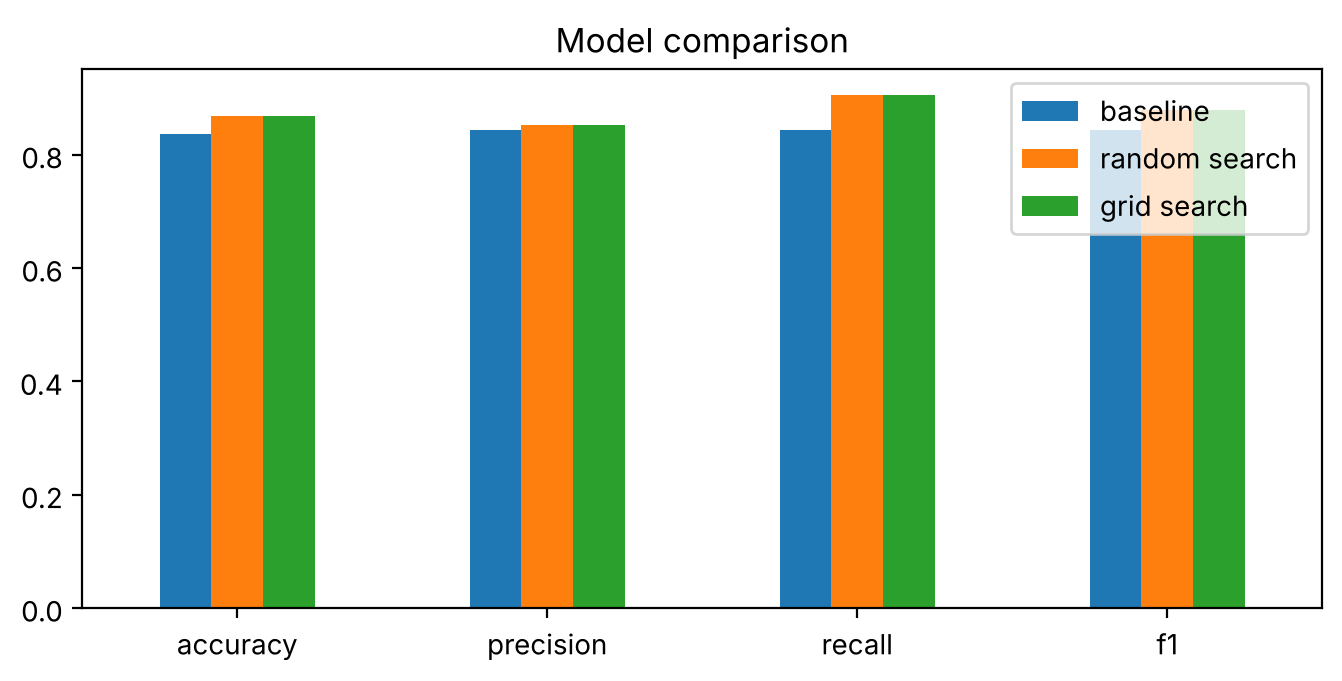

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

grid = {"n_estimators": [10, 100, 200, 500], "max_depth": [None, 5, 10, 20],
        "max_features": ["sqrt", "log2"], "min_samples_split": [2, 4, 6], "min_samples_leaf": [1, 2, 4]}
rs_clf = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), grid, n_iter=10, cv=5,
                            random_state=42).fit(X_train, y_train)
print("Randomized best:", rs_clf.best_params_)

grid_2 = {"n_estimators": [100, 200], "max_depth": [None, 10], "max_features": ["sqrt"],
          "min_samples_split": [2, 6], "min_samples_leaf": [1, 2]}
gs_clf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), grid_2, cv=5).fit(X_train, y_train)
print("Grid best:      ", gs_clf.best_params_)

results = {}
for name, model in [("baseline", RandomForestClassifier(random_state=42).fit(X_train, y_train)),
                    ("random search", rs_clf), ("grid search", gs_clf)]:
    p = model.predict(X_test)
    results[name] = {"accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                     "recall": recall_score(y_test, p), "f1": f1_score(y_test, p)}
compare = pd.DataFrame(results).round(3)
print(compare)
compare.plot.bar(figsize=(8, 3.5), rot=0, title="Model comparison"); plt.show()

<a id="saving-and-loading-models"></a>

### Saving and Loading Models

`pickle` can save any Python object. `joblib` is more efficient for objects that hold large NumPy arrays, which describes
most scikit-learn models. Two rules: only load files you trust (loading executes code), and load with the same
scikit-learn version you saved with.

In [40]:
from joblib import dump, load
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

dump(clf, "random-forest-model.joblib")
loaded = load("random-forest-model.joblib")
print("Same predictions after reload:", (loaded.predict(X_test) == clf.predict(X_test)).all())

Same predictions after reload: True


<a id="pipelines-preprocessing-and-model-as-one-object"></a>

### Pipelines: Preprocessing and Model as One Object

A `Pipeline` chains preprocessing and the model, so imputing, encoding and fitting happen in one `fit` call, and new data
goes through identical steps in `predict`. That removes a whole class of train/serve mismatch bugs. Hyperparameter search
works on the whole pipeline. Parameter names join the step and the parameter with a double underscore, for example
`"model__max_depth"` or `"preprocessor__num__imputer__strategy"`.

```mermaid
flowchart LR
    X[Raw X] --> CT
    subgraph CT[ColumnTransformer]
        C1["Make, Colour: impute 'missing' → one-hot"]
        C2["Doors: impute 4 → one-hot"]
        C3["Odometer: impute mean"]
    end
    CT --> M[RandomForestRegressor] --> P[Predictions]
```

The car-sales data is synthetic and noisy, so an R² around 0.2–0.3 is expected. The point here is the structure.

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

data = pd.read_csv(DATA / "car-sales-extended-missing-data.csv").dropna(subset=["Price"])
X, y = data.drop(columns="Price"), data["Price"]

categorical = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore"))])
door = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value=4)),
                 ("onehot", OneHotEncoder(handle_unknown="ignore"))])
numeric = Pipeline([("imputer", SimpleImputer(strategy="mean"))])
preprocessor = ColumnTransformer([("cat", categorical, ["Make", "Colour"]),
                                  ("door", door, ["Doors"]),
                                  ("num", numeric, ["Odometer (KM)"])])
model = Pipeline([("preprocessor", preprocessor), ("model", RandomForestRegressor(random_state=42))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
print("Pipeline R^2:", round(model.score(X_test, y_test), 3))

grid = {"preprocessor__num__imputer__strategy": ["mean", "median"],
        "model__n_estimators": [100, 500], "model__max_depth": [None, 5], "model__min_samples_split": [2, 4]}
gs_model = GridSearchCV(model, grid, cv=5).fit(X_train, y_train)
print("Best:", gs_model.best_params_)
print("Tuned pipeline R^2:", round(gs_model.score(X_test, y_test), 3))

Pipeline R^2: 0.212


Best: {'model__max_depth': 5, 'model__min_samples_split': 4, 'model__n_estimators': 500, 'preprocessor__num__imputer__strategy': 'mean'}
Tuned pipeline R^2: 0.336


#### Exercise 4

Build a heart-disease pipeline that scales features with `StandardScaler` and fits `LogisticRegression`. Tune `C` over
`np.logspace(-3, 3, 7)` with `GridSearchCV(cv=5)`, then print the best `C`, the test accuracy and the classification
report.

#### Solution 4

*Try it yourself before running this cell.*

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
search = GridSearchCV(pipe, {"logisticregression__C": np.logspace(-3, 3, 7)}, cv=5).fit(X_train, y_train)
print("Best C:", search.best_params_["logisticregression__C"])
print("Test accuracy:", round(search.score(X_test, y_test), 3))
print(classification_report(y_test, search.predict(X_test)))

Best C: 1.0
Test accuracy: 0.852
              precision    recall  f1-score   support

           0       0.83      0.86      0.85        29
           1       0.87      0.84      0.86        32

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



<a id="cheatsheet-scikit-learn"></a>

### Cheatsheet: scikit-learn

```python
X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train); model.predict(X_test); model.predict_proba(X_test); model.score(X_test, y_test)
cross_val_score(model, X, y, cv=5, scoring="accuracy")              # "f1", "neg_mean_absolute_error", ...
RocCurveDisplay.from_estimator(model, X_test, y_test); ConfusionMatrixDisplay.from_predictions(y_test, preds)
classification_report(y_test, preds); r2_score; mean_absolute_error; root_mean_squared_error
RandomizedSearchCV(model, grid, n_iter=20, cv=5); GridSearchCV(model, grid, cv=5); .best_params_; .best_estimator_
Pipeline([("pre", ColumnTransformer([...])), ("model", model)])   # grid keys: "model__max_depth"
dump(model, "model.joblib"); model = load("model.joblib")
```

| Default `score()` | Classifier | Regressor |
|---|---|---|
| metric | mean accuracy | R² |

| Removed API | Replacement |
|---|---|
| `load_boston` | `fetch_california_housing` |
| `plot_roc_curve`, `plot_confusion_matrix` | `RocCurveDisplay`, `ConfusionMatrixDisplay` |
| `max_features="auto"` | `"sqrt"`, `1.0` |

<a id="8-worked-example-predicting-heart-disease"></a>

## 8. Worked Example: Predicting Heart Disease

Time to put the framework and the scikit-learn workflow together on one question: *given a patient's clinical
measurements, can we predict whether they have heart disease?*

<a id="framing-the-problem"></a>

### Framing the Problem

- **Problem:** binary classification, heart disease or not.
- **Data:** the Cleveland heart-disease dataset from the UCI Machine Learning Repository: 303 patients, 13 features and a
  `target` column.
- **Evaluation:** a concrete goal makes the project decidable. Here: *if we can reach 95% accuracy in a proof of concept,
  we'll pursue it.*
- **Features:** understand every column before modelling. Becoming a subject-matter expert on the data is part of the job.

| Column | Meaning |
|---|---|
| `age`, `sex` | age in years; 1 = male, 0 = female |
| `cp` | chest pain type: 0 typical angina, 1 atypical angina, 2 non-anginal pain, 3 asymptomatic |
| `trestbps` | resting blood pressure (mm Hg) |
| `chol` | serum cholesterol (mg/dl) |
| `fbs` | fasting blood sugar > 120 mg/dl (1 = true) |
| `restecg` | resting ECG result (0–2) |
| `thalach` | maximum heart rate achieved |
| `exang` | exercise-induced angina (1 = yes) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | slope of the peak exercise ST segment (0–2) |
| `ca` | number of major vessels coloured by fluoroscopy (0–3) |
| `thal` | thalium stress result (1 normal, 2 fixed defect, 3 reversible defect) |
| `target` | 1 = heart disease, 0 = no heart disease |

<a id="exploratory-data-analysis"></a>

### Exploratory Data Analysis

Exploration answers a few questions before any modelling. What are we predicting? What types of data do we have? What's
missing, and where are the outliers? Could features be added, changed or removed?

The classes here are roughly balanced (54% / 46%) and nothing is missing, which is a good start.

(303, 14)
target
1    0.545
0    0.455
Name: proportion, dtype: float64
Missing values: 0


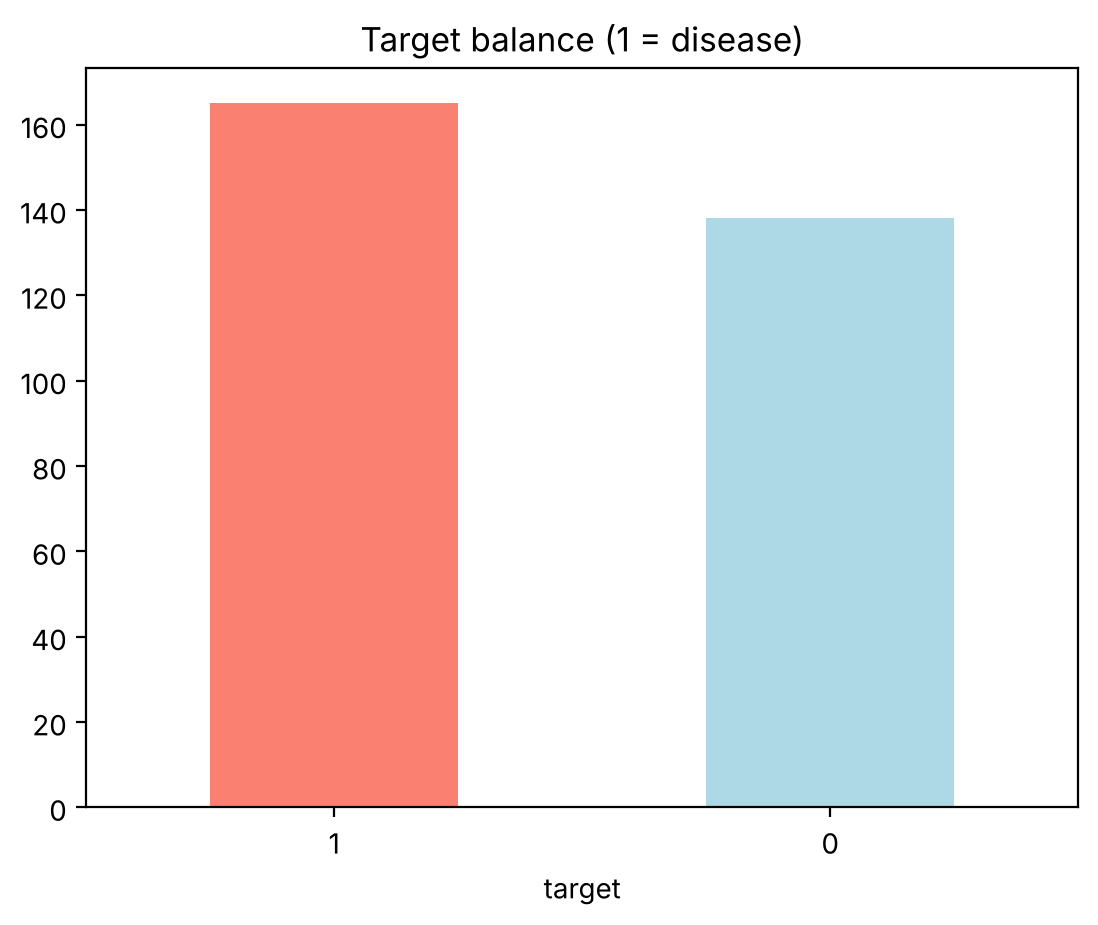

In [43]:
heart_disease = pd.read_csv(DATA / "heart-disease.csv")
print(heart_disease.shape)
print(heart_disease["target"].value_counts(normalize=True).round(3))
print("Missing values:", int(heart_disease.isna().sum().sum()))
heart_disease["target"].value_counts().plot(kind="bar", color=["salmon", "lightblue"], rot=0,
                                            title="Target balance (1 = disease)")
plt.show()

Next, compare the target against features one at a time:

- **Sex:** in this data about 75% of women have heart disease versus about 45% of men. Guessing from sex alone would be right
  roughly 61% of the time, which makes a useful **heuristic baseline** any model must beat.
- **Age vs maximum heart rate:** younger patients reach higher heart rates, and higher heart rates go with disease here.
- **Chest-pain type:** "atypical angina" (`cp = 1`) is surprisingly associated with disease. That's a question to take to
  a domain expert.
- **Correlation matrix:** `exang` correlates negatively with the target, while `cp` and `thalach` correlate positively.

These patterns describe this dataset, and they don't necessarily hold in the wider population.

sex      0    1
target         
0       24  114
1       72   93 



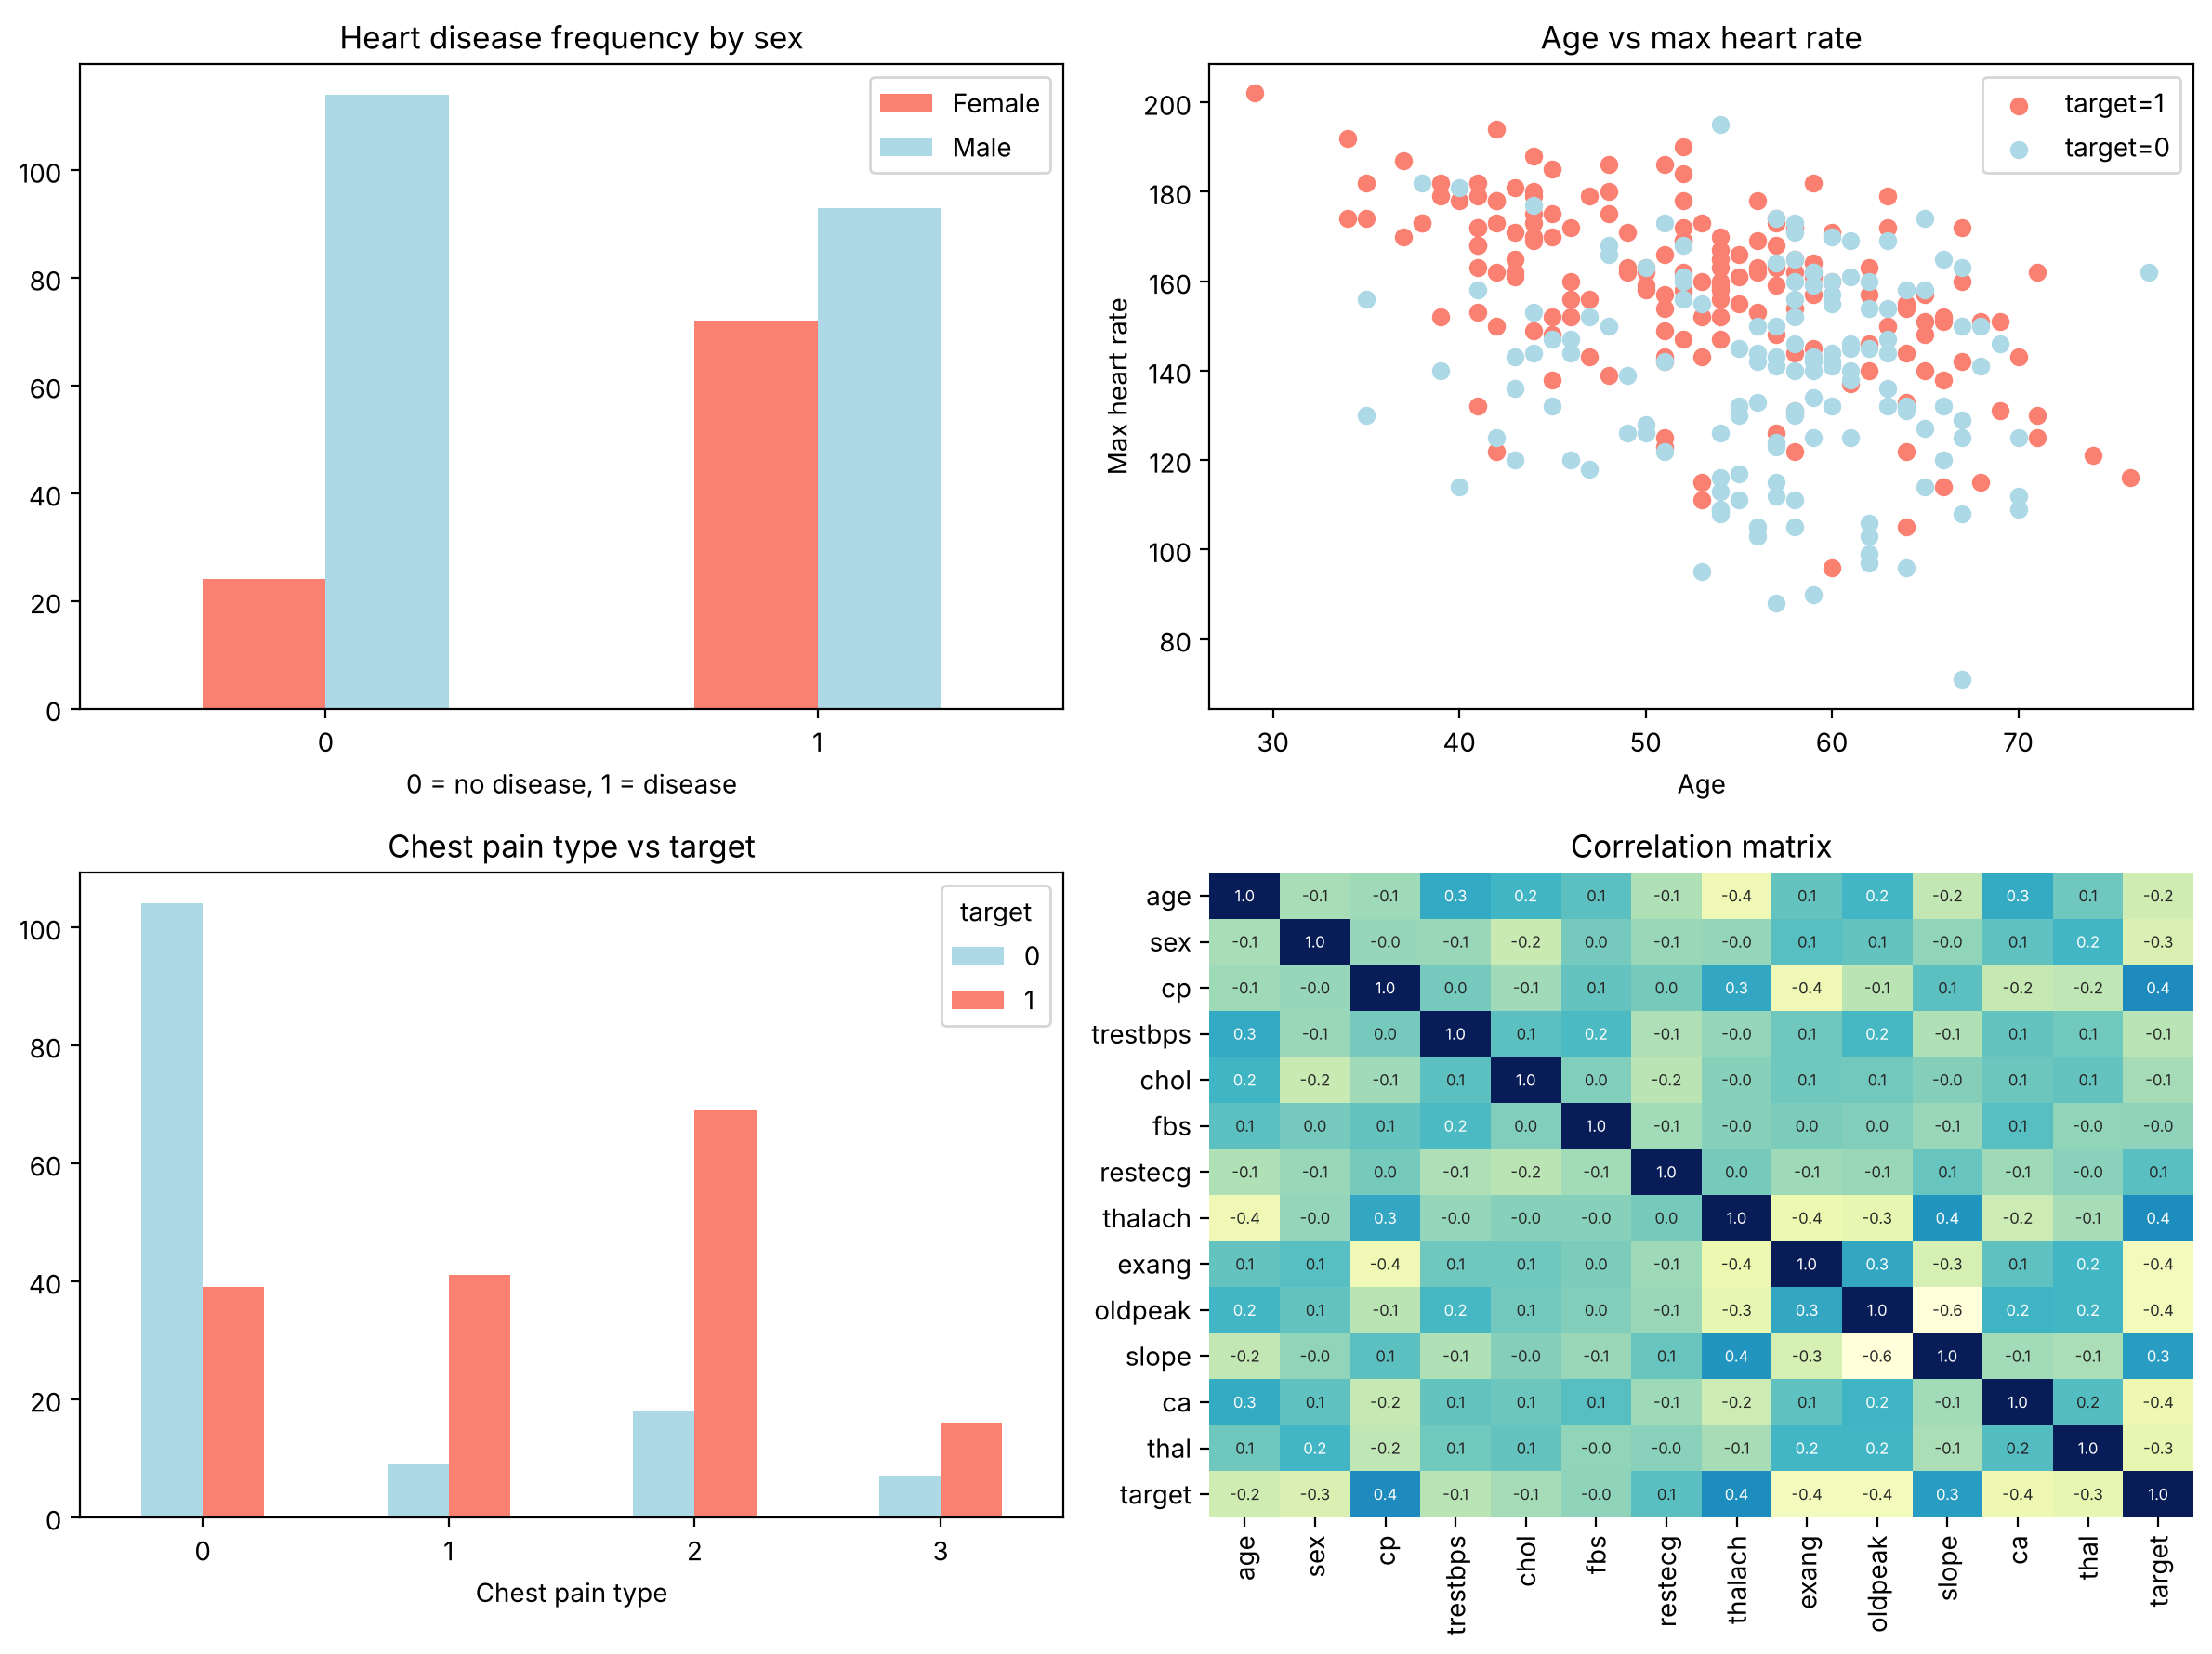

In [44]:
import seaborn as sns

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
print(pd.crosstab(heart_disease["target"], heart_disease["sex"]), "\n")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
pd.crosstab(heart_disease["target"], heart_disease["sex"]).plot(kind="bar", ax=axes[0, 0], rot=0,
                                                                  color=["salmon", "lightblue"])
axes[0, 0].set(title="Heart disease frequency by sex", xlabel="0 = no disease, 1 = disease")
axes[0, 0].legend(["Female", "Male"])

for target, colour in [(1, "salmon"), (0, "lightblue")]:
    subset = heart_disease[heart_disease["target"] == target]
    axes[0, 1].scatter(subset["age"], subset["thalach"], c=colour, label=f"target={target}")
axes[0, 1].set(title="Age vs max heart rate", xlabel="Age", ylabel="Max heart rate"); axes[0, 1].legend()

pd.crosstab(heart_disease["cp"], heart_disease["target"]).plot(kind="bar", ax=axes[1, 0], rot=0,
                                                                 color=["lightblue", "salmon"])
axes[1, 0].set(title="Chest pain type vs target", xlabel="Chest pain type")

sns.heatmap(heart_disease.corr(), annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1, 1], cbar=False,
            annot_kws={"size": 6})
axes[1, 1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

<a id="baseline-models"></a>

### Baseline Models

Split 80/20 with a fixed seed, never let the model see the test set, and try three different kinds of model: **logistic
regression** (a linear classifier, despite the name), **k-nearest neighbours** and a **random forest**. A small
`fit_and_score` helper keeps the comparison fair.

`LogisticRegression(max_iter=1000)` avoids the convergence warning that the default 100 iterations trigger on these unscaled
features. Scaling the features in a pipeline is the cleaner fix (see the exercise in section 7).

{'Logistic Regression': 0.885, 'KNN': 0.689, 'Random Forest': 0.836}


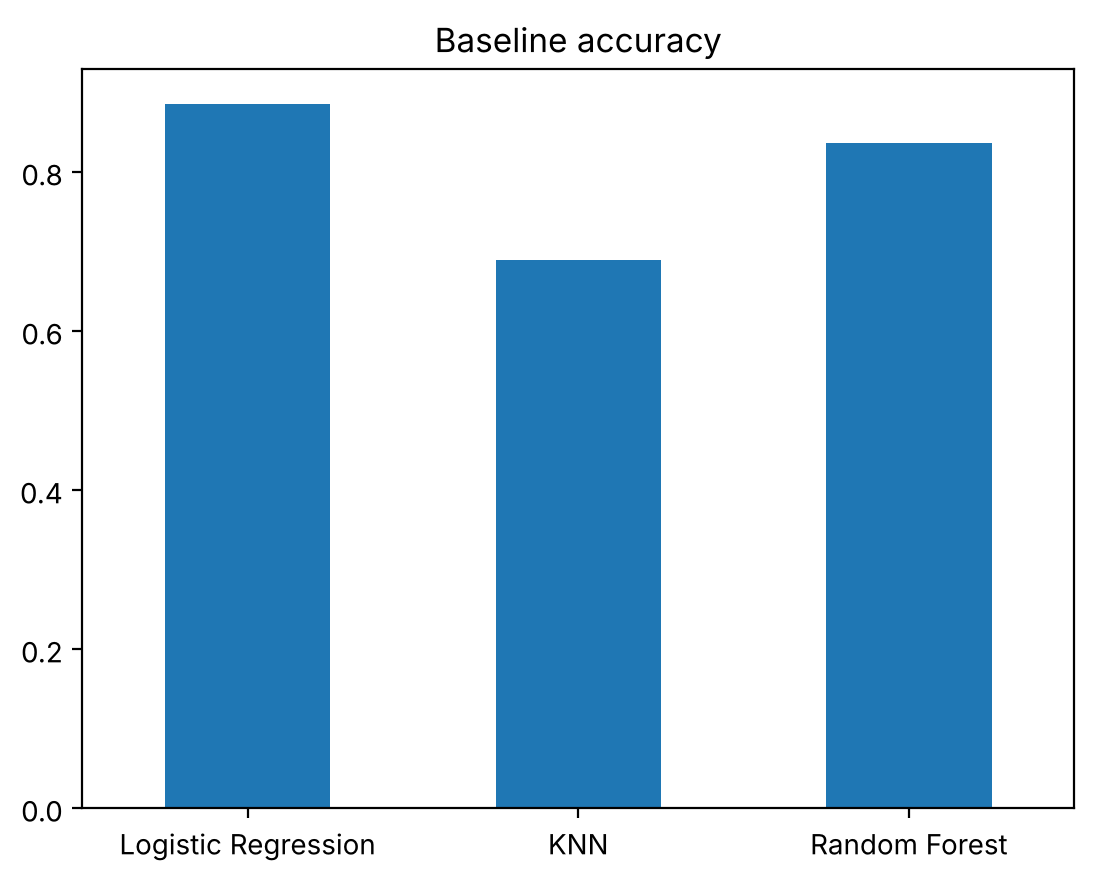

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "KNN": KNeighborsClassifier(),
          "Random Forest": RandomForestClassifier()}

def fit_and_score(models, X_train, X_test, y_train, y_test):
    """Fit each model and return its test accuracy."""
    np.random.seed(42)
    return {name: model.fit(X_train, y_train).score(X_test, y_test) for name, model in models.items()}

model_scores = fit_and_score(models, X_train, X_test, y_train, y_test)
print({k: round(v, 3) for k, v in model_scores.items()})
pd.DataFrame(model_scores, index=["accuracy"]).T.plot.bar(rot=0, legend=False, title="Baseline accuracy")
plt.show()

<a id="tuning-knn-by-hand"></a>

### Tuning KNN by Hand

Manual tuning is just a loop: change one hyperparameter with `set_params()`, refit, and record the training and test
scores. KNN tops out around 75%, well behind the other two, so it's dropped.

Best test accuracy: 75.41% at k=11


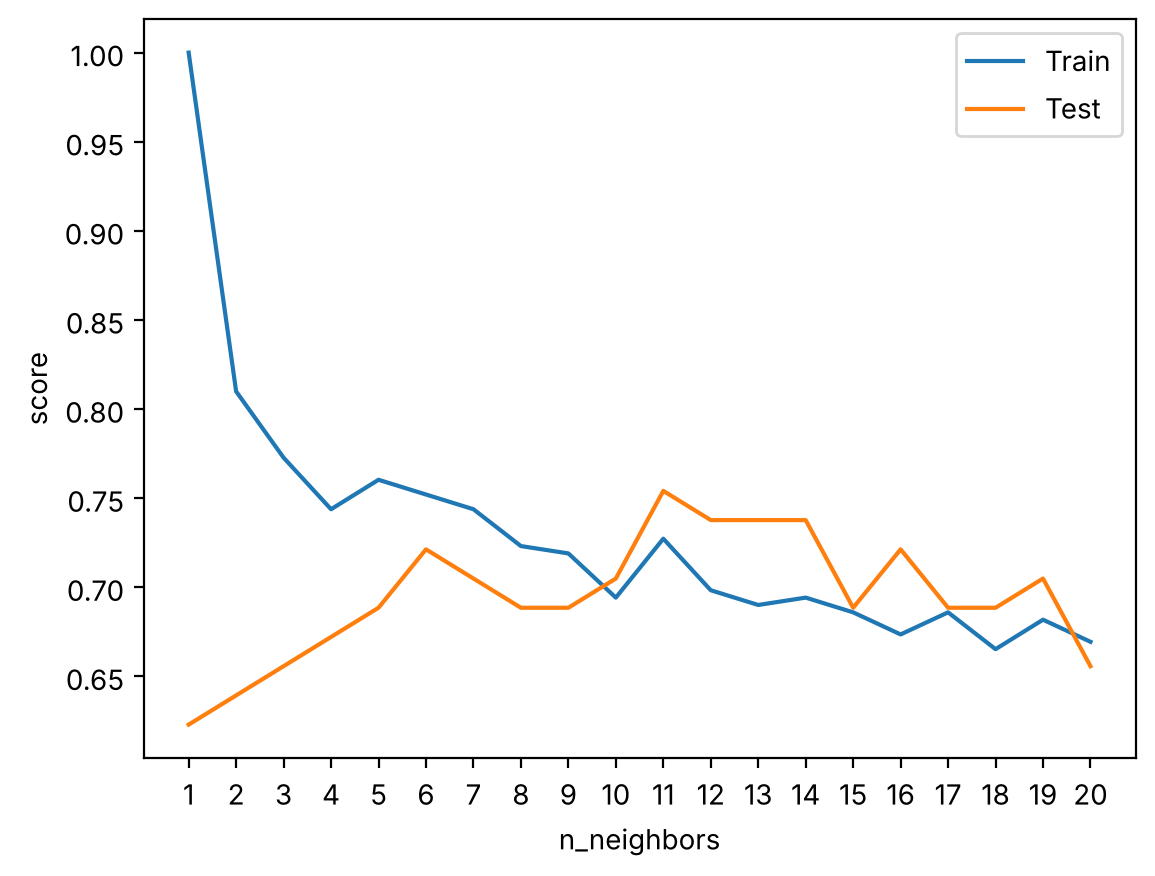

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

knn = KNeighborsClassifier()
neighbors, train_scores, test_scores = range(1, 21), [], []
for k in neighbors:
    knn.set_params(n_neighbors=k).fit(X_train, y_train)
    train_scores.append(knn.score(X_train, y_train)); test_scores.append(knn.score(X_test, y_test))

print(f"Best test accuracy: {max(test_scores) * 100:.2f}% at k={neighbors[int(np.argmax(test_scores))]}")
plt.plot(neighbors, train_scores, label="Train"); plt.plot(neighbors, test_scores, label="Test")
plt.xticks(range(1, 21)); plt.xlabel("n_neighbors"); plt.ylabel("score"); plt.legend(); plt.show()

<a id="tuning-logistic-regression-and-the-random-forest"></a>

### Tuning Logistic Regression and the Random Forest

`RandomizedSearchCV` explores logistic regression (`C` on a log scale) and the random forest (`n_estimators`, `max_depth`,
`min_samples_split`, `min_samples_leaf`). Logistic regression stays on top, so `GridSearchCV` refines its `C` over 30
values. Researching each model's hyperparameters in its documentation is worth the time.

In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

log_reg_grid = {"C": np.logspace(-4, 4, 20), "solver": ["liblinear"]}
rf_grid = {"n_estimators": np.arange(10, 1000, 50), "max_depth": [None, 3, 5, 10],
           "min_samples_split": np.arange(2, 20, 2), "min_samples_leaf": np.arange(1, 20, 2)}

rs_log_reg = RandomizedSearchCV(LogisticRegression(), log_reg_grid, cv=5, n_iter=20, random_state=42).fit(X_train, y_train)
rs_rf = RandomizedSearchCV(RandomForestClassifier(n_jobs=-1, random_state=42), rf_grid, cv=5, n_iter=20,
                           random_state=42).fit(X_train, y_train)
print("Randomized logistic regression:", round(rs_log_reg.score(X_test, y_test), 3), rs_log_reg.best_params_)
print("Randomized random forest:      ", round(rs_rf.score(X_test, y_test), 3))

gs_log_reg = GridSearchCV(LogisticRegression(), {"C": np.logspace(-4, 4, 30), "solver": ["liblinear"]},
                          cv=5).fit(X_train, y_train)
print("Grid logistic regression:      ", round(gs_log_reg.score(X_test, y_test), 3), gs_log_reg.best_params_)

Randomized logistic regression: 0.885 {'solver': 'liblinear', 'C': np.float64(0.23357214690901212)}
Randomized random forest:       0.869


Grid logistic regression:       0.885 {'C': np.float64(0.20433597178569415), 'solver': 'liblinear'}


<a id="evaluating-beyond-accuracy"></a>

### Evaluating Beyond Accuracy

For a medical model, the costly mistake is a **false negative**: telling a sick patient they're fine. So look at the ROC
curve, the confusion matrix and the classification report, and report **cross-validated** precision, recall and F1
rather than the numbers from one split.

              precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61

{'accuracy': np.float64(0.845), 'precision': np.float64(0.821), 'recall': np.float64(0.921), 'f1': np.float64(0.867)}


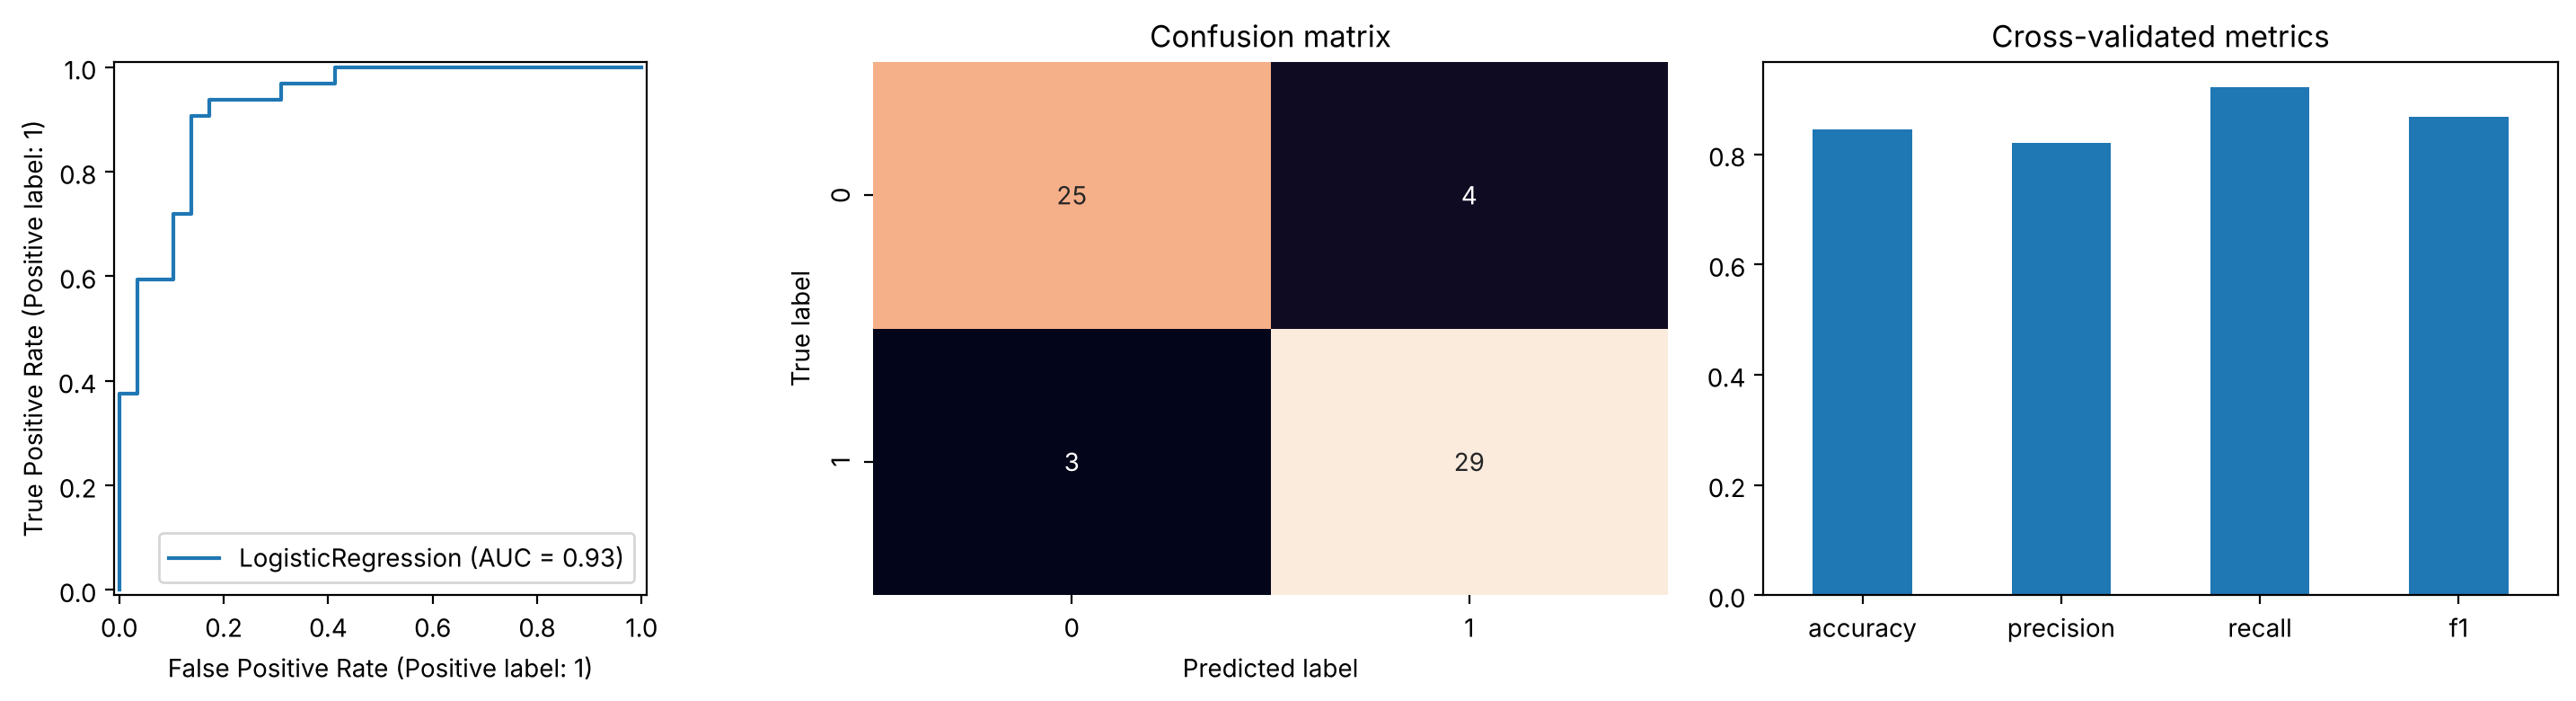

In [48]:
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score, train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

best_C = 0.20433597178569418                        # best value found by the grid search above
clf = LogisticRegression(C=best_C, solver="liblinear").fit(X_train, y_train)
y_preds = clf.predict(X_test)
print(classification_report(y_test, y_preds))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=axes[0])
sns.heatmap(confusion_matrix(y_test, y_preds), annot=True, cbar=False, ax=axes[1])
axes[1].set(xlabel="Predicted label", ylabel="True label", title="Confusion matrix")

cv_metrics = {m: cross_val_score(clf, X, y, cv=5, scoring=m).mean() for m in ["accuracy", "precision", "recall", "f1"]}
pd.Series(cv_metrics).plot.bar(ax=axes[2], rot=0, title="Cross-validated metrics")
print({k: round(v, 3) for k, v in cv_metrics.items()})
plt.tight_layout(); plt.show()

<a id="which-features-matter"></a>

### Which Features Matter

For logistic regression, the coefficients in `coef_` act as feature importance. Positive values push the prediction
towards disease, and negative values push it away. They line up with the exploration: `sex` has a strong negative
coefficient (in this data, the disease rate drops as `sex` goes from 0 to 1), and `slope` a positive one.

**Watch out:** coefficients are only comparable when features share a scale. Standardize first, or use model-agnostic
permutation importance, which is covered in the
[Data Preparation reference](https://github.com/rokon-uddin/data-preparation-reference).

sex        -0.914
thal       -0.670
ca         -0.639
exang      -0.562
oldpeak    -0.494
fbs        -0.021
trestbps   -0.015
chol       -0.003
age         0.007
thalach     0.028
restecg     0.322
slope       0.371
cp          0.705
dtype: float64


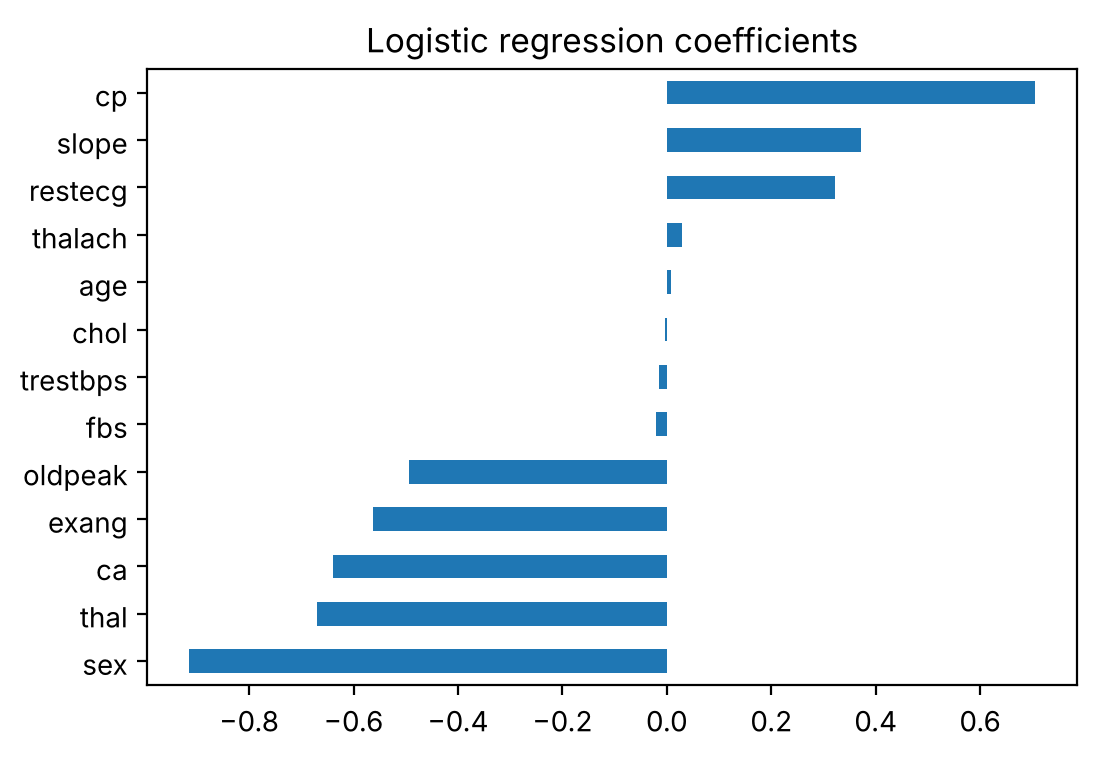

target   0    1
slope          
0       12    9
1       91   49
2       35  107


In [49]:
from sklearn.linear_model import LogisticRegression

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
clf = LogisticRegression(C=0.20433597178569418, solver="liblinear").fit(X, y)

feature_importance = pd.Series(clf.coef_[0], index=X.columns).sort_values()
print(feature_importance.round(3))
feature_importance.plot.barh(title="Logistic regression coefficients", figsize=(6, 4)); plt.show()
print(pd.crosstab(heart_disease["slope"], heart_disease["target"]))

<a id="where-this-leaves-us"></a>

### Where This Leaves Us

The tuned model reaches about 88% on the test split, which is short of the 95% goal. The honest options are to collect more
data, try stronger models (gradient boosting such as XGBoost, LightGBM or CatBoost), keep improving the current ones, or
decide the current performance is good enough for its purpose and share it. Missing a target is a normal outcome. It's
the framework that tells you so early.

<a id="cheatsheet-classification-project"></a>

### Cheatsheet: Classification Project

```python
df["target"].value_counts(normalize=True); pd.crosstab(df["target"], df["sex"]); sns.heatmap(df.corr(), annot=True)
models = {"lr": LogisticRegression(max_iter=1000), "knn": KNeighborsClassifier(), "rf": RandomForestClassifier()}
RandomizedSearchCV(LogisticRegression(), {"C": np.logspace(-4, 4, 20), "solver": ["liblinear"]}, cv=5, n_iter=20)
RocCurveDisplay.from_estimator(clf, X_test, y_test); classification_report(y_test, y_preds)
cross_val_score(clf, X, y, cv=5, scoring="recall"); pd.Series(clf.coef_[0], index=X.columns)
```

<a id="9-worked-example-predicting-bulldozer-prices"></a>

## 9. Worked Example: Predicting Bulldozer Prices

The second project is regression on time-ordered data, from Kaggle's *Blue Book for Bulldozers* competition: predict the
auction sale price of a bulldozer from its characteristics and the prices of similar machines in past sales.

<a id="the-problem-and-the-metric"></a>

### The Problem and the Metric

- **Data:** `Train.csv` (sales up to the end of 2011), `Valid.csv` (January–April 2012) and `Test.csv` (May–November 2012).
  `TrainAndValid.csv` combines the first two: about 412,000 rows and 53 columns, described in the competition's data
  dictionary.
- **Metric:** **RMSLE** (root mean squared log error). Errors are measured on a log scale, so a $5,000 miss on a $20,000
  machine counts far more than the same miss on a $200,000 one. Lower is better.

In [50]:
# Download the competition data (72 MB) (a public mirror of the Kaggle files) if needed.
import zipfile
from urllib.request import urlretrieve

BULLDOZER = DATA / "bluebook-for-bulldozers"
if not (BULLDOZER / "TrainAndValid.csv").exists():
    url = "https://raw.githubusercontent.com/mrdbourke/zero-to-mastery-ml/master/data/bluebook-for-bulldozers.zip"
    zip_path, _ = urlretrieve(url, DATA / "bluebook-for-bulldozers.zip")
    zipfile.ZipFile(zip_path).extractall(DATA)
print(sorted(p.name for p in BULLDOZER.glob("*.csv")))

['Machine_Appendix.csv', 'Test.csv', 'Train.csv', 'TrainAndValid.csv', 'Valid.csv', 'ValidSolution.csv', 'median_benchmark.csv', 'random_forest_benchmark_test.csv', 'test_predictions.csv', 'train_tmp.csv']


<a id="parsing-and-sorting-dates"></a>

### Parsing and Sorting Dates

Read the file with `low_memory=False` (some columns have mixed types) and `parse_dates=["saledate"]` so the sale date
becomes a real datetime instead of text. With time-series data, sort by date, because order matters when you split.

(412698, 53)
datetime64[us] | 1989-01-17 -> 2012-04-28


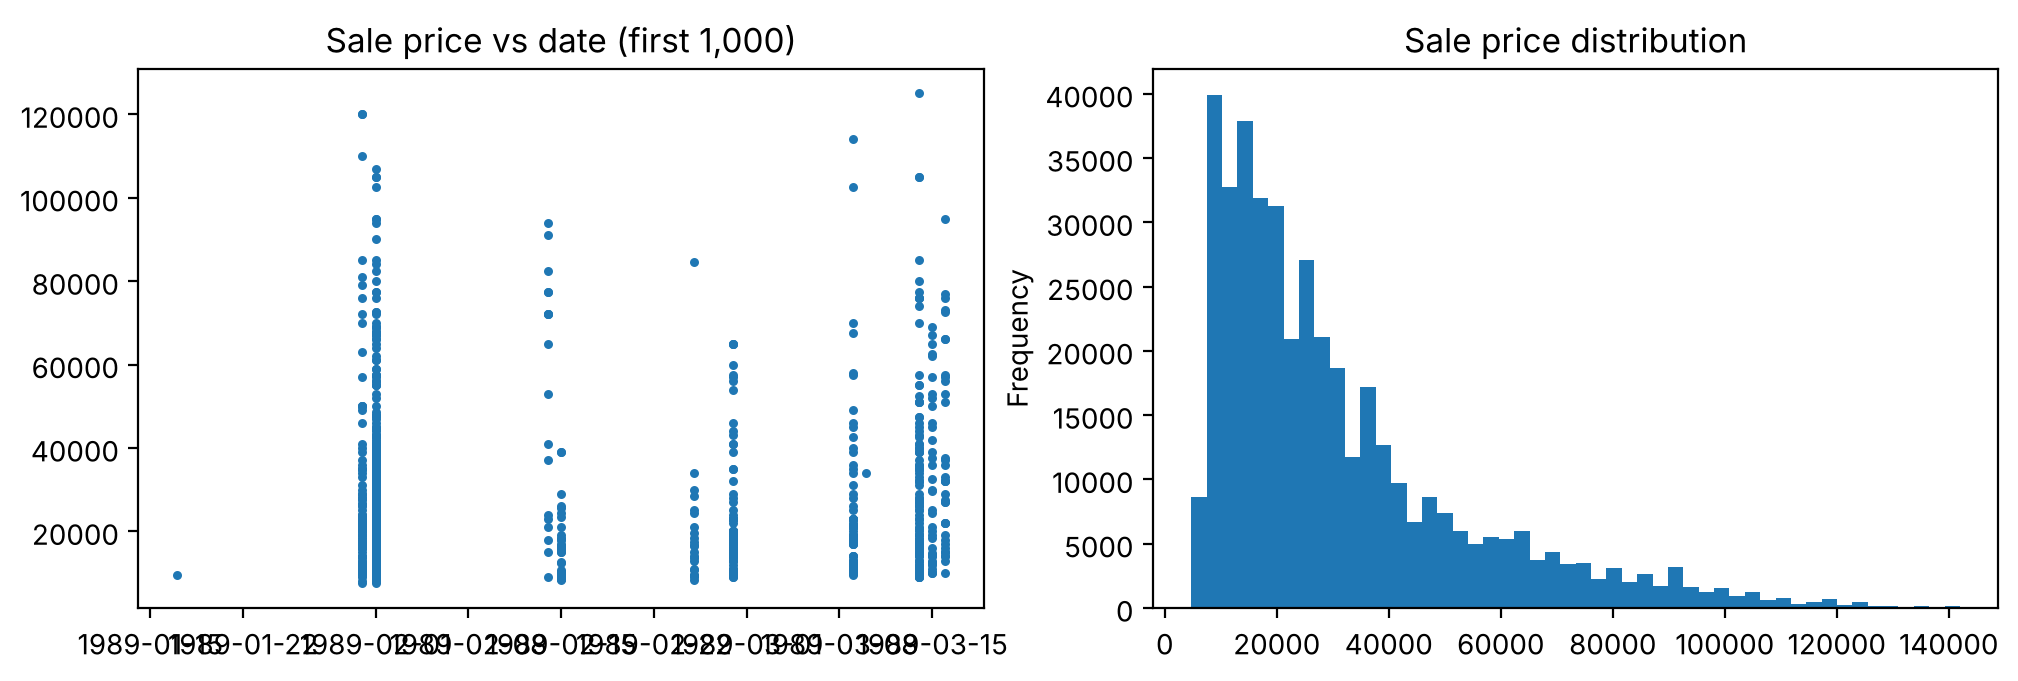

In [51]:
BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
print(df.shape)
print(df["saledate"].dtype, "|", df["saledate"].min().date(), "->", df["saledate"].max().date())
df = df.sort_values(by="saledate").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].scatter(df["saledate"][:1000], df["SalePrice"][:1000], s=5); axes[0].set_title("Sale price vs date (first 1,000)")
df["SalePrice"].plot.hist(bins=50, ax=axes[1], title="Sale price distribution")
plt.show()

<a id="feature-engineering-from-dates"></a>

### Feature Engineering from Dates

A raw timestamp means little to a tree model, but its parts carry signal: year, month, day, day of week and day of year
(auctions may follow seasons and weekly patterns). Add them as columns and drop the original.

In [52]:
BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
df = df.sort_values("saledate").reset_index(drop=True)

def add_datetime_features(frame):
    """Expand 'saledate' into numeric date parts and drop the original column."""
    frame = frame.copy()
    frame["saleYear"] = frame["saledate"].dt.year
    frame["saleMonth"] = frame["saledate"].dt.month
    frame["saleDay"] = frame["saledate"].dt.day
    frame["saleDayofweek"] = frame["saledate"].dt.dayofweek
    frame["saleDayofyear"] = frame["saledate"].dt.dayofyear
    return frame.drop(columns="saledate")

df = add_datetime_features(df)
print(df[["saleYear", "saleMonth", "saleDay", "saleDayofweek", "saleDayofyear"]].head(3))
print("Missing values in the 10 worst columns:\n", df.isna().sum().sort_values(ascending=False).head(10))

   saleYear  saleMonth  saleDay  saleDayofweek  saleDayofyear
0      1989          1       17              1             17
1      1989          1       31              1             31
2      1989          1       31              1             31


Missing values in the 10 worst columns:
 Blade_Width          386715
Enclosure_Type       386715
Engine_Horsepower    386715
Tip_Control          386715
Pushblock            386715
Blade_Extension      386715
Scarifier            386704
Grouser_Tracks       367823
Hydraulics_Flow      367823
Coupler_System       367724
dtype: int64


<a id="turning-everything-into-numbers"></a>

### Turning Everything into Numbers

The quick pandas approach turns every text column into the `category` dtype and then into integer codes (adding 1 so
missing becomes 0 instead of −1). It fills numeric gaps with the **median**, which is robust to outliers, and adds a binary
`<column>_is_missing` flag for each, because the fact that a value is missing can itself be informative.

In [53]:
# The quick pandas-only approach, on a sample of rows.
BULLDOZER = DATA / "bluebook-for-bulldozers"
df_tmp = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"], nrows=50_000)

for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if content.isna().any():
            df_tmp[label + "_is_missing"] = content.isna()
            df_tmp[label] = content.fillna(content.median())
    elif not pd.api.types.is_datetime64_any_dtype(content):
        df_tmp[label + "_is_missing"] = content.isna()
        df_tmp[label] = pd.Categorical(content).codes + 1          # missing (-1) becomes 0

print("Remaining missing values:", int(df_tmp.isna().sum().sum()))
print(df_tmp[["UsageBand", "UsageBand_is_missing", "MachineHoursCurrentMeter",
              "MachineHoursCurrentMeter_is_missing"]].head(3))

Remaining missing values: 0
   UsageBand  UsageBand_is_missing  MachineHoursCurrentMeter  \
0          2                 False                      68.0   
1          2                 False                    4640.0   
2          1                 False                    2838.0   

   MachineHoursCurrentMeter_is_missing  
0                                False  
1                                False  
2                                False  


**Watch out:** doing this on the full dataset *before* splitting lets the validation rows influence the medians and the
category codes, which is mild leakage. The test set would also need exactly the same mapping later. The rest of this
section does the same work (median fills, missing-value flags, categories as integers) inside a `ColumnTransformer` fitted
on the training data only.

<a id="splitting-by-time-and-measuring-honestly"></a>

### Splitting by Time and Measuring Honestly

Fit a model on everything and score it on the same data, and you'll see a suspiciously good R². Evaluation matters as much
as fitting.

The split has to mirror reality. **Train on sales before 2012 and validate on 2012**, the same way the competition splits.
Never shuffle time-ordered data. A `show_scores()` helper reports MAE, RMSLE and R² on both sets, so overfitting shows up
as a gap between them.

`max_samples=10_000` makes each tree train on a random 10,000 rows. That gives slightly lower accuracy but experiments run
in seconds rather than minutes, which is what you want while you're still exploring.

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, root_mean_squared_log_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"

def add_datetime_features(frame):
    """Expand 'saledate' into numeric date parts and drop the original column."""
    frame = frame.copy()
    d = frame["saledate"].dt
    frame["saleYear"], frame["saleMonth"], frame["saleDay"] = d.year, d.month, d.day
    frame["saleDayofweek"], frame["saleDayofyear"] = d.dayofweek, d.dayofyear
    return frame.drop(columns="saledate")

df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
df = add_datetime_features(df.sort_values("saledate"))
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]
X_train, y_train = train.drop(columns="SalePrice"), train["SalePrice"]
X_valid, y_valid = valid.drop(columns="SalePrice"), valid["SalePrice"]
print("train:", X_train.shape, "valid:", X_valid.shape)

categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = X_train.select_dtypes(include="number").columns.tolist()
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), numeric),    # median + *_is_missing flags
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                           encoded_missing_value=-1), categorical),            # categories -> integers
])

def show_scores(model):
    """MAE, RMSLE and R^2 on the training and validation sets."""
    train_preds, valid_preds = model.predict(X_train), model.predict(X_valid)
    return {"Training MAE": mean_absolute_error(y_train, train_preds),
            "Valid MAE": mean_absolute_error(y_valid, valid_preds),
            "Training RMSLE": root_mean_squared_log_error(y_train, train_preds),
            "Valid RMSLE": root_mean_squared_log_error(y_valid, valid_preds),
            "Training R^2": r2_score(y_train, train_preds), "Valid R^2": r2_score(y_valid, valid_preds)}

# max_samples=10_000: each tree sees 10,000 rows, so experiments take seconds instead of minutes.
quick_model = Pipeline([("prep", preprocessor),
                        ("model", RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000))])
quick_model.fit(X_train, y_train)
print({k: round(v, 3) for k, v in show_scores(quick_model).items()})

train: (401125, 56) valid: (11573, 56)


{'Training MAE': 5561.9, 'Valid MAE': 7167.082, 'Training RMSLE': 0.258, 'Valid RMSLE': 0.293, 'Training R^2': 0.861, 'Valid R^2': 0.832}


<a id="tuning-and-faster-alternatives"></a>

### Tuning and Faster Alternatives

`RandomizedSearchCV` over `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` and `max_features` (still on
the 10,000-row samples) finds good settings cheaply. A forest with 40 trees, `min_samples_split=14` and `max_features=0.5`,
trained on all the rows, is a strong configuration for this data.

`HistGradientBoostingRegressor` is a much faster alternative at this scale and handles missing values natively. RMSLE needs
non-negative predictions, so clip them at zero.

In [55]:
import time
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_log_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"

def add_datetime_features(frame):
    frame = frame.copy()
    d = frame["saledate"].dt
    frame["saleYear"], frame["saleMonth"], frame["saleDay"] = d.year, d.month, d.day
    frame["saleDayofweek"], frame["saleDayofyear"] = d.dayofweek, d.dayofyear
    return frame.drop(columns="saledate")

df = add_datetime_features(pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False,
                                       parse_dates=["saledate"]).sort_values("saledate"))
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]
X_train, y_train = train.drop(columns="SalePrice"), train["SalePrice"]
X_valid, y_valid = valid.drop(columns="SalePrice"), valid["SalePrice"]
categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = X_train.select_dtypes(include="number").columns.tolist()

def make_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), numeric),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1),
         categorical)])

rf_grid = {"model__n_estimators": np.arange(10, 100, 10), "model__max_depth": [None, 3, 5, 10],
           "model__min_samples_split": np.arange(2, 20, 2), "model__min_samples_leaf": np.arange(1, 20, 2),
           "model__max_features": [0.5, 1.0, "sqrt"]}
search = RandomizedSearchCV(
    Pipeline([("prep", make_preprocessor()),
              ("model", RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000))]),
    rf_grid, n_iter=5, cv=3, random_state=42).fit(X_train, y_train)
print("Best (randomized, 5 iterations):", search.best_params_)

start = time.time()
ideal_model = Pipeline([("prep", make_preprocessor()),
                        ("model", RandomForestRegressor(n_estimators=40, min_samples_leaf=1, min_samples_split=14,
                                                        max_features=0.5, n_jobs=-1, random_state=42))])
ideal_model.fit(X_train, y_train)
print(f"Ideal random forest: valid RMSLE {root_mean_squared_log_error(y_valid, ideal_model.predict(X_valid)):.4f} "
      f"({time.time() - start:.0f}s)")

start = time.time()
hgb = Pipeline([("prep", make_preprocessor()), ("model", HistGradientBoostingRegressor(max_iter=500, random_state=42))])
hgb.fit(X_train, y_train)
preds = np.clip(hgb.predict(X_valid), 0, None)               # RMSLE needs non-negative predictions
print(f"HistGradientBoosting: valid RMSLE {root_mean_squared_log_error(y_valid, preds):.4f} ({time.time() - start:.0f}s)")

Best (randomized, 5 iterations): {'model__n_estimators': np.int64(60), 'model__min_samples_split': np.int64(12), 'model__min_samples_leaf': np.int64(1), 'model__max_features': 1.0, 'model__max_depth': None}


Ideal random forest: valid RMSLE 0.2464 (42s)


HistGradientBoosting: valid RMSLE 0.2645 (28s)


<a id="predicting-on-the-test-set"></a>

### Predicting on the Test Set

The test data must go through *exactly* the same preprocessing as the training data. With hand-written pandas steps, that's
where bugs creep in, for example a `_is_missing` column that never appears because the test set has no gaps in that column.
A fitted pipeline avoids the whole problem. It applies the learned medians and category mappings, and unseen categories map
to −1 instead of crashing.

The final model trains on train + validation together, and predictions are written in the competition's format of two
columns, `SalesID` and `SalePrice`.

In [56]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"

def add_datetime_features(frame):
    frame = frame.copy()
    d = frame["saledate"].dt
    frame["saleYear"], frame["saleMonth"], frame["saleDay"] = d.year, d.month, d.day
    frame["saleDayofweek"], frame["saleDayofyear"] = d.dayofweek, d.dayofyear
    return frame.drop(columns="saledate")

df = add_datetime_features(pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False,
                                       parse_dates=["saledate"]))
X, y = df.drop(columns="SalePrice"), df["SalePrice"]
categorical = X.select_dtypes(exclude="number").columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()
final_model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), numeric),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1),
         categorical)])),
    ("model", RandomForestRegressor(n_estimators=40, min_samples_split=14, max_features=0.5,
                                    n_jobs=-1, random_state=42))]).fit(X, y)       # train + valid together

df_test = add_datetime_features(pd.read_csv(BULLDOZER / "Test.csv", low_memory=False, parse_dates=["saledate"]))
submission = pd.DataFrame({"SalesID": df_test["SalesID"], "SalePrice": final_model.predict(df_test)})
submission.to_csv("bulldozer-test-predictions.csv", index=False)
print(submission.shape); print(submission.head())

(12457, 2)
   SalesID     SalePrice
0  1227829  15051.187195
1  1227844  32045.696113
2  1227847  51317.514947
3  1227848  95011.549423
4  1227863  27797.279957


<a id="what-drives-the-price"></a>

### What Drives the Price

A random forest's `feature_importances_` show which columns drove the predictions. `YearMade` and `ProductSize` come out
on top, which makes sense: newer, bigger machines cost more. Results like this are worth checking with someone who knows
the domain, and they make the model far easier to explain to stakeholders.

YearMade              0.182
ProductSize           0.145
Enclosure             0.081
fiSecondaryDesc       0.075
saleYear              0.070
fiProductClassDesc    0.051
ModelID               0.046
fiModelDesc           0.042
SalesID               0.041
fiBaseModel           0.031
dtype: float64


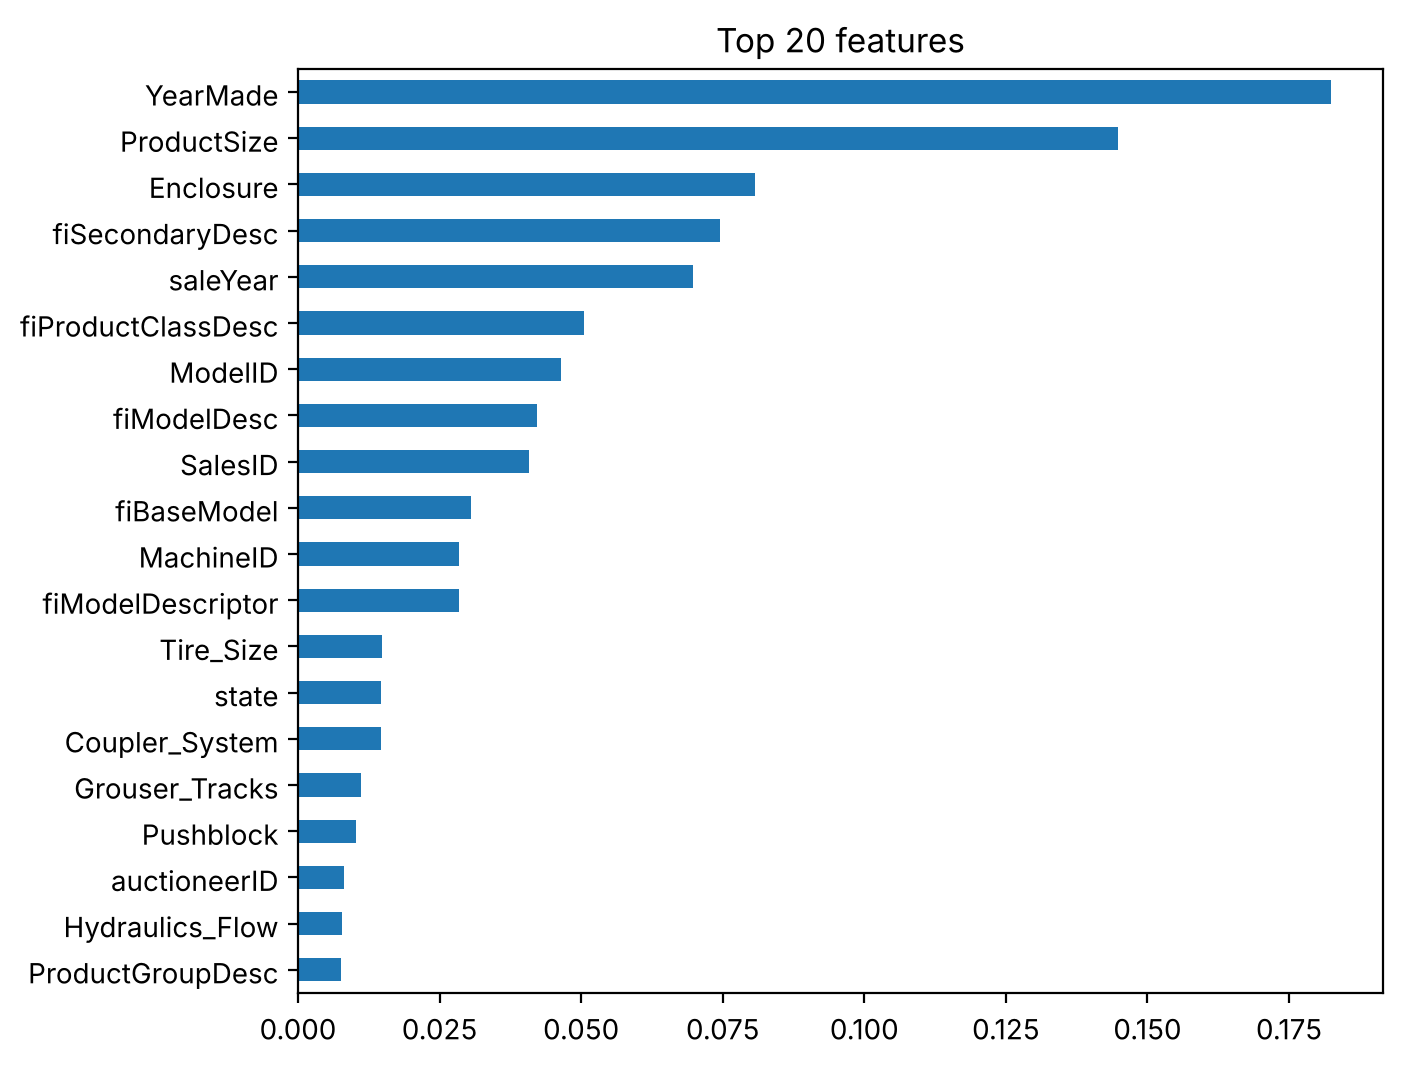

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
df["saleYear"] = df["saledate"].dt.year
df = df.drop(columns="saledate")
X, y = df.drop(columns="SalePrice"), df["SalePrice"]
categorical = X.select_dtypes(exclude="number").columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

model = Pipeline([
    ("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), numeric),
                                ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                       encoded_missing_value=-1), categorical)],
                               verbose_feature_names_out=False)),
    ("model", RandomForestRegressor(n_estimators=40, max_features=0.5, max_samples=50_000,
                                    n_jobs=-1, random_state=42))]).fit(X, y)

importances = pd.Series(model["model"].feature_importances_, index=model["prep"].get_feature_names_out())
top = importances.sort_values(ascending=False).head(20)
print(top.round(3).head(10))
top.sort_values().plot.barh(figsize=(7, 6), title="Top 20 features"); plt.show()

#### Exercise 5

On the bulldozer data, compare validation RMSLE for three ways of handling the categorical columns, using the date features
and `RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000)` where a forest is used: `OrdinalEncoder`,
dropping the categorical columns entirely, and `HistGradientBoostingRegressor(categorical_features="from_dtype")` with
native categorical support (which allows at most 255 categories per column).

#### Solution 5

*Try it yourself before running this cell.*

In [58]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_log_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
d = df["saledate"].dt
df["saleYear"], df["saleMonth"], df["saleDayofyear"] = d.year, d.month, d.dayofyear
df = df.drop(columns="saledate")
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]
X_train, y_train, X_valid, y_valid = (train.drop(columns="SalePrice"), train["SalePrice"],
                                      valid.drop(columns="SalePrice"), valid["SalePrice"])
cat = X_train.select_dtypes(exclude="number").columns.tolist()
num = X_train.select_dtypes(include="number").columns.tolist()
rf = lambda: RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000)

candidates = {
    "ordinal encoder": Pipeline([("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), cat)])),
        ("model", rf())]),
    "numeric only": Pipeline([("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), num)])),
                              ("model", rf())]),
}
for name, model in candidates.items():
    model.fit(X_train, y_train)
    print(f"{name:16s} RMSLE {root_mean_squared_log_error(y_valid, model.predict(X_valid)):.4f}")

# Native categorical support allows at most 255 categories per column, so high-cardinality
# columns (e.g. fiModelDesc, ~5,000 values) become integer codes instead.
low_card = [c for c in cat if X_train[c].nunique() <= 255]
categories = {c: pd.Categorical(X_train[c]).categories for c in cat}       # learned from training data only
def prepare(frame):
    frame = frame.copy()
    for c in cat:
        values = pd.Categorical(frame[c], categories=categories[c])
        frame[c] = values if c in low_card else values.codes           # unseen/missing -> -1
    return frame
hgb = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=42).fit(prepare(X_train), y_train)
preds = np.clip(hgb.predict(prepare(X_valid)), 0, None)
print(f"{'native categorical':16s} RMSLE {root_mean_squared_log_error(y_valid, preds):.4f}")

ordinal encoder  RMSLE 0.2917


numeric only     RMSLE 0.4649


native categorical RMSLE 0.2753


<a id="cheatsheet-time-series-regression"></a>

### Cheatsheet: Time-Series Regression

```python
df = pd.read_csv(path, low_memory=False, parse_dates=["saledate"]).sort_values("saledate")
df["saleYear"] = df["saledate"].dt.year          # .month .day .dayofweek .dayofyear
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]     # split by time, never randomly
ColumnTransformer([("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
                   ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                          encoded_missing_value=-1), cat_cols)])
RandomForestRegressor(n_jobs=-1, max_samples=10_000)     # fast experiments
root_mean_squared_log_error(y_valid, preds)               # replaces mean_squared_log_error(..., squared=False)
```

<a id="10-deep-learning-and-transfer-learning"></a>

## 10. Deep Learning and Transfer Learning

Tree ensembles rule structured data, but images, audio and text need a different tool. This section builds an image
classifier that recognizes dog breeds, using TensorFlow, Keras and **transfer learning**.

<a id="neural-networks-tensorflow-and-transfer-learning"></a>

### Neural Networks, TensorFlow and Transfer Learning

Deep learning (multi-layer neural networks) is still "finding patterns in data", but the network learns its own features,
from edges to textures to shapes, instead of relying on hand-made columns. **TensorFlow** is Google's open-source library
for fast numerical computing on GPUs and TPUs, and **Keras** is its high-level API. Since Keras 3, Keras can also run on JAX
or PyTorch.

Training an image model from scratch takes millions of images and a lot of compute. **Transfer learning** sidesteps that.
You take a network already trained on ImageNet (1.4 million images, 1,000 classes), keep its feature-extracting layers
frozen, and train only a small new output layer for your own classes.

```mermaid
flowchart LR
    I["Image (224 × 224 × 3)"] --> B["Pretrained base: EfficientNetV2B0<br/>frozen, learned on ImageNet"]
    B --> V["Feature vector (1,280 numbers)"] --> D["New Dense layer + softmax<br/>trained on our breeds"] --> P["Probability per breed"]
```

A **GPU** runs the matrix maths inside neural networks in parallel, which makes training 10–30× faster than on a CPU.
Google Colab offers free GPUs (*Runtime → Change runtime type*). On Apple Silicon, `tensorflow-metal` uses the local GPU.

> **About the outputs in this section.** The machine that produced this post couldn't download the Stanford Dogs images or
> the pretrained ImageNet weights, so the code fell back to a tiny generated stand-in dataset and untrained weights. The
> outputs below show the pipeline running end to end, **not** real accuracy. With an internet connection (and ideally a
> GPU), the same code downloads the real data and weights.

In [59]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: False


<a id="getting-the-images"></a>

### Getting the Images

The **Stanford Dogs** dataset has 20,580 images of 120 breeds, one folder per breed. That layout makes loading
straightforward. Before training, check the data matches your expectations: count the images per class and look at a few.

In [60]:
# Download Stanford Dogs (~750 MB). If that isn't possible, build a tiny stand-in dataset so the pipeline still runs.
import tarfile
import tensorflow as tf
from PIL import Image

DOGS_DIR = DATA / "stanford-dogs" / "Images"
USING_STAND_IN = False
if not DOGS_DIR.exists():
    try:
        tar_path = tf.keras.utils.get_file(
            "images.tar", "http://vision.stanford.edu/aditya86/ImageNetDogs/images.tar", cache_dir=".")
        with tarfile.open(tar_path) as tar:
            tar.extractall(DATA / "stanford-dogs")
    except Exception as err:                                  # offline / blocked: generate stand-in images
        print("Could not download Stanford Dogs:", type(err).__name__)
        USING_STAND_IN = True
        DOGS_DIR = DATA / "stand-in-dogs"
        rng = np.random.default_rng(42)
        for i, breed in enumerate(["n0000-beagle", "n0001-boxer", "n0002-collie", "n0003-pug", "n0004-whippet"]):
            (DOGS_DIR / breed).mkdir(parents=True, exist_ok=True)
            tint = np.array([40 * i + 40, 200 - 30 * i, 120 + 25 * i])
            for j in range(40):
                noise = rng.integers(0, 80, size=(160, 160, 3))
                Image.fromarray(np.clip(noise + tint, 0, 255).astype("uint8")).save(DOGS_DIR / breed / f"{j}.jpg")

breed_dirs = sorted(p for p in DOGS_DIR.iterdir() if p.is_dir())
counts = pd.Series({p.name.split("-", 1)[1]: len(list(p.glob("*.jpg"))) for p in breed_dirs})
print(f"{'STAND-IN DATA — ' if USING_STAND_IN else ''}{len(breed_dirs)} classes, {counts.sum()} images")
print(counts.describe().round(1))

Could not download Stanford Dogs: Exception
STAND-IN DATA — 5 classes, 200 images
count     5.0
mean     40.0
std       0.0
min      40.0
25%      40.0
50%      40.0
75%      40.0
max      40.0
dtype: float64


<a id="from-files-to-batches-of-tensors"></a>

### From Files to Batches of Tensors

A **tensor** is like a NumPy array that can live on a GPU. Each image becomes a tensor of shape `(224, 224, 3)`. That's the
size the pretrained model expects, and every image in a batch must share one shape.

`tf.keras.utils.image_dataset_from_directory` does the heavy lifting in one call:

- reads and decodes the image files and resizes them to 224 × 224,
- infers labels from folder names, one-hot encoded with `label_mode="categorical"`,
- splits off a validation set (`validation_split` with `subset="both"`),
- groups images into **batches** of 32 and shuffles the training data.

Add `.prefetch(tf.data.AUTOTUNE)` so loading the next batch overlaps with training on the current one.

**Watch out:** EfficientNetV2 models in `tf.keras.applications` include their own rescaling layer and expect raw 0–255
pixels, so don't divide by 255 yourself. Always check what preprocessing a pretrained model expects.

In [61]:
import tensorflow as tf

IMG_SIZE, BATCH_SIZE = (224, 224), 32
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    DOGS_DIR, label_mode="categorical", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    validation_split=0.2, subset="both", seed=42)
class_names = [name.split("-", 1)[1] for name in train_ds.class_names]

images, labels = next(iter(train_ds))
print("image batch:", images.shape, images.dtype, "| label batch:", labels.shape)
print("first label (one-hot):", labels[0].numpy().astype(int), "->", class_names[int(np.argmax(labels[0]))])

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)

Found 200 files belonging to 5 classes.


Using 160 files for training.


Using 40 files for validation.


image batch: (32, 224, 224, 3) <dtype: 'float32'> | label batch: (32, 5)
first label (one-hot): [0 0 0 1 0] -> pug


Always look at a batch before training. It's the cheapest way to catch a preprocessing bug.

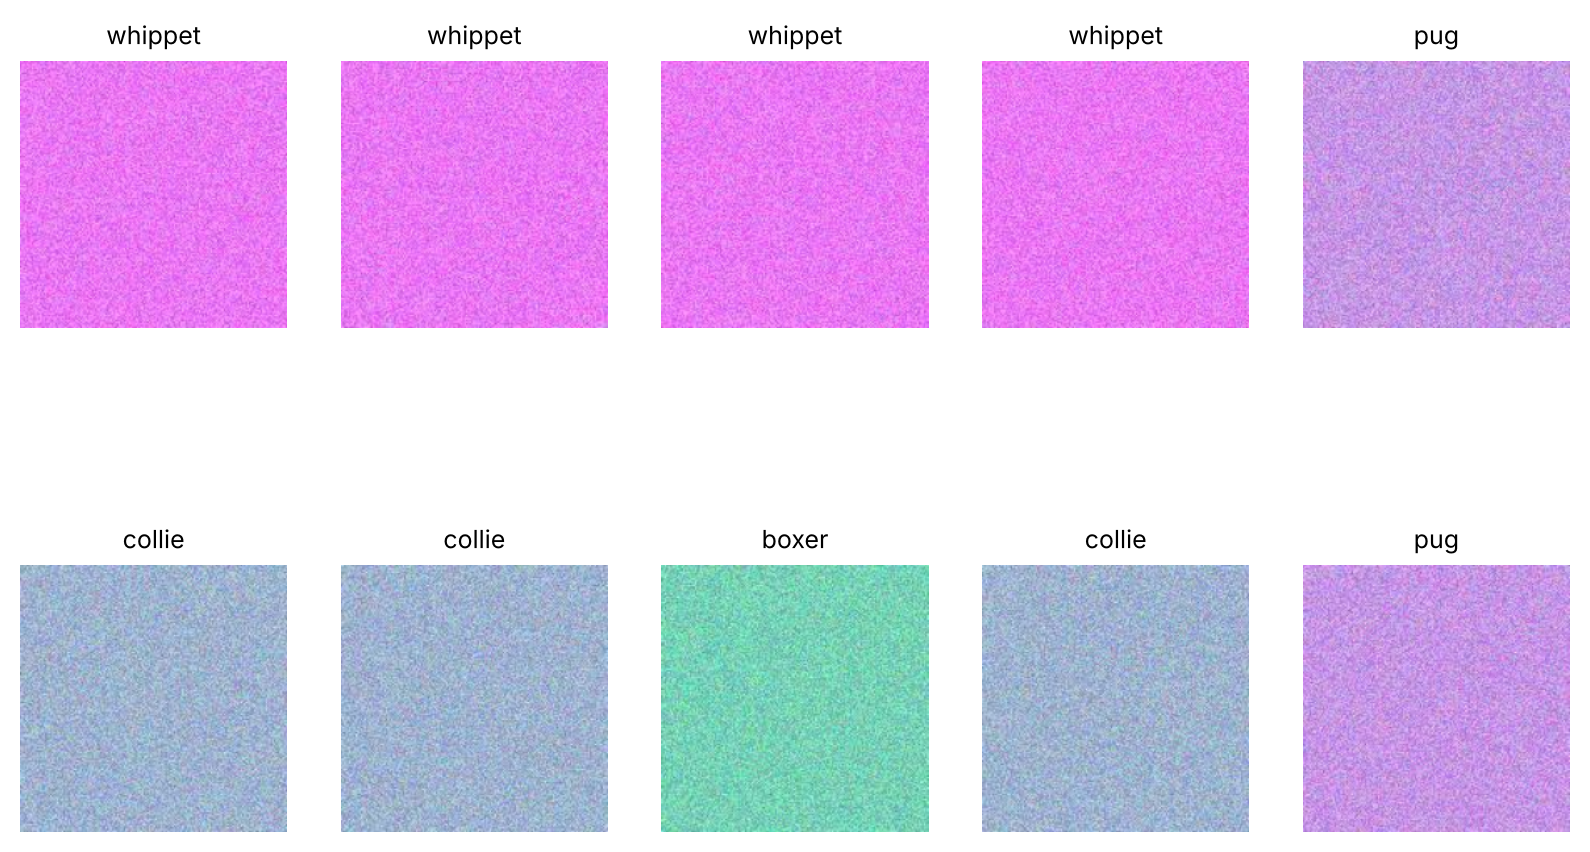

In [62]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(min(10, len(images))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(np.argmax(labels[i]))], fontsize=9)
    plt.axis("off")
plt.show()

<a id="building-the-model"></a>

### Building the Model

The model is the frozen pretrained base plus one new `Dense` layer with **softmax** activation, which turns the outputs into
probabilities between 0 and 1 that sum to 1.

Compiling sets three things:

- a **loss** that measures how wrong the model is: `CategoricalCrossentropy` for one-hot labels,
- an **optimizer** that decides how to adjust the weights to reduce the loss: `Adam` is a reliable default,
- **metrics** to report, such as `accuracy`.

The Functional API (`inputs → base → outputs`) is used here because it scales to more complex architectures. The `try` block
falls back to untrained weights only if the ImageNet weights can't be downloaded.

In [63]:
import tensorflow as tf

NUM_CLASSES = len(class_names)

def create_model(num_classes=NUM_CLASSES, img_size=IMG_SIZE):
    """Frozen EfficientNetV2B0 feature extractor + a softmax classification head."""
    try:
        base = tf.keras.applications.EfficientNetV2B0(include_top=False, weights="imagenet",
                                                      input_shape=img_size + (3,), pooling="avg")
    except Exception as err:                       # weights not downloadable: same architecture, untrained
        print("ImageNet weights unavailable (", type(err).__name__, ") - using untrained weights for a dry run.")
        base = tf.keras.applications.EfficientNetV2B0(include_top=False, weights=None,
                                                      input_shape=img_size + (3,), pooling="avg")
    base.trainable = False                         # transfer learning: keep the pretrained features

    inputs = tf.keras.Input(shape=img_size + (3,), name="input_layer")
    x = base(inputs, training=False)               # 0-255 pixels in; the model rescales internally
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="output_layer")(x)
    model = tf.keras.Model(inputs, outputs, name="dog_vision")
    model.compile(loss=tf.keras.losses.CategoricalCrossentropy(),
                  optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  metrics=["accuracy"])
    return model

model = create_model()
model.summary(show_trainable=True)

ImageNet weights unavailable ( Exception ) - using untrained weights for a dry run.


Model: "dog_vision"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetv2-b0           │ (None, 1280)          │  5,919,312 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ output_layer (Dense)        │ (None, 5)             │      6,405 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 5,925,717 (22.60 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

<a id="training-with-callbacks"></a>

### Training with Callbacks

**Callbacks** run during training. **TensorBoard** logs metrics so you can watch the curves (`%load_ext tensorboard`, then
`%tensorboard --logdir logs`). **EarlyStopping** halts training when the validation metric stops improving and restores
the best weights, which is a cheap guard against overfitting.

An **epoch** is one pass over the training data. Start with a small subset so you know the pipeline works before you spend
GPU time. Then watch for the overfitting signature: training accuracy racing ahead while validation accuracy stalls.

Epoch 1/2


5/5 - 11s - 2s/step - accuracy: 0.3438 - loss: 1.6066 - val_accuracy: 0.6000 - val_loss: 1.5995


Epoch 2/2


5/5 - 2s - 472ms/step - accuracy: 0.5312 - loss: 1.5954 - val_accuracy: 0.6000 - val_loss: 1.5892


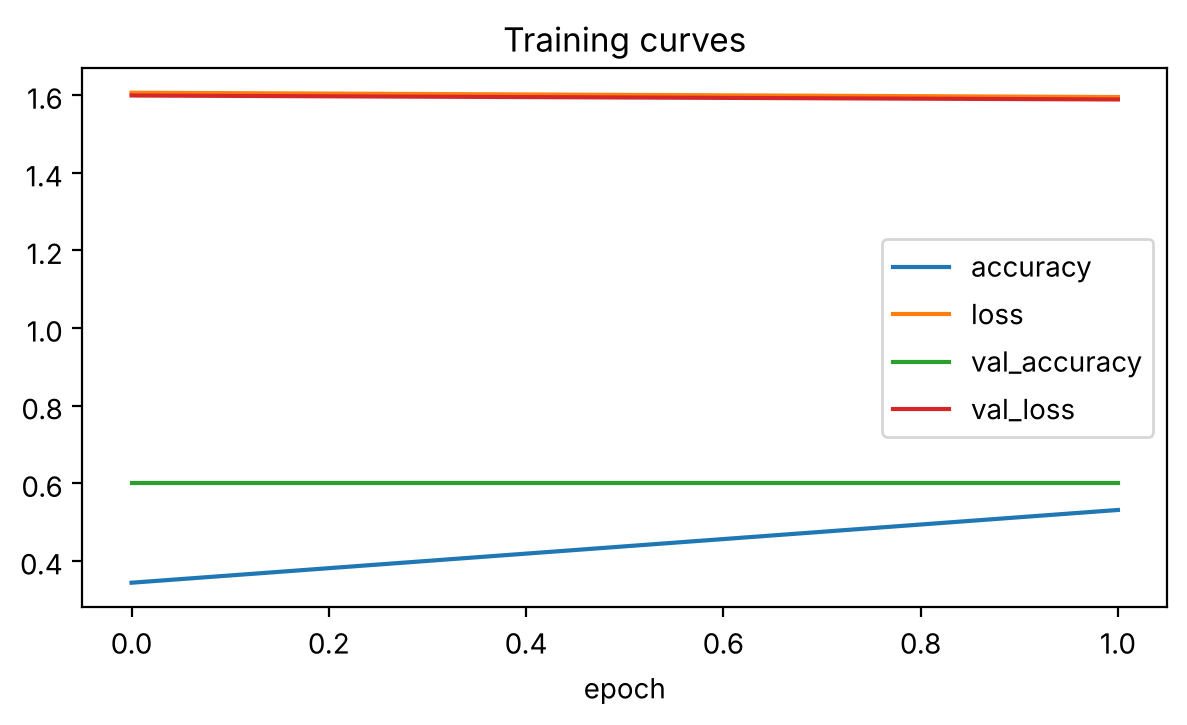

In [64]:
import datetime
import tensorflow as tf

log_dir = Path("logs") / datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
callbacks = [tf.keras.callbacks.TensorBoard(log_dir=str(log_dir)),
             tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)]

EPOCHS = 2 if USING_STAND_IN else 10
history = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)

pd.DataFrame(history.history).plot(figsize=(7, 3.5), title="Training curves"); plt.xlabel("epoch"); plt.show()

<a id="turning-probabilities-into-predictions"></a>

### Turning Probabilities into Predictions

`model.predict` returns a probability for every class for every image. `argmax` picks the most likely class index, which
maps back to a breed name.

In [65]:
pred_probs = model.predict(valid_ds, verbose=0)
y_true = np.concatenate([np.argmax(labels, axis=1) for _, labels in valid_ds])
y_pred = pred_probs.argmax(axis=1)

def get_pred_label(probabilities):
    """Turn one row of prediction probabilities into a breed name."""
    return class_names[int(np.argmax(probabilities))]

print("probabilities shape:", pred_probs.shape)
print("first image: predicted", get_pred_label(pred_probs[0]), f"({pred_probs[0].max():.2f}) | actual",
      class_names[y_true[0]])
print("validation accuracy:", round(float((y_pred == y_true).mean()), 3))

probabilities shape: (40, 5)
first image: predicted whippet (0.20) | actual whippet
validation accuracy: 0.6


Visualizing predictions makes them understandable to anyone. The cell shows each image with its predicted label and
confidence (green if right, red if wrong) above a bar chart of the top-10 probabilities. With 120 classes, per-class accuracy
and a confusion matrix reveal which breeds get mixed up, usually the ones that look alike.

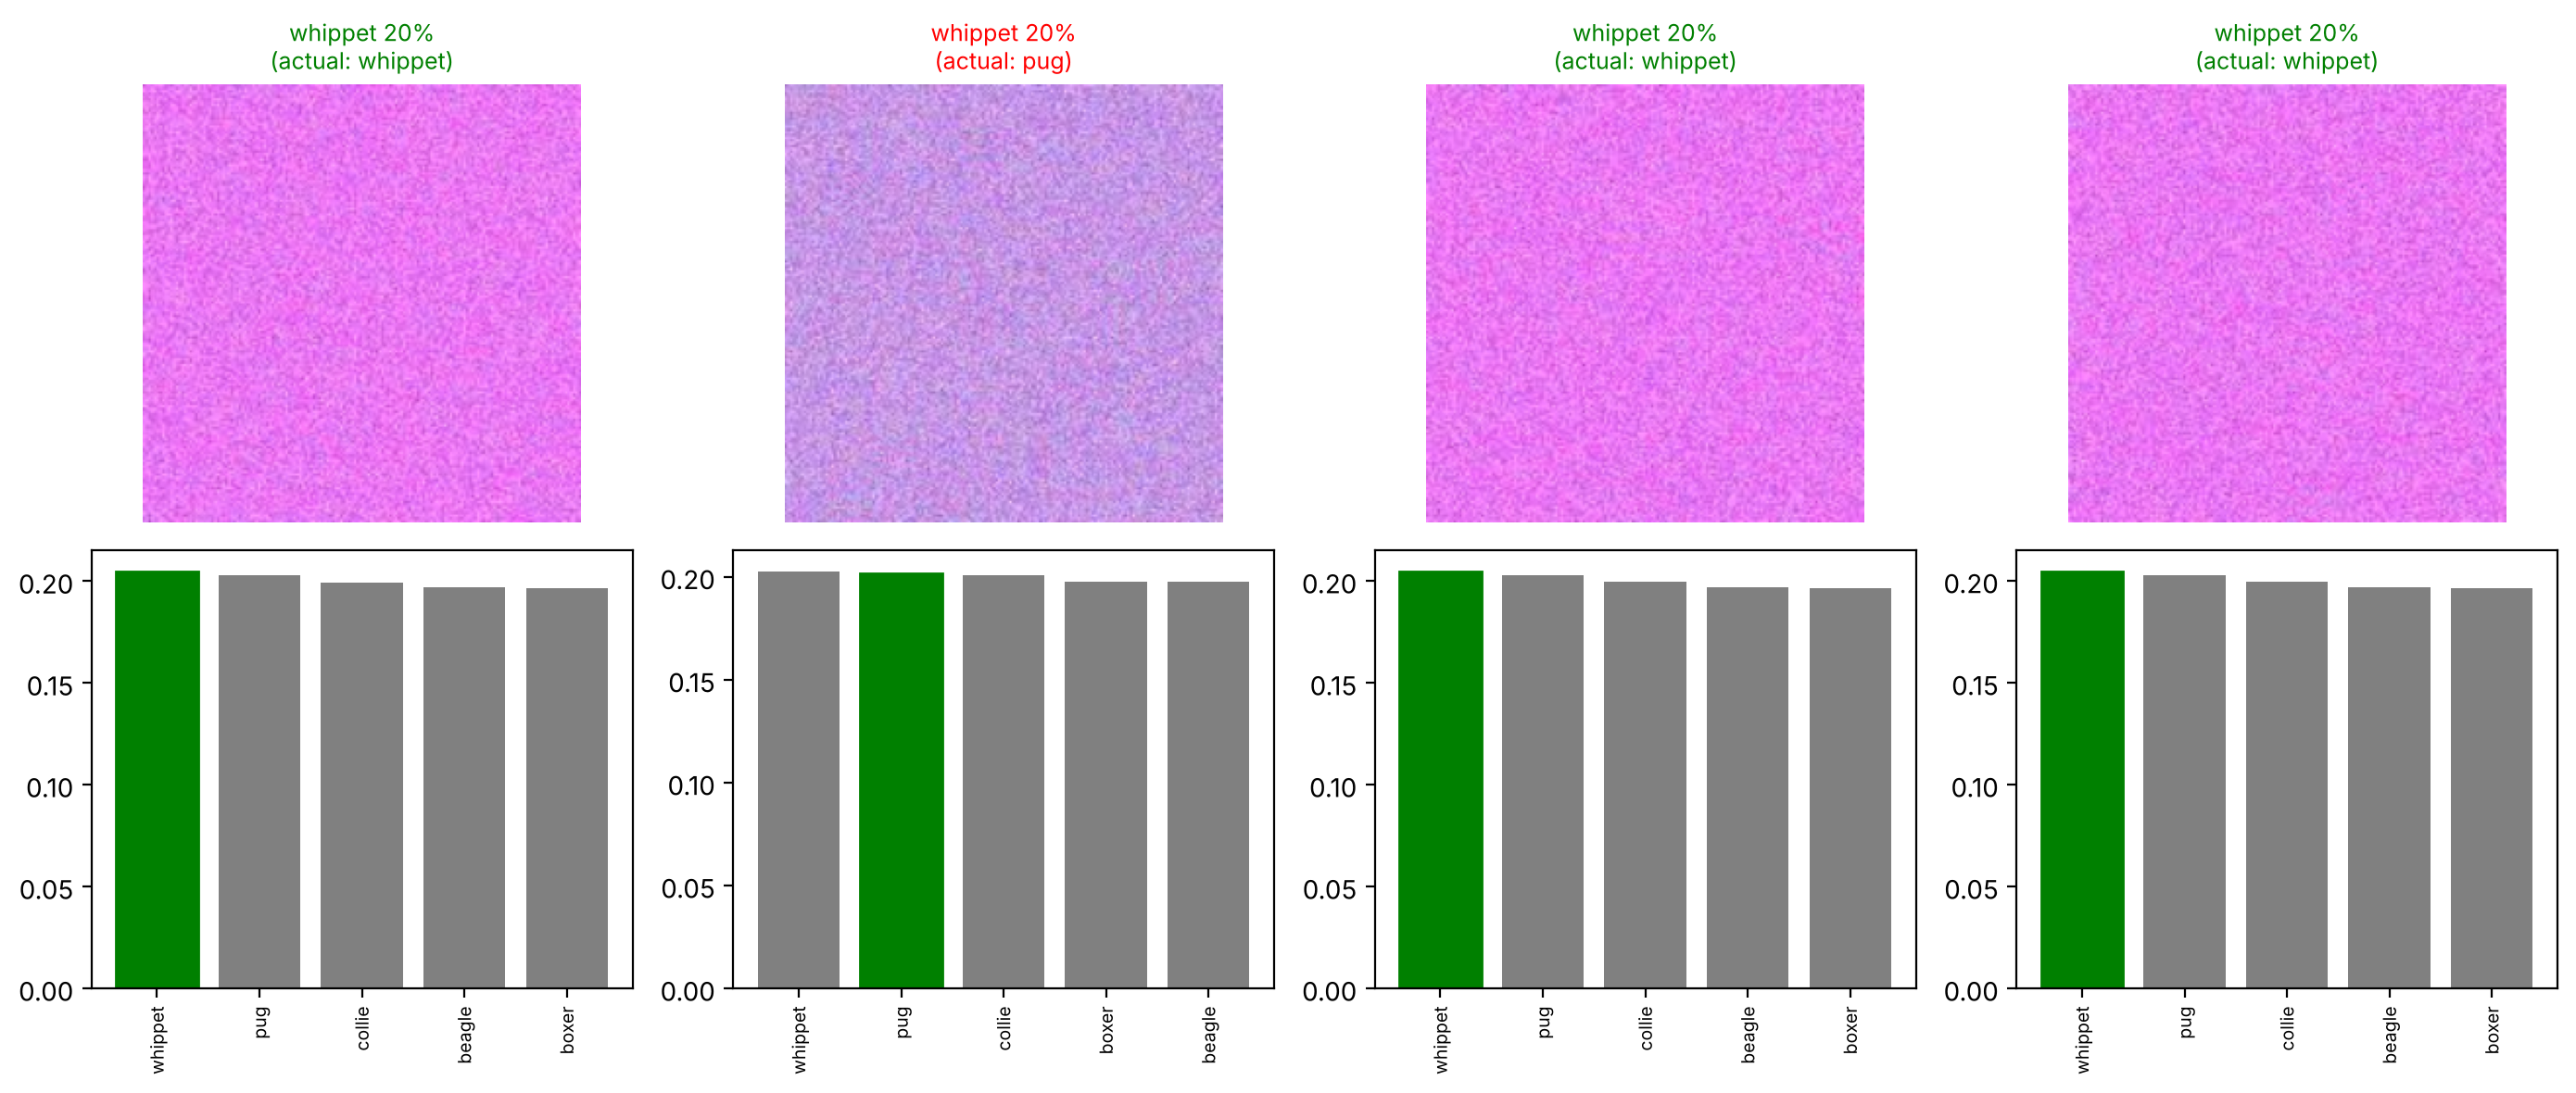

accuracy per class:
 boxer      0.0
pug        0.0
beagle     1.0
collie     1.0
whippet    1.0
dtype: float64


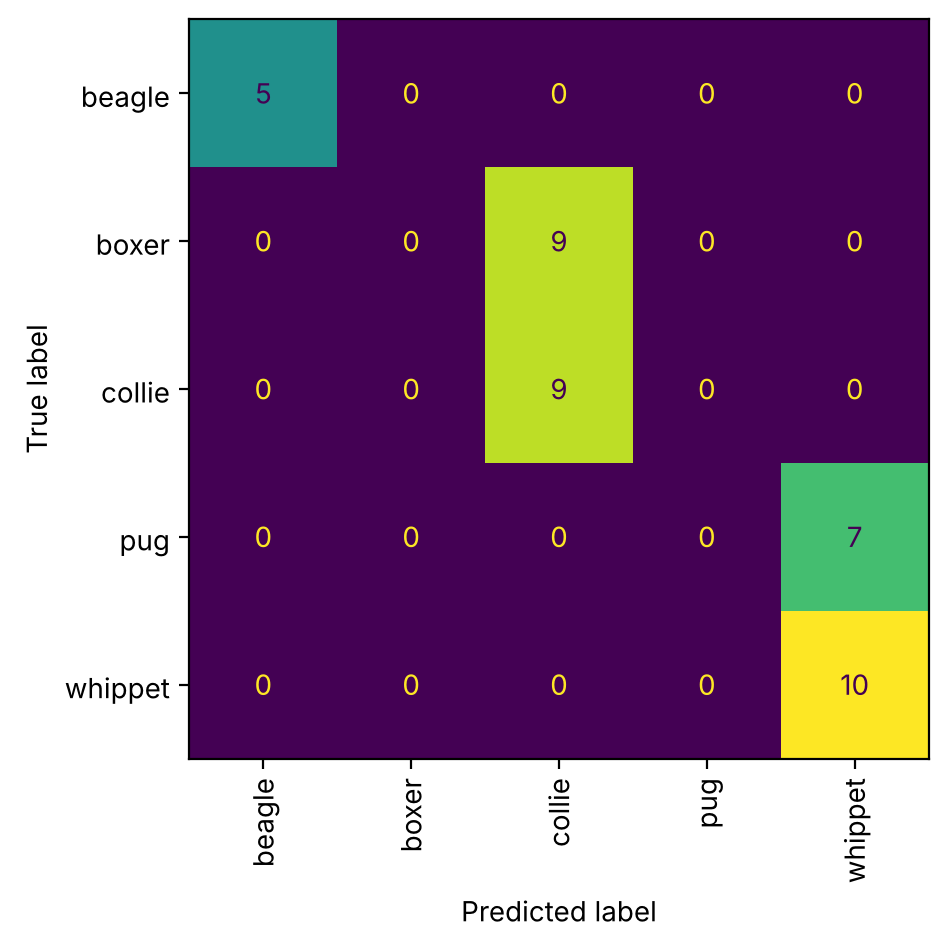

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay

images = np.concatenate([batch for batch, _ in valid_ds])
fig = plt.figure(figsize=(14, 6))
for i in range(min(4, len(images))):
    ax = fig.add_subplot(2, 4, i + 1)
    ax.imshow(images[i].astype("uint8")); ax.axis("off")
    colour = "green" if y_pred[i] == y_true[i] else "red"
    ax.set_title(f"{class_names[y_pred[i]]} {pred_probs[i].max():.0%}\n(actual: {class_names[y_true[i]]})",
                 color=colour, fontsize=9)
    top = np.argsort(pred_probs[i])[::-1][:10]
    ax2 = fig.add_subplot(2, 4, i + 5)
    bars = ax2.bar(range(len(top)), pred_probs[i][top], color="grey")
    if y_true[i] in top:
        bars[list(top).index(y_true[i])].set_color("green")
    ax2.set_xticks(range(len(top)), [class_names[t] for t in top], rotation=90, fontsize=7)
plt.tight_layout(); plt.show()

per_class = pd.Series(y_pred == y_true).groupby(y_true).mean().rename(index=dict(enumerate(class_names)))
print("accuracy per class:\n", per_class.round(2).sort_values().head())
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names, xticks_rotation=90,
                                        colorbar=False)
plt.show()

<a id="saving-loading-and-predicting-on-new-images"></a>

### Saving, Loading and Predicting on New Images

Save the trained model in Keras 3's single-file `.keras` format, then reload it and confirm it produces identical
predictions. (The older `.h5` format is legacy.)

In [67]:
import tensorflow as tf

model_path = "dog-vision-model.keras"
model.save(model_path)
loaded_model = tf.keras.models.load_model(model_path)
print("Loaded model gives identical predictions:",
      np.allclose(loaded_model.predict(valid_ds.take(1), verbose=0), model.predict(valid_ds.take(1), verbose=0)))

Loaded model gives identical predictions: True


Competitions such as Kaggle's *Dog Breed Identification* expect one row per test image, with an `id` column plus one
probability column per breed:

In [68]:
# Kaggle-style submission: one row per image, one probability column per class.
image_ids = [f"image_{i}" for i in range(len(pred_probs))]       # with Kaggle data: the test file names
submission = pd.DataFrame(pred_probs, columns=class_names)
submission.insert(0, "id", image_ids)
submission.to_csv("dog-vision-submission.csv", index=False)
print(submission.iloc[:3, :6].round(3))

        id  beagle  boxer  collie    pug  whippet
0  image_0   0.197  0.196   0.199  0.203    0.205
1  image_1   0.198  0.198   0.201  0.202    0.203
2  image_2   0.197  0.196   0.199  0.203    0.205


The final test is your own photos. Load each file, resize it to the model's input size, stack the images into a batch, and
predict. One of the four test images is a person, which is a useful reminder that a classifier always answers with one of
the classes it knows, however unlike them the input is. Production systems usually add an "unknown" class or a confidence
threshold.

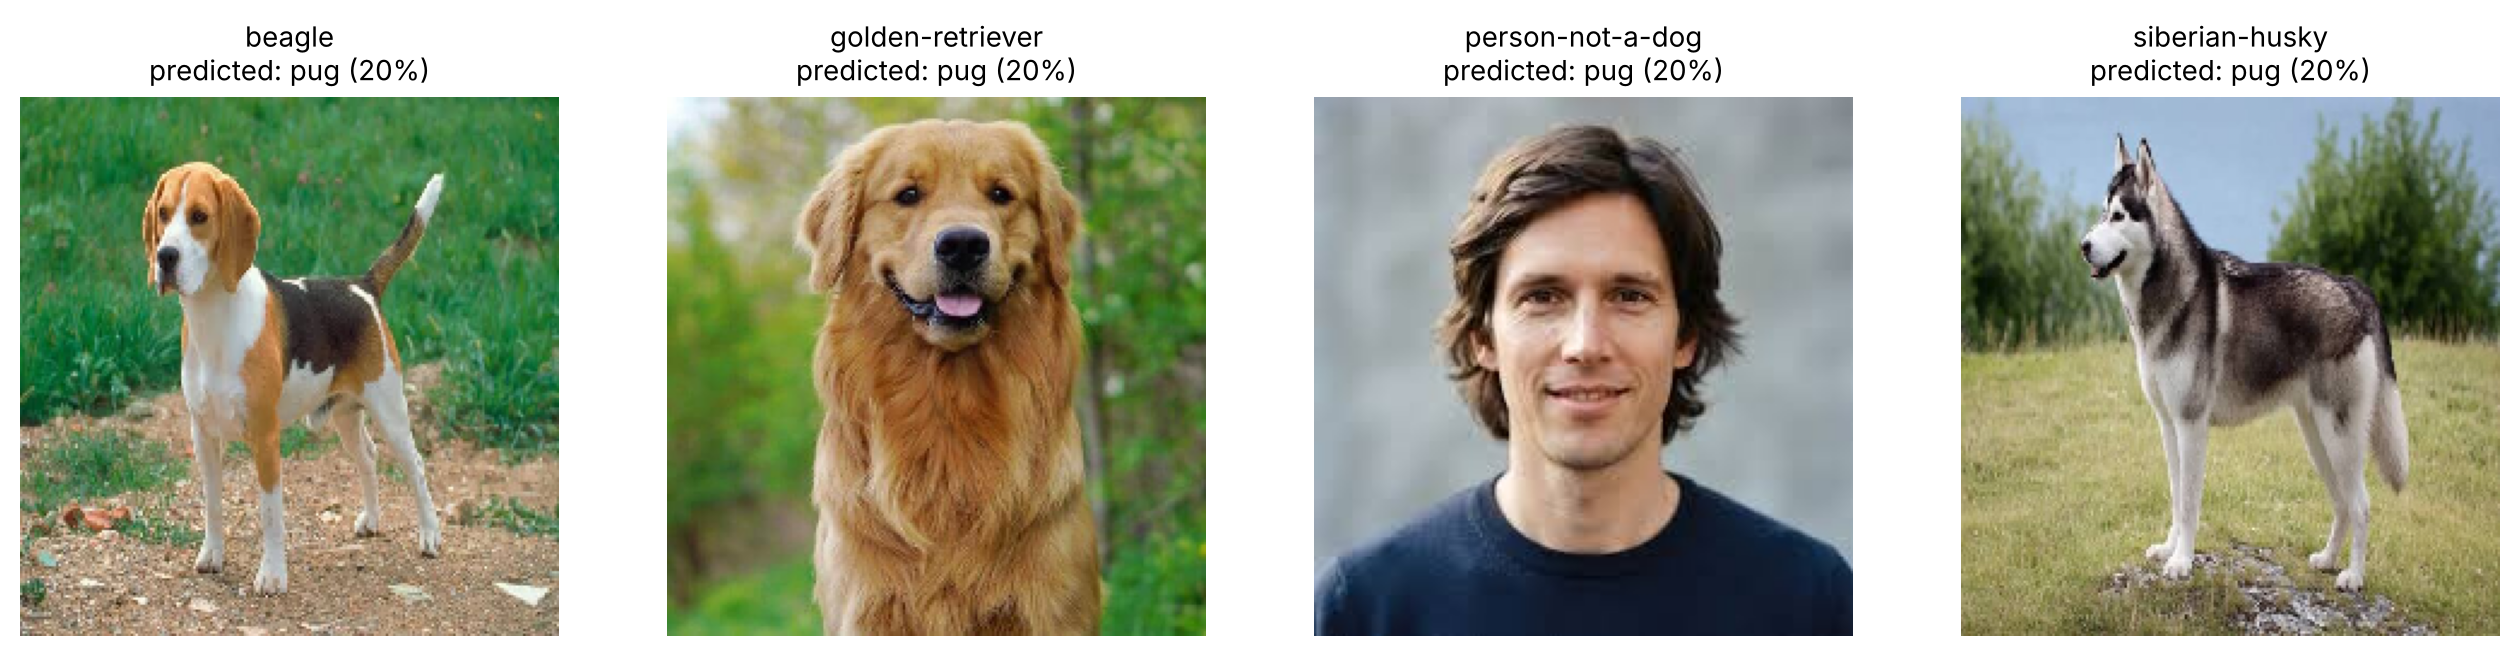

beagle.jpeg              -> pug (20%)
golden-retriever.jpeg    -> pug (20%)
person-not-a-dog.jpeg    -> pug (20%)
siberian-husky.jpeg      -> pug (20%)


In [69]:
import tensorflow as tf

custom_paths = sorted((DATA / "dog-photos").glob("*.jpeg"))     # beagle, golden-retriever, person-not-a-dog, ...
custom_images = np.stack([tf.keras.utils.img_to_array(tf.keras.utils.load_img(p, target_size=IMG_SIZE))
                          for p in custom_paths])                 # (n, 224, 224, 3), values 0-255
custom_preds = loaded_model.predict(custom_images, verbose=0)

fig, axes = plt.subplots(1, len(custom_paths), figsize=(4 * len(custom_paths), 4.3))
for ax, path, img, probs in zip(np.atleast_1d(axes), custom_paths, custom_images, custom_preds):
    ax.imshow(img.astype("uint8")); ax.axis("off")
    ax.set_title(f"{path.stem}\npredicted: {get_pred_label(probs)} ({probs.max():.0%})", fontsize=10)
plt.show()
for path, probs in zip(custom_paths, custom_preds):
    print(f"{path.name:24s} -> {get_pred_label(probs)} ({probs.max():.0%})")

#### Exercise 6

Add **data augmentation** (random horizontal flips, small rotations and zoom) that applies only during training. Put an
augmentation block in front of the base model, rebuild, and train for the same number of epochs.

#### Solution 6

*Try it yourself before running this cell.*

In [70]:
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")                 # active in fit(), automatically disabled in predict()/evaluate()

base = create_model().layers[1]              # reuse the same (frozen) feature extractor
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = base(x, training=False)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
aug_model = tf.keras.Model(inputs, outputs)
aug_model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
aug_history = aug_model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, verbose=2)

ImageNet weights unavailable ( Exception ) - using untrained weights for a dry run.


Epoch 1/2


5/5 - 12s - 2s/step - accuracy: 0.2313 - loss: 1.6081 - val_accuracy: 0.3000 - val_loss: 1.6032


Epoch 2/2


5/5 - 3s - 621ms/step - accuracy: 0.4000 - loss: 1.6001 - val_accuracy: 0.3000 - val_loss: 1.5962


<a id="cheatsheet-tensorflow-and-keras"></a>

### Cheatsheet: TensorFlow and Keras

```python
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(path, label_mode="categorical",
    image_size=(224, 224), batch_size=32, validation_split=0.2, subset="both", seed=42)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
base = tf.keras.applications.EfficientNetV2B0(include_top=False, weights="imagenet", pooling="avg")
base.trainable = False
inputs = tf.keras.Input((224, 224, 3)); x = base(inputs, training=False)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x); model = tf.keras.Model(inputs, outputs)
model.compile(loss="categorical_crossentropy", optimizer=tf.keras.optimizers.Adam(1e-3), metrics=["accuracy"])
model.fit(train_ds, validation_data=valid_ds, epochs=10,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
model.predict(ds).argmax(axis=1); model.save("model.keras"); tf.keras.models.load_model("model.keras")
```

| Labels | Loss |
|---|---|
| one-hot (`label_mode="categorical"`) | `CategoricalCrossentropy` |
| integers (`label_mode="int"`) | `SparseCategoricalCrossentropy` |
| binary (single sigmoid output) | `BinaryCrossentropy` |

<a id="reference"></a>

## Reference

<a id="master-cheatsheet"></a>

### Master Cheatsheet

**The workflow:** problem → data → metric → features → model (train / validation / test) → experiment, then repeat.

```python
# pandas
df = pd.read_csv(path, parse_dates=["date"], low_memory=False)
df.info(); df.describe(); df.isna().sum(); df["col"].value_counts(); pd.crosstab(df.a, df.b)
df["col"] = df["col"].fillna(df["col"].median()); df = df.dropna(subset=["target"])
# NumPy
rng = np.random.default_rng(42); a.shape; a.reshape(-1, 1); a @ b; a.mean(axis=0); a.argmax(axis=1)
# Matplotlib
fig, ax = plt.subplots(figsize=(10, 6)); ax.scatter(x, y, c=labels); ax.set(title="...", xlabel="...")
# scikit-learn
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
pipe = Pipeline([("prep", ColumnTransformer([...])), ("model", RandomForestClassifier())]).fit(X_train, y_train)
cross_val_score(pipe, X, y, cv=5, scoring="f1"); classification_report(y_test, pipe.predict(X_test))
RandomizedSearchCV(pipe, {"model__n_estimators": [100, 200]}, n_iter=10, cv=5); dump(pipe, "model.joblib")
# Keras
base = tf.keras.applications.EfficientNetV2B0(include_top=False, pooling="avg"); base.trainable = False
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
```

| Problem | Start with | Metric |
|---|---|---|
| Tabular classification | logistic regression, random forest, gradient boosting | accuracy, precision / recall / F1, ROC AUC |
| Tabular regression | ridge, random forest, `HistGradientBoostingRegressor` | MAE, RMSE, R², RMSLE |
| Time-ordered data | the same, plus date features and a time-based split | as above |
| Images, text, audio | transfer learning with a pretrained network | accuracy, top-k accuracy |

| Old code | Current replacement |
|---|---|
| `load_boston()` | `fetch_california_housing()` |
| `plot_roc_curve`, `plot_confusion_matrix` | `RocCurveDisplay`, `ConfusionMatrixDisplay` |
| `max_features="auto"` | `"sqrt"` or `1.0` |
| `mean_squared_log_error(..., squared=False)` | `root_mean_squared_log_error` |
| `df.append(other)` | `pd.concat([df, other])` |
| `plt.style.use("seaborn")` | `plt.style.use("seaborn-v0_8")` |
| `hub.KerasLayer(...)`, `.h5` files | `tf.keras.applications`, `.keras` files |

<a id="glossary"></a>

### Glossary

| Term | Meaning |
|---|---|
| **Accuracy** | share of predictions that are correct |
| **AUC / ROC curve** | area under / plot of true-positive vs false-positive rate across thresholds |
| **Batch** | group of samples processed together in one training step |
| **Callback** | function Keras runs during training (early stopping, logging) |
| **Classification / regression** | predicting a category / a number |
| **Confusion matrix** | table of true vs predicted labels |
| **Cross-validation** | evaluating on several train/test splits and averaging |
| **Epoch** | one full pass over the training data |
| **Estimator** | scikit-learn's word for a model |
| **Feature / target** | input variable / what you predict |
| **Feature engineering** | creating new features from existing data |
| **Gradient descent** | adjusting parameters step by step in the direction that reduces the loss |
| **Hyperparameter** | a setting you choose before training |
| **Imputation** | filling missing values |
| **One-hot encoding** | one 0/1 column per category |
| **Overfitting / underfitting** | memorizing the training data / failing to learn its patterns |
| **Pipeline** | preprocessing steps and a model fitted as one object |
| **Precision / recall / F1** | correctness of positive predictions / coverage of actual positives / their harmonic mean |
| **R², MAE, RMSE, RMSLE** | variance explained, mean absolute error, root mean squared (log) error |
| **Softmax** | turns outputs into probabilities that sum to 1 |
| **Tensor** | multi-dimensional array that can run on a GPU |
| **Train / validation / test set** | data to learn from / to tune on / for the final evaluation |
| **Transfer learning** | reusing a model trained on one problem for another |

<a id="further-reading"></a>

### Further Reading

- [Data Preparation for Machine Learning reference](https://github.com/rokon-uddin/data-preparation-reference), my
  deep dive on cleaning, feature selection and transforms
- [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html) ·
  [NumPy user guide](https://numpy.org/doc/stable/user/index.html) ·
  [Matplotlib quick start](https://matplotlib.org/stable/users/explain/quick_start.html)
- [scikit-learn user guide](https://scikit-learn.org/stable/user_guide.html) ·
  [choosing the right estimator](https://scikit-learn.org/stable/machine_learning_map.html) ·
  [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [TensorFlow transfer-learning tutorial](https://www.tensorflow.org/tutorials/images/transfer_learning) ·
  [Keras applications](https://keras.io/api/applications/)
- Datasets: [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease) ·
  [Blue Book for Bulldozers](https://www.kaggle.com/c/bluebook-for-bulldozers) ·
  [Stanford Dogs](http://vision.stanford.edu/aditya86/ImageNetDogs/)